# mini-vLLM, Part 11: The Engine

**What we will build and measure**

Parts (notebooks) 1 to 10 were experiments. Each had its own loop: a cache here, a scheduler there, a graph decoder for one sequence, a speculative decoder for one sequence. None of them was a server. A server needs one object that owns the model and its KV memory, accepts requests whenever they arrive, and returns tokens as it makes them. This part puts the pieces behind one interface and then measures the result the way a user would see it: requests arriving over time on a real clock, time to first token, time per token, and throughput, against Hugging Face `generate` on the same trace.

1. **`LLMEngine`** (`minivllm/llm_engine.py`). A waiting queue and first come first served admission on the paged cache of Part 4, with the reservation rule that guarantees nothing is ever preempted. Each step admits and prefills what fits and then runs one decode step for all running requests, each at its own position. Per-request sampling (`minivllm/sampling.py`: greedy, temperature, top-k, top-p, a seed per request, stop tokens) and early release of a finished request's blocks.
2. **A decode step that can live in a CUDA graph** (`minivllm/paged_graph.py`). Part 9 captured one sequence on a static cache. A batch of changing requests needs two more ideas: **buckets** (one graph per batch size and per number of blocks per sequence, rounded up) and a **fixed-width gather** through a block table that is a static buffer, with padding rows that write only into a reserved block. Without a GPU the same step runs eagerly, so the logic is tested on a CPU (`tests/test_paged_graph.py`).
3. **Lookup speculation in latency mode.** When exactly one greedy request is running, a step guesses up to `k` tokens by n-gram lookup in the request's own context (Part 5), checks them in one pass of `k + 1` tokens over the paged cache, keeps the agreeing prefix plus one token, and rolls back by not advancing a length. With two or more requests the engine decodes the batch as usual: a batch already shares each read of the weights across its rows.
4. **A small server** (`minivllm/server.py`). Standard library HTTP, one engine thread, `POST /v1/completions` with optional streaming, a client that disconnects has its request aborted.
5. **A load generator** (`bench/load.py`). Open-loop Poisson arrivals on a real clock from the same workload generator as Parts 3 and 4, one driver per system (the engine in process, any streaming server over HTTP, Hugging Face `generate` sequential or in static batches), and one summary: TTFT, time per output token, response time, stalls, request and token throughput, and goodput under a latency target.

**What this notebook does not do.** It does not compare with vLLM. vLLM brings its own pinned PyTorch, so it runs in a separate environment and a separate notebook (`99_vllm_compare.ipynb`), which drives this repo's server and vLLM's over HTTP with the same client and the same trace in one session. The numbers of this notebook are the engine against Hugging Face and against itself.

**How to use this notebook.** Same shape as the earlier parts: *Goal, Concept, Code, Result, Takeaway*, with a prediction written down before every benchmark. The "how to read it" notes are written before the numbers exist. The numbers come from your run.

| # | Section | What we learn | Runtime on a Kaggle T4 (full run) |
| --- | --- | --- | --- |
| 0 | Setup | Reproducible environment, the whole package | under a minute |
| 1 | Models and traces | The same trace for every system, proved by a digest | about half a minute (model downloads) |
| 2 | Correctness first | Does the engine produce the tokens of plain decoding in every mode, and can the check fail? | about 3 minutes |
| 3 | Engine modes under load | Eager paged decode, the bucketed static step, the same step in CUDA graphs | about 5 minutes |
| 4 | Engine against Hugging Face | The same trace at four arrival rates | about 41 minutes (Hugging Face saturates, so its runs are long) |
| 5 | Latency mode | One request at a time: plain, graph, graph with lookup speculation, Hugging Face | about 10 minutes |
| 6 | The server | The engine behind HTTP in its own process, streamed output | about 1 minute |
| 7 | Save and publish | JSON, figure inventory, GitHub | seconds |
| 8 | Lessons | Summary, questions, exercises | seconds |

The whole notebook took about an hour.

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a pass with the 0.5B model only, fewer requests and two rates.

**Self-contained.** Like the earlier parts, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them.

---
## 0. Setup

**Goal:** one imports cell, one environment record, then the package.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `QUICK = True` shrinks the run: one model, fewer requests, two rates.
- After editing a `%%writefile` cell, re-run it and then restart the kernel, because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, json, platform, random, subprocess, sys, time, urllib.request

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: the 0.5B model only, fewer requests, two rates
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.11.0+cu128', 'transformers': '5.16.1', 'python': '3.13.15'}


### The package

What is new in this part (everything else is repeated verbatim from Part 10):

| File | What it is |
| --- | --- |
| `minivllm/sampling.py` | `SamplingParams` and the batched sampler: greedy, temperature, top-k, top-p, a generator per request. |
| `minivllm/llm_engine.py` | `LLMEngine`: queue, admission, prefill, batched decode, sampling, stop tokens, timestamps; graph decode and lookup speculation as options. |
| `minivllm/paged_graph.py` | The bucketed static decode step over the paged cache, its CUDA-graph capture, and the checking pass of speculation. |
| `minivllm/server.py` | The HTTP server (`python -m minivllm.server`). |
| `bench/load.py` | Traces, open-loop runners for the engine, a server and Hugging Face, and the summary. |
| `bench/compare_vllm.py` | Starting and stopping a server subprocess, and the vLLM environment (used by `99_vllm_compare.ipynb`). |

In [2]:
%%writefile bench/compare_vllm.py
"""
Running vLLM next to the engine, on the same trace (Part of the head-to-head comparison; see bench/load.py for the traces and the metrics).

vLLM is a large package with its own pinned torch, so it lives in its own virtual environment and runs as its own OpenAI-compatible server
process; the load generator talks to it over HTTP exactly as it talks to this repo's server. Nothing here imports vllm.

  install_vllm(venv, version)    create the environment with uv and install vllm (a version, or None for the newest) into it
  vllm_versions(python)          the versions of vllm and torch inside the environment
  VllmServer(python, model, ...) start `vllm.entrypoints.openai.api_server`, wait until it answers /health, stop it (and its children)
  publish_results(...)           push only the named results files to the repo (the vLLM notebook is outside the stage chain, so it must never
                                 publish code)
  start_first_that_works(...)    try several environment settings in turn (a T4 is a Turing GPU: newer vLLM releases may need a different
                                 attention backend, or may not support it at all) and report every failed attempt with the tail of its log

Everything that can fail records why. A comparison that could not run vLLM says so in its results instead of leaving the column empty.
"""
import os
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request
from pathlib import Path


class VllmStartError(RuntimeError):
    def __init__(self, message, log_tail=""):
        super().__init__(message)
        self.log_tail = log_tail


def _tail(path, lines=40):
    try:
        return "\n".join(Path(path).read_text(errors="replace").splitlines()[-lines:])
    except OSError:
        return ""


# ---- the environment ----------------------------------------------------------------------------------------------

TORCH_BACKEND = "--torch-backend=auto"      # uv picks the PyTorch wheel index that matches the CUDA driver (vLLM's install page uses it)


def venv_python(venv):
    return str(Path(venv) / "bin" / "python")


def install_commands(venv, version=None, extra_pip=(), python="3.12"):
    """
    The commands that create `venv` and install vllm into it (a list of argv lists, run in order). The environment is made by uv, as
    vLLM's own install page does, and not by `python -m venv`: the system Python of a Kaggle image has no working ensurepip, so `venv`
    fails there before anything is installed. uv fetches the interpreter `python` when it is missing (None: the one running this).
    """
    spec = "vllm" if not version else f"vllm=={version}"
    uv = [sys.executable, "-m", "uv"]
    return [[sys.executable, "-m", "pip", "install", "--quiet", "uv"],
            [*uv, "venv", str(venv), *(["--python", python] if python else [])],
            [*uv, "pip", "install", "--python", venv_python(venv), TORCH_BACKEND, spec, *extra_pip]]


def install_vllm(venv, version=None, log_path="vllm_install.log", extra_pip=(), timeout_s=3600, run=subprocess.run):
    """
    Create the environment and install vllm. Returns {"ok", "python", "version_asked", "seconds", "error", "torch_backend"}; never raises for a
    failed install (the notebook records it and carries on without vLLM). The full install output goes to `log_path`. If the install fails
    with uv's torch-backend choice (the PyTorch index may be unreachable), it is retried once with the default torch wheels from PyPI, which
    are the ones vLLM is built against; `torch_backend` says which one produced the environment.
    """
    t0 = time.time()
    info = dict(ok=False, python=venv_python(venv), version_asked=version, seconds=None, error=None, torch_backend="auto")
    with open(log_path, "w") as log:
        for cmd in install_commands(venv, version, extra_pip):
            try:
                r = run(cmd, stdout=log, stderr=subprocess.STDOUT, timeout=timeout_s)
                if r.returncode != 0 and TORCH_BACKEND in cmd:
                    log.write(f"\n[the install failed with {TORCH_BACKEND}; trying again with the default torch wheels]\n")
                    log.flush()
                    cmd, info["torch_backend"] = [c for c in cmd if c != TORCH_BACKEND], "default"
                    r = run(cmd, stdout=log, stderr=subprocess.STDOUT, timeout=timeout_s)
            except subprocess.TimeoutExpired:
                info["error"] = f"timed out after {timeout_s} s running {' '.join(cmd[:4])} ..."
                break
            if r.returncode != 0:
                info["error"] = f"`{' '.join(cmd[:5])} ...` exited with {r.returncode}: {_tail(log_path, 12)}"
                break
        else:
            info["ok"] = True
    info["seconds"] = time.time() - t0
    return info


def vllm_versions(python, run=subprocess.run):
    """{"vllm": ..., "torch": ...} as seen from inside the environment, or {"error": ...}."""
    r = run([python, "-c", "import json, torch, vllm; print(json.dumps({'vllm': vllm.__version__, 'torch': torch.__version__}))"],
            capture_output=True, text=True, timeout=300)
    if r.returncode != 0:
        return {"error": (r.stderr or r.stdout).strip().splitlines()[-1] if (r.stderr or r.stdout).strip() else f"exit {r.returncode}"}
    import json
    return json.loads(r.stdout.strip().splitlines()[-1])


# ---- the server -----------------------------------------------------------------------------------------------------

def server_command(python, model, port, max_model_len=2048, gpu_memory_utilization=0.85, dtype="half", extra_args=()):
    """The command line of vLLM's OpenAI-compatible server."""
    return [python, "-m", "vllm.entrypoints.openai.api_server", "--model", model, "--port", str(port), "--dtype", dtype,
            "--max-model-len", str(max_model_len), "--gpu-memory-utilization", str(gpu_memory_utilization), *extra_args]


class ServerProcess:
    """
    Any HTTP server run as a subprocess that answers GET /health when it is ready: vLLM's, or this repo's (`python -m minivllm.server`), so
    both are launched, waited for and stopped the same way and are driven by the same client. The process is started in its own session, so
    stop() ends the server and any worker processes it spawned.
    """
    def __init__(self, command, port, model="model", env=None, log_path="server.log"):
        self.command, self.model, self.port, self.log_path, self.env = list(command), model, port, log_path, env or {}
        self.proc = None

    @property
    def url(self):
        return f"http://127.0.0.1:{self.port}"

    def _healthy(self):
        try:
            with urllib.request.urlopen(f"{self.url}/health", timeout=2) as r:
                return r.status == 200
        except (urllib.error.URLError, OSError):
            return False

    def start(self, timeout_s=900, poll_s=1.0):
        """Launch the process and wait until /health answers. Raises VllmStartError (with the end of the log) if it exits or times out."""
        log = open(self.log_path, "w")
        self.proc = subprocess.Popen(self.command, stdout=log, stderr=subprocess.STDOUT, env={**os.environ, **self.env}, start_new_session=True)
        log.close()
        t0 = time.time()
        while time.time() - t0 < timeout_s:
            code = self.proc.poll()
            if code is not None:
                raise VllmStartError(f"the server exited with code {code} before it was ready", _tail(self.log_path))
            if self._healthy():
                self.ready_s = time.time() - t0
                return self
            time.sleep(poll_s)
        self.stop()
        raise VllmStartError(f"the server was not ready after {timeout_s} s", _tail(self.log_path))

    def stop(self, grace_s=20.0):
        if self.proc is None or self.proc.poll() is not None:
            return
        try:
            os.killpg(os.getpgid(self.proc.pid), signal.SIGTERM)
            self.proc.wait(timeout=grace_s)
        except (subprocess.TimeoutExpired, ProcessLookupError, PermissionError):
            try:
                os.killpg(os.getpgid(self.proc.pid), signal.SIGKILL)
            except (ProcessLookupError, PermissionError):
                pass
            self.proc.wait(timeout=grace_s)

    def __enter__(self):
        return self.start()

    def __exit__(self, *exc):
        self.stop()


class VllmServer(ServerProcess):
    """A vLLM server process. `command` replaces the default command line (the tests start a stand-in server that way)."""
    def __init__(self, python, model, port=8001, max_model_len=2048, gpu_memory_utilization=0.85, dtype="half", extra_args=(), env=None,
                 log_path="vllm_server.log", command=None):
        super().__init__(command or server_command(python, model, port, max_model_len, gpu_memory_utilization, dtype, extra_args), port, model, env, log_path)


def start_first_that_works(python, model, attempts, port=8001, timeout_s=900, log_dir=".", **server_kw):
    """
    Start a server with the first of `attempts` (dicts with a "name" and optional "env" and "extra_args") that comes up. Returns
    (server, record) where record lists every attempt: its name, whether it started, how long that took, and for failures the error and
    the end of the log. server is None if none worked.
    """
    record = []
    for i, a in enumerate(attempts):
        srv = VllmServer(python, model, port=port, env=a.get("env"), extra_args=a.get("extra_args", ()),
                         log_path=str(Path(log_dir) / f"vllm_server_{i}.log"), **server_kw)
        t0 = time.time()
        try:
            srv.start(timeout_s=timeout_s)
            record.append(dict(name=a["name"], ok=True, seconds=time.time() - t0, env=a.get("env", {}), extra_args=list(a.get("extra_args", ()))))
            return srv, record
        except VllmStartError as e:
            record.append(dict(name=a["name"], ok=False, seconds=time.time() - t0, error=str(e), log_tail=e.log_tail,
                               env=a.get("env", {}), extra_args=list(a.get("extra_args", ()))))
            srv.stop()
    return None, record


# ---- publishing -----------------------------------------------------------------------------------------------------

def publish_results(token, message, files, results_dir="results", repo=None, clone="mini-vllm-results", url=None, name=None, email=None):
    """
    Clone the repo (if needed), pull, copy ONLY the named files of `results_dir` into its results/ folder, commit and push. Unlike
    bench.publish.publish this never touches minivllm/ or bench/ or the stage stamp: a notebook outside the numbered series (this comparison)
    has no stage, and an old copy of the code must not overwrite newer code. `url` replaces the GitHub URL (the tests use a local bare repository).
    """
    import shutil
    from bench.publish import GIT_EMAIL, GIT_NAME, REPO, _run
    repo, name, email = repo or REPO, name or GIT_NAME, email or GIT_EMAIL
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"

    def git(*args):
        return _run(["git", *args], cwd=clone, secret=token, show=True)

    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=True)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    (clone / "results").mkdir(exist_ok=True)
    for f in files:
        shutil.copy2(Path(results_dir) / f, clone / "results" / f)
    git("add", "-A")
    if _run(["git", "status", "--porcelain"], cwd=clone, secret=token).strip():
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")
    return dict(pushed=True, files=list(files))

Writing bench/compare_vllm.py


In [3]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [4]:
%%writefile bench/load.py
"""
Load generation for comparing serving systems on the same trace (the engine, Hugging Face `generate`, vLLM).

A trace is a list of `minivllm.scheduler.Request` (prompt token ids, tokens to generate, arrival time in seconds from the run start),
built by the same `make_requests` and `with_arrivals` as the load sweeps of Stages 4 and 5, so a trace is fixed by (workload, n, rate,
seeds) and `trace_digest` proves two runs used the same one. Load is OPEN LOOP: a request is sent at its arrival time whether or not the
system has finished the earlier ones, which is what makes a slow system's queue grow the way it would under real traffic. (A closed loop,
where a client waits for its reply before sending the next request, hides overload.)

Every system is driven to the same contract and produces `RequestResult`s on the same clock:

  run_engine(engine, trace)           the LLMEngine in process, one thread: add the requests that have arrived, step, repeat.
  run_http(url, trace)                any server with a streaming /v1/completions (the engine's own server, vLLM's): one thread per
                                      request sleeps until its arrival, sends it, and timestamps every server-sent event.
  run_hf(model, trace, max_batch)     Hugging Face `generate`: requests that have arrived are served first come first served, up to
                                      `max_batch` at once (1 is sequential serving, more is static batching: left padded, running until
                                      the longest request in the batch has its tokens). A streamer timestamps every step. Generous to
                                      Hugging Face: a request counts as finished at its own last token, not when its batch returns.

Every request generates exactly its `max_new` tokens (no stopping on the end-of-sequence token), so all systems do the same work.

`summarize` reduces results to time to first token (TTFT), time per output token (TPOT, what a reader of the stream experiences), response
time, the longest stall between two events of a stream, request and token throughput, and goodput: tokens of the requests that met a
latency target, per second of the run.
"""
import hashlib
import http.client
import json
import threading
import time
from collections import deque
from dataclasses import dataclass, field
from typing import List, Optional, Tuple
from urllib.parse import urlparse

from bench.metrics import pct
from bench.workload import WORKLOADS, make_requests, with_arrivals


# ---- traces -----------------------------------------------------------------------------------------------------------

def make_trace(workload="mixed", n=48, rate=2.0, seed=0, arrival_seed=1, vocab=(1000, 20000)):
    """
    n requests of a named workload (bench.workload.WORKLOADS, or a dict of its keys) with Poisson arrivals at `rate` requests per second
    (rate None or 0: all arrive at time 0). Random token ids stand in for text, which every system accepts as token ids.
    """
    spec = WORKLOADS[workload] if isinstance(workload, str) else workload
    reqs = make_requests(n, seed=seed, vocab=vocab, **spec)
    return with_arrivals(reqs, rate, seed=arrival_seed) if rate else reqs


def trace_digest(trace):
    """A short hash of everything that defines a trace, to record that two runs (two notebooks, two machines) used the same one."""
    h = hashlib.sha1()
    for r in trace:
        h.update(json.dumps([r.id, round(r.arrival_s, 6), r.max_new, list(r.prompt_ids)]).encode())
    return h.hexdigest()[:12]


def trace_info(trace):
    lens = [len(r.prompt_ids) for r in trace]
    return dict(n=len(trace), digest=trace_digest(trace), prompt_tokens=sum(lens), output_tokens=sum(r.max_new for r in trace),
                mean_prompt=sum(lens) / len(lens), max_prompt=max(lens), arrival_span_s=max(r.arrival_s for r in trace) - min(r.arrival_s for r in trace))


# ---- results ----------------------------------------------------------------------------------------------------------

@dataclass
class RequestResult:
    """Times are seconds from the run start. `chunks` is [(time, tokens in this event)]: the tokens of one engine step arrive together."""
    id: int
    arrival_s: float
    prompt_len: int
    max_new: int
    n_tokens: int = 0
    first_token_s: Optional[float] = None
    finish_s: Optional[float] = None
    chunks: List[Tuple[float, int]] = field(default_factory=list)
    error: Optional[str] = None

    @property
    def ok(self):
        return self.error is None and self.finish_s is not None and self.first_token_s is not None

    @property
    def ttft_s(self):
        return self.first_token_s - self.arrival_s

    @property
    def e2e_s(self):
        return self.finish_s - self.arrival_s

    @property
    def tpot_s(self):
        """Seconds per output token after the first, as a reader of the stream sees them (None for a one-token output)."""
        return (self.finish_s - self.first_token_s) / (self.n_tokens - 1) if self.n_tokens > 1 else None

    @property
    def stalls_s(self):
        """The gaps between consecutive events of the stream."""
        return [b[0] - a[0] for a, b in zip(self.chunks, self.chunks[1:])]


def summarize(results, slo=None):
    """
    The numbers of one run. `slo` is a dict with `ttft_s` and/or `tpot_s` limits: a request meets it when it is within every limit given,
    and goodput counts only the tokens of requests that do (None: goodput is None). All rates are per second of the run's span, which runs
    from the first arrival to the last finish.
    """
    ok = [r for r in results if r.ok]
    out = dict(n_requests=len(results), n_ok=len(ok), n_errors=len(results) - len(ok))
    if not ok:
        return out
    span = max(r.finish_s for r in ok) - min(r.arrival_s for r in results)
    tpot = [r.tpot_s for r in ok if r.tpot_s is not None]
    stalls = [g for r in ok for g in r.stalls_s]
    ttft, e2e = [r.ttft_s for r in ok], [r.e2e_s for r in ok]
    nan = float("nan")
    out.update(
        span_s=span,
        req_s=len(ok) / span,
        out_tok_s=sum(r.n_tokens for r in ok) / span,
        ttft_p50_s=pct(ttft, 50), ttft_p99_s=pct(ttft, 99), ttft_mean_s=sum(ttft) / len(ttft),
        tpot_p50_s=pct(tpot, 50) if tpot else nan, tpot_p99_s=pct(tpot, 99) if tpot else nan,
        e2e_p50_s=pct(e2e, 50), e2e_p99_s=pct(e2e, 99), e2e_mean_s=sum(e2e) / len(e2e),
        stall_p99_s=pct(stalls, 99) if stalls else nan, stall_max_s=max(stalls) if stalls else nan,
    )
    if slo:
        def meets(r):
            return (r.ttft_s <= slo.get("ttft_s", float("inf"))) and (r.tpot_s is None or r.tpot_s <= slo.get("tpot_s", float("inf")))
        good = [r for r in ok if meets(r)]
        out.update(slo=dict(slo), slo_attainment=len(good) / len(results), goodput_tok_s=sum(r.n_tokens for r in good) / span)
    else:
        out.update(slo=None, slo_attainment=None, goodput_tok_s=None)
    return out


def _group(times):
    """[(t, count)] from a list of per-token times: tokens that share a timestamp arrived in one event."""
    chunks = []
    for t in times:
        if chunks and chunks[-1][0] == t:
            chunks[-1][1] += 1
        else:
            chunks.append([t, 1])
    return [(t, n) for t, n in chunks]


# ---- the engine, in process ---------------------------------------------------------------------------------------------

def run_engine(engine, trace, sleep=time.sleep):
    """
    Drive an LLMEngine open loop on its own clock: before each step, add every request whose arrival time has come; when nothing is
    running, sleep until the next arrival. Arrival times are the scheduled ones (not the moment the loop noticed them), so a long step
    that delays admission counts against the engine's TTFT, as it would for a real client.
    """
    from minivllm.sampling import SamplingParams
    clock = engine.clock
    pending = deque(sorted(trace, key=lambda r: r.arrival_s))
    by_id = {r.id: r for r in trace}
    t0 = clock()
    while pending or engine.has_unfinished():
        now = clock() - t0
        while pending and pending[0].arrival_s <= now:
            r = pending.popleft()
            engine.add_request(r.prompt_ids, SamplingParams(max_new=r.max_new), request_id=r.id, arrival_s=t0 + r.arrival_s)
        if engine.has_unfinished():
            engine.step()
        elif pending:
            sleep(max(0.0, pending[0].arrival_s - (clock() - t0)))
    results = []
    for rid, r in by_id.items():
        o = engine.pop_output(rid)
        times = [t - t0 for t in o.token_times]
        results.append(RequestResult(id=rid, arrival_s=r.arrival_s, prompt_len=len(r.prompt_ids), max_new=r.max_new, n_tokens=len(o.tokens),
                                     first_token_s=times[0] if times else None, finish_s=o.finish_s - t0, chunks=_group(times),
                                     error=None if o.finish_reason in ("length", "stop") else f"finished with {o.finish_reason}"))
    return results


# ---- a server over HTTP -------------------------------------------------------------------------------------------------

def _stream_request(host, port, path, body, timeout, clock):
    """POST a streaming completion; returns ([(time, tokens in the event)], completion_tokens from the usage event or None)."""
    conn = http.client.HTTPConnection(host, port, timeout=timeout)
    try:
        conn.request("POST", path, body=json.dumps(body), headers={"Content-Type": "application/json"})
        resp = conn.getresponse()
        if resp.status != 200:
            raise RuntimeError(f"HTTP {resp.status}: {resp.read(300).decode(errors='replace')}")
        chunks, usage = [], None
        while True:
            line = resp.readline()
            if not line:
                break
            line = line.strip()
            if not line.startswith(b"data:"):
                continue
            payload = line[5:].strip()
            if payload == b"[DONE]":
                break
            now = clock()
            obj = json.loads(payload)
            if obj.get("error"):
                raise RuntimeError(str(obj["error"]))
            if obj.get("usage"):
                usage = obj["usage"].get("completion_tokens", usage)
            for ch in obj.get("choices") or []:
                n = len(ch["tokens"]) if "tokens" in ch else (1 if ch.get("text") else 0)       # this repo's server lists tokens; others send a text delta
                if n:
                    chunks.append((now, n))
        return chunks, usage
    finally:
        conn.close()


def run_http(url, trace, model="model", timeout=600.0, sleep=time.sleep, clock=time.perf_counter, extra=None):
    """
    Open-loop load over HTTP against a streaming /v1/completions (this repo's server, or vLLM's OpenAI-compatible server). One thread per
    request sleeps until its arrival time, sends token ids with temperature 0 and ignore_eos, and timestamps every event. The token count
    is the server's own `usage` when it sends one, else the number of events that carried text.
    """
    u = urlparse(url)
    t0 = clock()
    results = {r.id: RequestResult(id=r.id, arrival_s=r.arrival_s, prompt_len=len(r.prompt_ids), max_new=r.max_new) for r in trace}

    def worker(r):
        res = results[r.id]
        sleep(max(0.0, t0 + r.arrival_s - clock()))
        body = dict(model=model, prompt=list(r.prompt_ids), max_tokens=r.max_new, temperature=0, stream=True, ignore_eos=True,
                    stream_options={"include_usage": True}, **(extra or {}))
        try:
            chunks, usage = _stream_request(u.hostname, u.port, "/v1/completions", body, timeout, clock)
            chunks = [(t - t0, n) for t, n in chunks]
            res.chunks, res.n_tokens = chunks, usage if usage is not None else sum(n for _, n in chunks)
            res.first_token_s = chunks[0][0] if chunks else None
            res.finish_s = clock() - t0 if not chunks else chunks[-1][0]
            if not chunks:
                res.error = "no tokens"
        except Exception as e:
            res.error = f"{type(e).__name__}: {e}"

    threads = [threading.Thread(target=worker, args=(r,), daemon=True) for r in trace]
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    return [results[r.id] for r in trace]


# ---- Hugging Face generate -------------------------------------------------------------------------------------------------

class _StepStamps:
    """A `streamer` for generate(): records the clock at every step. The first put() is the prompt, the rest are one new token per row."""
    def __init__(self, clock):
        self.clock, self.times = clock, []

    def put(self, value):
        self.times.append(self.clock())

    def end(self):
        pass


def run_hf(model, trace, max_batch=1, pad_id=0, clock=time.perf_counter, sleep=time.sleep, sync=None):
    """
    Serve a trace with `model.generate` (a transformers causal LM), first come first served, up to `max_batch` requests at a time, as one
    worker would: take the requests that have arrived, left-pad them to the longest prompt, generate until the longest `max_new` of the batch
    is done (every request gets exactly its tokens: end-of-sequence is suppressed), then look at the queue again. `sync` (e.g.
    torch.cuda.synchronize) is called before each timestamp so asynchronous GPU work is counted.
    """
    import torch
    pending = deque(sorted(trace, key=lambda r: r.arrival_s))
    device = next(model.parameters()).device
    results, t0 = {}, clock()
    while pending:
        now = clock() - t0
        if pending[0].arrival_s > now:
            sleep(pending[0].arrival_s - now)
            continue
        batch = []
        while pending and pending[0].arrival_s <= clock() - t0 and len(batch) < max_batch:
            batch.append(pending.popleft())
        longest, steps = max(len(r.prompt_ids) for r in batch), max(r.max_new for r in batch)
        ids = torch.tensor([[pad_id] * (longest - len(r.prompt_ids)) + list(r.prompt_ids) for r in batch], device=device)
        mask = torch.tensor([[0] * (longest - len(r.prompt_ids)) + [1] * len(r.prompt_ids) for r in batch], device=device)
        def stamp():
            if sync:
                sync()
            return clock()

        stamps = _StepStamps(stamp)
        with torch.no_grad():
            model.generate(input_ids=ids, attention_mask=mask, max_new_tokens=steps, min_new_tokens=steps, do_sample=False, pad_token_id=pad_id,
                           streamer=stamps)
        times = [t - t0 for t in stamps.times[1:]]            # one per generated step; the first put() was the prompt
        for r in batch:
            mine = times[:r.max_new]
            results[r.id] = RequestResult(id=r.id, arrival_s=r.arrival_s, prompt_len=len(r.prompt_ids), max_new=r.max_new, n_tokens=len(mine),
                                          first_token_s=mine[0] if mine else None, finish_s=mine[-1] if mine else None, chunks=_group(mine),
                                          error=None if len(mine) == r.max_new else f"only {len(mine)} of {r.max_new} tokens")
    return [results[r.id] for r in trace]


# ---- helpers for the notebooks ---------------------------------------------------------------------------------------------

def latency_slo(solo_ttft_s, solo_tpot_s, ttft_factor=5.0, tpot_factor=3.0):
    """A latency target relative to what one request gets on an idle system: TTFT within `ttft_factor` times it, TPOT within `tpot_factor` times it."""
    return dict(ttft_s=ttft_factor * solo_ttft_s, tpot_s=tpot_factor * solo_tpot_s)


def run_row(label, results, trace, slo=None, **extra):
    """One row of a comparison table: the label, the trace, and the summary of a run."""
    return dict(system=label, trace=trace_info(trace)["digest"], **extra, **summarize(results, slo))

Writing bench/load.py


In [5]:
%%writefile bench/metrics.py
import math, time, statistics
import torch
import torch.nn.functional as F

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }


def summarize_online(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.OnlineRun (requests arriving over time) to the numbers the notebook reports.
    All times are seconds on the run's virtual clock; "span" runs from the first arrival to the last release.
      req_s / goodput_tok_s: requests, and useful tokens (each request's own max_new), served per second of span
      utilization:           share of the span the GPU was working (the rest was idle, waiting for arrivals)
      lat_*_s:               response time the caller sees, release_s - arrival_s (mean, median, tail)
      ttft_*_s:              time to first token, first_token_s - arrival_s
      queue_mean_s:          arrival until the request's prefill (or batch) starts
      tpot_*_s:              time per output token the caller sees, (release - first token) / (max_new - 1)
      blocked_mean_s:        finished but not yet released (static batching only; continuous releases at once)
      short_lat_mean_s:      mean response time of short (max_new <= short_max_new) requests
      long_lat_mean_s:       mean response time of long (max_new > short_max_new) requests

    Continuous and paged runs add: 
      slot_occupancy:        mean running sequences / slots (paged: / max_seqs)
      mean_running:          mean running sequences per decode step
      kv_slot_util:          KV tokens in use / token capacity of the slot pool, averaged over decode steps
                             (paged runs: None, see kv_fill)
      kv_peak_tokens:        the most KV tokens in use at once
      slot_max_len:          tokens one slot can hold
      itl_p[50/99]_ms:       decode step time
      prefill_share:         share of GPU time spent in prefills
      gap_p[50/99/max]_ms:   the time a running request actually waits between tokens, which includes prefills that ran in between
    They are None for static runs. Runs that report the KV pool (continuous and paged) also add, as means over
    decode steps, in tokens:
      kv_stored_mean:        tokens actually stored
      kv_alloc_mean:         tokens of memory handed to sequences (slots: the whole pool; paged: whole blocks held)
      kv_need_mean:          tokens the running sequences will hold when they finish (paged only)
      pool_tokens:           token capacity of the pool
      kv_fill:               kv_stored_mean / kv_alloc_mean, the share of handed-out memory that holds tokens
      mem_blocked_frac:      share of decode steps where the first waiting request was held back by memory (paged only)
    """
    res = run.results
    first_arrival = min(r.arrival_s for r in res)
    span = run.makespan_s - first_arrival
    lat = [r.release_s - r.arrival_s for r in res]
    ttft = [r.first_token_s - r.arrival_s for r in res]
    tpot = [(r.release_s - r.first_token_s) / (r.max_new - 1) for r in res if r.max_new > 1]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    out = {
        "n_requests": len(res),
        "span_s": span,
        "busy_s": run.busy_s,
        "utilization": run.busy_s / span if span > 0 else 1.0,
        "req_s": len(res) / span,
        "goodput_tok_s": sum(r.max_new for r in res) / span,
        "lat_mean_s": mean(lat), "lat_p50_s": pct(lat, 50), "lat_p99_s": pct(lat, 99),
        "ttft_mean_s": mean(ttft), "ttft_p50_s": pct(ttft, 50), "ttft_p99_s": pct(ttft, 99),
        "queue_mean_s": mean([r.admit_s - r.arrival_s for r in res]),
        "tpot_p50_s": pct(tpot, 50) if tpot else float("nan"), "tpot_p99_s": pct(tpot, 99) if tpot else float("nan"),
        "blocked_mean_s": mean([r.release_s - r.finish_s for r in res]),
        "short_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new <= short_max_new]),
        "long_lat_mean_s": mean([r.release_s - r.arrival_s for r in res if r.max_new > short_max_new]),
        "slot_occupancy": None, "kv_slot_util": None, "kv_peak_tokens": None, "slot_max_len": None,
        "itl_p50_ms": None, "itl_p99_ms": None,
        "gap_p50_ms": None, "gap_p99_ms": None, "gap_max_ms": None, "prefill_share": None,
        "mean_running": None, "kv_stored_mean": None, "kv_alloc_mean": None, "kv_need_mean": None,
        "pool_tokens": None, "kv_fill": None, "mem_blocked_frac": None,
    }
    if run.steps:
        paged = run.policy == "paged"
        out["slot_occupancy"] = mean([s["active"] for s in run.steps]) / run.slots
        out["mean_running"] = mean([s["active"] for s in run.steps])
        out["kv_peak_tokens"] = max(s["kv_tokens"] for s in run.steps)
        out["slot_max_len"] = run.max_len or None
        pool = run.pool_tokens or run.slots * run.max_len
        alloc = mean([s["kv_alloc_tokens"] for s in run.steps]) if paged else float(pool)
        out["kv_stored_mean"] = mean([s["kv_tokens"] for s in run.steps])
        out["kv_alloc_mean"] = alloc
        out["pool_tokens"] = pool
        out["kv_fill"] = out["kv_stored_mean"] / alloc
        if paged:
            out["kv_need_mean"] = mean([s["kv_need_tokens"] for s in run.steps])
            out["mem_blocked_frac"] = mean([1.0 if s["mem_blocked"] else 0.0 for s in run.steps])
        else:
            out["kv_slot_util"] = out["kv_fill"]
        out["itl_p50_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 50)
        out["itl_p99_ms"] = 1000 * pct([s["step_s"] for s in run.steps], 99)
        gaps = [s["gap_s"] for s in run.steps if s["gap_s"] is not None]
        if gaps:
            out["gap_p50_ms"], out["gap_p99_ms"], out["gap_max_ms"] = (1000 * pct(gaps, 50), 1000 * pct(gaps, 99), 1000 * max(gaps))
        out["prefill_share"] = sum(p["prefill_s"] for p in run.prefills) / run.busy_s if run.busy_s else 0.0
    return out


def sweep_load(model, requests, rates, static_batch, slots, pad_id=0, arrival_seed=1, verbose=True):
    """
    The same requests under Poisson arrivals at each rate (requests per second), served by static batching
    (batches of up to `static_batch`) and by continuous batching (`slots` slots). Both policies see the same
    arrival trace at each rate, so the only difference is the scheduler. Returns one summary dict per
    (rate, policy), with the keys of summarize_online plus "rate" and "policy", and "offered_req_s", the arrival
    rate the random trace actually realized (it scatters around the nominal rate, by roughly 1/sqrt(n)).
    """
    from bench.workload import with_arrivals
    from minivllm.scheduler import run_continuous, run_static_online
    rows = []
    for rate in rates:
        reqs = with_arrivals(requests, rate, seed=arrival_seed)
        arrivals = [r.arrival_s for r in reqs]
        offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else float("nan")
        for policy, run in (("static", lambda: run_static_online(model, reqs, static_batch, pad_id)),
                            ("continuous", lambda: run_continuous(model, reqs, slots, pad_id))):
            s = summarize_online(run())
            rows.append({"rate": rate, "policy": policy, "offered_req_s": offered, **s})
            if verbose:
                print(f"rate {rate:5.2f}/s  {policy:10s} p50 {s['lat_p50_s']:6.1f} s  p99 {s['lat_p99_s']:6.1f} s  "
                      f"served {s['req_s']:.2f}/s")
    return rows


def sweep_memory(model, requests, budgets, block_size, max_seqs, pad_id=0, rate=None, arrival_seed=1, verbose=True):
    """
    The same requests served from the same amount of KV memory by two caches, for each memory budget.
    A budget is given in "worst-case slots": `b` slots of the largest request the requests can produce
    (prompt + max_new - 1 tokens), so the memory is b * max_len tokens whichever cache uses it.
      "contiguous": b slots (run_continuous), each reserving max_len tokens whatever the request needs.
      "paged":      the same memory cut into blocks of `block_size` tokens (run_paged), at most `max_seqs` running.
    `rate` None: every request arrives at t = 0 (a closed batch). Otherwise requests arrive as a Poisson process
    at `rate` requests per second, the same trace for both caches. Returns one summary dict per (budget, policy),
    with the keys of summarize_online plus "budget_slots", "policy", "pool_mib" (the memory the budget stands for),
    "num_blocks", "rate" and "offered_req_s" (the arrival rate the random trace actually realized; None if closed).
    """
    from bench.workload import with_arrivals
    from minivllm.kv_cache import KVCache
    from minivllm.scheduler import run_continuous, run_paged
    reqs = requests if rate is None else with_arrivals(requests, rate, seed=arrival_seed)
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in reqs)
    arrivals = [r.arrival_s for r in reqs]
    offered = len(reqs) / (max(arrivals) - min(arrivals)) if max(arrivals) > min(arrivals) else None
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd, torch.empty((), dtype=model.dtype).element_size())
    rows = []
    for b in budgets:
        num_blocks = b * max_len // block_size
        for policy, run in (("contiguous", lambda: run_continuous(model, reqs, b, pad_id)),
                            ("paged", lambda: run_paged(model, reqs, num_blocks, block_size, max_seqs, pad_id))):
            s = summarize_online(run())
            rows.append({"budget_slots": b, "policy": policy, "pool_mib": b * max_len * bpt / 2**20,
                         "num_blocks": num_blocks if policy == "paged" else None,
                         "rate": rate, "offered_req_s": offered, **s})
            if verbose:
                print(f"memory = {b:2d} worst-case slots  {policy:10s} {s['span_s']:6.1f} s  goodput {s['goodput_tok_s']:6.0f} tok/s  "
                      f"running {s['mean_running']:4.1f}  fill {s['kv_fill']:.2f}")
    return rows


def _sync_clock():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


def verify_cost(model, batch_sizes, tokens_per_seq, context_len, iters=5):
    """
    How much does a forward pass cost when every sequence feeds `t` new tokens instead of one? That is what
    speculative decoding does when it checks a draft. For each batch size and each t in `tokens_per_seq`,
    time one forward pass on top of `context_len` cached tokens (the cache is not filled with real keys, which
    does not change the work). Returns one dict per (batch, tokens_per_seq): ms (median of `iters`),
    rel_to_one_token (ms divided by the ms of t = 1 at the same batch size, so 1.0 means the extra tokens
    were free) and ms_per_token (ms / (batch * t)).
    """
    from minivllm.kv_cache import KVCache
    rows = []
    for B in batch_sizes:
        base = None
        for t in tokens_per_seq:
            cache = KVCache(model.n_layers, B, model.n_kv, context_len + t + 1, model.hd, model.device, model.dtype)
            ids = torch.randint(0, min(1000, model.embed.shape[0]), (B, t), device=model.device)
            mask = None
            if t > 1:
                L = context_len + t
                mask = (torch.arange(L, device=model.device)[None, :]
                        <= (context_len + torch.arange(t, device=model.device))[:, None])[None, None].expand(B, 1, t, L)
            times = []
            for i in range(iters + 1):                      # the first pass is a warm-up
                cache.length = context_len
                t0 = _sync_clock()
                model.forward(ids, cache, attn_mask=mask)
                times.append(_sync_clock() - t0)
            ms = 1000 * statistics.median(times[1:])
            base = ms if base is None else base
            rows.append({"batch": B, "tokens_per_seq": t, "ms": ms, "rel_to_one_token": ms / base,
                         "ms_per_token": ms / (B * t), "context_len": context_len})
            del cache
    return rows


def sweep_speculative(model, prompts, max_new, ks, proposer=None, verbose=True):
    """
    Plain greedy decoding against speculative decoding with prompt lookup, for several draft lengths k, on named
    workloads. `prompts` is {workload name: [list of token ids, ...]}. Every number covers the whole workload
    (all its prompts, prefill included, wall time including the draft). One dict per (workload, k), k = 0 being
    plain greedy decoding (generate_cached):
      tok_s, speedup_x:    generated tokens per second, and that over the k = 0 row of the same workload
      tokens_per_step:     tokens produced per forward pass after the prefill (1.0 = no gain)
      acceptance:          accepted draft tokens / drafted tokens (0 when nothing was drafted)
      draft_found_frac:    share of passes in which the draft proposed anything
      step_ms:             mean time of a forward pass after the prefill (k = 0: a plain decode step)
      exact, n_exact:      every output equals the k = 0 output (it must, up to fp16 near-ties), and for how many prompts
    """
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative
    rows = []
    for name, plist in prompts.items():
        # warm-up, so the first timed run does not pay for kernel selection
        generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        generate_speculative(model, plist[0], 4, k=max(ks), proposer=proposer)
        truth, t_plain, itl = [], 0.0, []
        for ids in plist:
            t0 = _sync_clock()
            full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
            t_plain += _sync_clock() - t0
            truth.append(full[0, len(ids):].tolist())
            itl += st["itl"]
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0, "tokens_per_step": 1.0,
                     "acceptance": 0.0, "draft_found_frac": 0.0, "step_ms": 1000 * statistics.fmean(itl) if itl else float("nan"),
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok})
        for k in ks:
            t_spec, steps, n_exact = 0.0, [], 0
            for ids, ref in zip(plist, truth):
                t0 = _sync_clock()
                out, stats = generate_speculative(model, ids, max_new, k=k, proposer=proposer)
                t_spec += _sync_clock() - t0
                steps += stats["steps"]
                n_exact += (out == ref)
            drafted = sum(s["drafted"] for s in steps)
            rows.append({"workload": name, "k": k, "tok_s": n_tok / t_spec, "speedup_x": t_plain / t_spec,
                         "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                         "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                         "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                         "step_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                         "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
            if verbose:
                r = rows[-1]
                print(f"{name:6s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  {r['tokens_per_step']:.2f} tokens/step  "
                      f"acceptance {r['acceptance']:.2f}  exact {r['exact']}")
    return rows


# ---- Stage 7: draft-model speculation ---------------------------------------------------------------------------

def acceptance_alpha(steps):
    """
    The per-token acceptance rate a of a draft, from the steps of generate_speculative. A round with k drafted
    tokens and `accepted` right ones examined accepted + 1 positions (the first wrong one ends it) unless every
    draft was right, so a = accepted / examined. This is the maximum-likelihood estimate when each position is
    accepted independently with probability a, the assumption behind expected_tokens_per_round. (The plain ratio
    accepted / drafted underestimates it, because positions after the first wrong draft are never examined.)
    """
    acc = sum(s["accepted"] for s in steps)
    examined = sum(s["accepted"] + (1 if s["accepted"] < s["drafted"] else 0) for s in steps if s["drafted"])
    return acc / examined if examined else 0.0


def expected_tokens_per_round(a, k):
    """Tokens produced by one round of speculation with k drafted tokens and per-token acceptance a: the accepted
    prefix plus the one token the checking pass adds, (1 - a^(k+1)) / (1 - a) (Leviathan et al.)."""
    return k + 1.0 if abs(1.0 - a) < 1e-9 else (1.0 - a ** (k + 1)) / (1.0 - a)


def predicted_speedup(a, k, c, v=1.0):
    """
    Speedup of speculative over plain decoding predicted from the three quantities that determine it:
    tokens per round / cost per round, in units of one plain target step. A round costs k draft steps (each c
    target steps, c = draft step time / target step time) plus one checking pass (v target steps, v = 1 if feeding
    k + 1 tokens costs the same as feeding one, a little more in practice).
    """
    return expected_tokens_per_round(a, k) / (k * c + v)


def step_time_ms(model, context_len, iters=20, warmup=3):
    """Milliseconds (median) of one single-token eager decode step with argmax on top of `context_len` cached
    tokens: the plain target step, the denominator of c."""
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, 1, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((1, 1), dtype=torch.long, device=model.device)
    times = []
    for i in range(warmup + iters):
        cache.length = context_len
        t0 = _sync_clock()
        int(model.forward(tok, cache).argmax(-1))
        dt = _sync_clock() - t0
        if i >= warmup:
            times.append(dt)
    return 1000 * statistics.median(times)


def sweep_proposers(model, prompts, max_new, ks, proposers, verbose=True, baseline_runs=1, plain_fn=None, spec_fn=None):
    """
    Plain greedy decoding against speculative decoding with several guessers, on named workloads, in one session.
    `prompts` is {workload: [token id lists]} and `proposers` is {name: proposer}, each a callable
    proposer(context, k) (PromptLookup, DraftModel, ...). Plain decoding (k = 0, proposer "plain") is timed once per
    workload and is the baseline of every row of that workload. One dict per (workload, proposer, k):
      tok_s, speedup_x:     generated tokens per second over the whole workload (prefill, guessing and checking
                            included) and that over the plain baseline
      tokens_per_step:      tokens per checking pass after the prefill
      alpha:                per-token acceptance rate (acceptance_alpha); expected_tokens: the tokens per round
                            that alpha predicts if positions were accepted independently
      acceptance:           accepted / drafted tokens, draft_found_frac: share of rounds with a non-empty draft
      target_ms:            mean time of a checking pass; guess_ms: mean time the guesser took per round
      exact, n_exact:       outputs identical to the plain output (they must be, up to fp16 near-ties)
    baseline_runs times the plain baseline of each workload that many times and uses the median (Stage 9): every speedup divides
    by it, so one slow run of it moves a whole row. The default of one run is the Stage 7 behaviour. The rows of the plain
    baseline then also carry plain_spread, (slowest - fastest) / median over the runs.
    plain_fn(ids, max_new) -> (tokens, {"itl": [seconds per token]}) and spec_fn(ids, max_new, k, proposer) -> (tokens, {"steps": [...]})
    replace generate_cached and generate_speculative (Stage 10: the CUDA-graph decoder); `model` is then only used for its device.
    """
    from minivllm.draft import TimedProposer
    from minivllm.engine import generate_cached
    from minivllm.speculative import generate_speculative

    def plain(ids):
        if plain_fn is not None:
            tokens, st = plain_fn(ids, max_new)
            return tokens, st["itl"]
        full, st = generate_cached(model, torch.tensor([ids], device=model.device), max_new)
        return full[0, len(ids):].tolist(), st["itl"]

    def spec(ids, k, prop, n_new=None):
        if spec_fn is not None:
            return spec_fn(ids, n_new or max_new, k, prop)
        return generate_speculative(model, ids, n_new or max_new, k=k, proposer=prop)

    rows = []
    for name, plist in prompts.items():
        if plain_fn is not None:
            plain_fn(plist[0], 4)                                                      # warm-up
        else:
            generate_cached(model, torch.tensor([plist[0]], device=model.device), 4)
        for prop in proposers.values():
            spec(plist[0], max(ks), prop, 4)
        truth, runs, itl = [], [], []
        for _ in range(baseline_runs):
            truth, t_run, itl = [], 0.0, []
            for ids in plist:
                t0 = _sync_clock()
                tokens, it = plain(ids)
                t_run += _sync_clock() - t0
                truth.append(tokens)
                itl += it
            runs.append(t_run)
        t_plain = statistics.median(runs)
        n_tok = sum(len(o) for o in truth)
        rows.append({"workload": name, "proposer": "plain", "k": 0, "tok_s": n_tok / t_plain, "speedup_x": 1.0,
                     "tokens_per_step": 1.0, "alpha": 0.0, "expected_tokens": 1.0, "acceptance": 0.0, "draft_found_frac": 0.0,
                     "target_ms": 1000 * statistics.fmean(itl) if itl else float("nan"), "guess_ms": 0.0,
                     "exact": True, "n_exact": len(plist), "n_prompts": len(plist), "n_tokens": n_tok,
                     "plain_spread": (max(runs) - min(runs)) / t_plain})
        for pname, prop in proposers.items():
            for k in ks:
                timed = TimedProposer(prop)
                t_spec, steps, n_exact = 0.0, [], 0
                for ids, ref in zip(plist, truth):
                    t0 = _sync_clock()
                    out, stats = spec(ids, k, timed)
                    t_spec += _sync_clock() - t0
                    steps += stats["steps"]
                    n_exact += (out == ref)
                drafted = sum(s["drafted"] for s in steps)
                alpha = acceptance_alpha(steps)
                rows.append({"workload": name, "proposer": pname, "k": k, "tok_s": n_tok / t_spec,
                             "speedup_x": t_plain / t_spec, "tokens_per_step": (n_tok - len(plist)) / max(1, len(steps)),
                             "alpha": alpha, "expected_tokens": expected_tokens_per_round(alpha, k),
                             "acceptance": sum(s["accepted"] for s in steps) / drafted if drafted else 0.0,
                             "draft_found_frac": sum(1 for s in steps if s["drafted"]) / max(1, len(steps)),
                             "target_ms": 1000 * statistics.fmean(s["step_s"] for s in steps) if steps else float("nan"),
                             "guess_ms": 1000 * sum(timed.times) / max(1, len(steps)),
                             "exact": n_exact == len(plist), "n_exact": n_exact, "n_prompts": len(plist), "n_tokens": n_tok})
                if verbose:
                    r = rows[-1]
                    print(f"{name:5s} {pname:12s} k={k}: {r['tok_s']:6.1f} tok/s ({r['speedup_x']:.2f}x)  a={r['alpha']:.2f}  "
                          f"{r['tokens_per_step']:.2f} tokens/round  guess {r['guess_ms']:.1f} ms + check {r['target_ms']:.1f} ms  exact {r['exact']}")
    return rows


# ---- Stage 8: weight-only int8 quantization ----------------------------------------------------------------------

def time_stats(fn, iters=15, warmup=3):
    """
    Time fn() with the clock synchronized, `iters` times after `warmup` calls. Returns the median in ms and the spread
    (interquartile range over the median), so a number that is stable can be told from one that is not. A single
    timing, as the plain baselines of Stage 7 were, hides that.
    """
    for _ in range(warmup):
        fn()
    ms = []
    for _ in range(iters):
        t0 = _sync_clock()
        fn()
        ms.append(1000 * (_sync_clock() - t0))
    med = statistics.median(ms)
    q = statistics.quantiles(ms, n=4) if len(ms) >= 2 else [ms[0], med, ms[0]]
    return {"median_ms": med, "p25_ms": q[0], "p75_ms": q[2], "spread": (q[2] - q[0]) / med if med else 0.0, "n": iters}


def time_in_graph(fn, reps=20, iters=15, warmup=3):
    """
    time_stats of fn() called `reps` times inside ONE CUDA graph, per call: with the launches gone, what is left is what the kernels
    take, which is what a decoder that lives in a graph (Stage 10) pays. fn must use tensors that already exist (a captured graph
    replays on fixed addresses). Without a CUDA device, or if capture fails, fn is called `reps` times eagerly instead; the result
    says which in "mode" ("graph" or "eager") and why in "error".
    """
    graph, error = None, None
    if torch.cuda.is_available():
        try:
            with torch.no_grad():
                stream = torch.cuda.Stream()
                stream.wait_stream(torch.cuda.current_stream())
                with torch.cuda.stream(stream):
                    for _ in range(3):                  # warm-up on a side stream, as CUDA graph capture requires
                        fn()
                torch.cuda.current_stream().wait_stream(stream)
                torch.cuda.synchronize()
                graph = torch.cuda.CUDAGraph()
                with torch.cuda.graph(graph):
                    for _ in range(reps):
                        fn()
        except Exception as e:                          # capture can fail for reasons that depend on the build
            graph, error = None, f"{type(e).__name__}: {str(e)[:140]}"
    else:
        error = "CUDA graphs need a CUDA device"

    def eager():
        for _ in range(reps):
            fn()

    st = time_stats(graph.replay if graph is not None else eager, iters=iters, warmup=warmup)
    for key in ("median_ms", "p25_ms", "p75_ms"):
        st[key] /= reps
    st.update(mode="graph" if graph is not None else "eager", error=error)
    return st


GPU_FIELDS = ("name", "clocks.sm", "clocks.max.sm", "temperature.gpu", "power.draw", "power.limit")


def gpu_state():
    """
    What the GPU is doing right now, from nvidia-smi: its name, the current and the maximum SM clock (MHz), temperature (C), power
    draw and power limit (W), and the reasons the clock is held down, when the driver reports them. Stage 10 found that a T4 under
    load runs at a clock set by its power cap, not its boost clock, and that the first timings after a heavy phase are slower than
    the steady state, so a timing is only comparable to another if the state it ran in is known. Returns {} where nvidia-smi is
    missing or fails (no GPU, a CPU test run).
    """
    import subprocess
    out = {}
    for extra in ("clocks_throttle_reasons.active", "clocks_event_reasons.active", None):
        fields = list(GPU_FIELDS) + ([extra] if extra else [])
        try:
            res = subprocess.run(["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader,nounits"],
                                 capture_output=True, text=True, timeout=10)
        except Exception:
            return {}
        if res.returncode != 0 or not res.stdout.strip():
            continue
        vals = [v.strip() for v in res.stdout.strip().splitlines()[0].split(",")]
        if len(vals) != len(fields):
            continue
        for name, v in zip(fields, vals):
            key = name.replace(".", "_")
            if name == "name" or name.startswith("clocks_"):
                out[key] = v
                continue
            try:
                out[key] = float(v)
            except ValueError:
                out[key] = None                            # "[N/A]" on some drivers
        return out
    return {}


def warm_up_gpu(seconds=15.0, size=2048):
    """
    Run fp16 matrix products for `seconds` so the clock and temperature reach the steady state a long run would be in, and return
    the GPU state before and after. Timings that follow are then of the steady state (a first timing after idle sees a higher clock
    than the rest of the run, a first timing after a heavy phase a lower one). Does nothing without a CUDA device.
    """
    before = gpu_state()
    if not torch.cuda.is_available():
        return {"before": before, "after": before, "seconds": 0.0}
    a = torch.randn(size, size, device="cuda", dtype=torch.float16)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        for _ in range(20):
            a = (a @ a).clamp_(-1, 1)
        torch.cuda.synchronize()
    return {"before": before, "after": gpu_state(), "seconds": time.perf_counter() - t0}


def summarize_rounds(rounds_ms, noisy_spread=0.10):
    """
    One candidate's timings from several interleaved rounds (a median per round, in ms): the median of the rounds, the smallest and the
    largest, and the spread (largest minus smallest over the median). `noisy` is set when the spread is above `noisy_spread`, so a
    comparison that rests on it can be told apart from one that does not.
    """
    med = statistics.median(rounds_ms)
    lo, hi = min(rounds_ms), max(rounds_ms)
    spread = (hi - lo) / med if med else 0.0
    return {"median_ms": med, "min_ms": lo, "max_ms": hi, "spread": spread, "noisy": spread > noisy_spread, "rounds": len(rounds_ms)}


def interleaved_times(fns, rounds=5, reps=20, iters=7, warmup=3, noisy_spread=0.10, use_graph=True):
    """
    Time several candidates that are meant to be compared ({name: fn}), taking turns: round 1 times every candidate once, round 2 does it
    again with the order rotated, and so on. Each timing is time_in_graph (per call, `reps` calls in one graph). A slow drift of the
    clock then hits every candidate alike instead of whichever was timed last, which is what made Stage 10's first block after a heavy
    phase slow. With use_graph=False each timing is time_stats of one call (for a function that already replays a graph). Returns
    {name: summarize_rounds(...)}, with the per-round medians under "rounds_ms".
    """
    names = list(fns)
    per = {n: [] for n in names}
    for r in range(rounds):
        order = names[r % len(names):] + names[:r % len(names)]
        for n in order:
            st = time_in_graph(fns[n], reps=reps, iters=iters, warmup=warmup) if use_graph else time_stats(fns[n], iters=iters, warmup=warmup)
            per[n].append(st["median_ms"])
    return {n: {**summarize_rounds(per[n], noisy_spread), "rounds_ms": per[n]} for n in names}


def linear_gate(shapes, batches=(1,), device="cuda", dtype=torch.float16, iters=15, compile_paths=True, include_triton=False, include_dot=False):
    """
    The go/no-go gate of Stage 8: one linear layer y = x @ W.T for each (name, out, in) shape, timed with the fp weight
    and with the int8 weight through each way of computing it: the eager dequantize (writes a full fp copy of the
    weights, so it moves more bytes than the layer it replaces), the same function under torch.compile (which may fuse
    the conversion into the matmul), and torch._weight_int8pack_mm where this build has it. A way that does not work
    here gets a row with ok=False and the reason, not an exception. gbps is the bytes of the stored weight over the
    time, so it says how close each way gets to reading its weights at the copy bandwidth; vs_fp is the fp time over
    this time, above one means faster than the fp layer. include_triton (Stage 9) adds the fused Triton kernel as
    "int8 triton", whose row also carries rel_err, its largest difference from the dequantize path relative to the largest output.
    include_dot (Stage 10) adds "int8 triton dot", the tensor-core kernel of Stage 9 forced at every row count, to compare the tuned
    multi-row kernel with.
    """
    from minivllm.quant import qlinear, quantize_weight
    rows = []
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qd, qp = quantize_weight(w, path="dequant"), quantize_weight(w, path="intpack")
        qt = quantize_weight(w, path="triton") if include_triton else None
        for b in batches:
            x = torch.randn(b, k, device=device, dtype=dtype)
            variants = {
                "fp": (lambda: F.linear(x, w), w.numel() * w.element_size()),
                "int8 dequant, eager": (lambda: qlinear(x, qd), qd.nbytes),
                "int8 intpack": (lambda: qlinear(x, qp), qp.nbytes),
            }
            if include_triton:
                variants["int8 triton"] = (lambda: qlinear(x, qt), qt.nbytes)
            if include_dot:
                from minivllm.int8_kernel import int8_matmul
                dot_cfg = {"variant": "dot", "BLOCK_M": 16, "BLOCK_N": 64, "BLOCK_K": 64, "num_warps": 4, "num_stages": 2}
                variants["int8 triton dot"] = (lambda: int8_matmul(x, qt.q, qt.scale, dot_cfg), qt.nbytes)
            if compile_paths:
                variants["int8 dequant, compiled"] = (None, qd.nbytes)
            base = None
            for vname in ("fp", "int8 dequant, eager", "int8 dequant, compiled", "int8 intpack", "int8 triton", "int8 triton dot"):
                if vname not in variants:
                    continue
                fn, nbytes = variants[vname]
                row = {"layer": name, "out": n, "in": k, "batch": b, "variant": vname, "ok": True, "error": None, "stored_bytes": nbytes}
                try:
                    if vname == "int8 dequant, compiled":
                        from torch import _dynamo
                        _dynamo.reset()
                        compiled = torch.compile(lambda xx: qlinear(xx, qd))
                        fn = lambda: compiled(x)
                    if vname in ("int8 triton", "int8 triton dot"):
                        ref, got = qlinear(x, qd).float(), fn().float()
                        row["rel_err"] = ((got - ref).abs().max() / ref.abs().max().clamp(min=1e-12)).item()
                    st = time_stats(fn, iters=iters)
                    row.update(st, gbps=nbytes / (st["median_ms"] / 1000) / 1e9)
                except Exception as e:                          # a path this build or GPU lacks is a result, not a crash
                    row.update(ok=False, error=f"{type(e).__name__}: {str(e)[:140]}")
                if vname == "fp" and row["ok"]:
                    base = row["median_ms"]
                row["vs_fp"] = base / row["median_ms"] if (row["ok"] and base) else None
                rows.append(row)
    return rows


def tune_int8_kernel(shapes, ms=(1, 5), device="cuda", dtype=torch.float16, iters=10, gemv1_grid=None, dot_grid=None, gemvm_grid=None,
                     include_dequant=True, reps=1, gemvr_grid=None, gemvs_grid=None):
    """
    Choose the kernel and block sizes of the Triton int8 matmul (minivllm/int8_kernel.py) for every (name, out, in) shape and every row
    count in `ms`, by timing each candidate (the median of `iters` calls) and keeping the fastest. One token is tried with the
    one-token kernel; 2 to 8 rows with the multi-row kernels (Stage 10's gemvm and, from Stage 11, the row-exact gemvr and gemvs, each
    over the configurations of its grid that fit the row count (int8_kernel.row_grid), unless a grid is passed), and from 5 rows the
    tensor-core kernel too, and the dequantize path, which is a candidate when include_dequant is set; more rows with the tensor-core
    kernel and the dequantize path. A candidate that fails to compile or
    launch is skipped. reps above 1 (Stage 10) times each candidate as `reps` calls inside one CUDA graph (time_in_graph), so launch
    cost, which is as large as the whole kernel for the small layers, does not hide the difference between configurations; with the
    default of 1 each candidate is one call timed with the clock synchronized, as in Stage 9. The winners are installed as the table the kernel reads (int8_kernel.set_configs), keyed by shape and row
    bucket, and returned with one report row per shape and row count: the winner, its time, effective GB/s, how many candidates
    ran and failed, and (Stage 11) the fastest configuration and time of every kernel variant that ran, under `best_by_variant`, so
    one tuning run also says what each kernel family reached. Run it before anything is captured in a CUDA graph, because it launches and compiles kernels.
    """
    from minivllm import int8_kernel
    from minivllm.quant import quantize_weight
    gemv1_grid = int8_kernel.GEMV1_GRID if gemv1_grid is None else gemv1_grid
    gemvm_grid = int8_kernel.GEMVM_GRID if gemvm_grid is None else gemvm_grid
    dot_grid = int8_kernel.DOT_GRID if dot_grid is None else dot_grid
    table, rows, seen = {}, [], set()
    for name, n, k in shapes:
        w = torch.randn(n, k, device=device, dtype=dtype) * 0.02
        qw = quantize_weight(w)
        for m in ms:
            key = (n, k, int8_kernel.m_bucket(m))
            if key in seen:
                continue
            seen.add(key)
            x = torch.randn(m, k, device=device, dtype=dtype)
            if m == 1:
                candidates = list(gemv1_grid)
            else:
                candidates = list(gemvm_grid) if m <= int8_kernel.MAX_GEMVM_ROWS else []
                if m <= int8_kernel.MAX_GEMVM_ROWS:
                    candidates += list(gemvr_grid) if gemvr_grid is not None else int8_kernel.row_grid("gemvr", m)
                    candidates += list(gemvs_grid) if gemvs_grid is not None else int8_kernel.row_grid("gemvs", m)
                candidates += list(dot_grid) if (m >= 5 or m > int8_kernel.MAX_GEMVM_ROWS) else []      # the tensor-core kernel only from 5 rows
                candidates += [dict(int8_kernel.DEQUANT)] if include_dequant else []
            best, best_ms, ran, failed, by_variant = None, float("inf"), 0, 0, {}
            for cfg in candidates:
                try:
                    call = lambda: int8_kernel.int8_matmul(x, qw.q, qw.scale, cfg)
                    st = time_in_graph(call, reps=reps, iters=iters, warmup=2) if reps > 1 else time_stats(call, iters=iters, warmup=2)
                except Exception:
                    failed += 1
                    continue
                ran += 1
                if st["median_ms"] < by_variant.get(cfg["variant"], (float("inf"), None))[0]:
                    by_variant[cfg["variant"]] = (st["median_ms"], cfg)
                if st["median_ms"] < best_ms:
                    best, best_ms = cfg, st["median_ms"]
            if best is None:
                raise RuntimeError(f"no candidate ran for {name} {n}x{k} with {m} rows")
            table[key] = best
            rows.append({"layer": name, "out": n, "in": k, "batch": m, "median_ms": best_ms, "gbps": qw.nbytes / (best_ms / 1000) / 1e9,
                         "candidates": ran, "failed": failed, "best_by_variant": {v: {"median_ms": t, "cfg": dict(c)} for v, (t, c) in by_variant.items()},
                         **{f"cfg_{a}": b for a, b in best.items()}})
    int8_kernel.set_configs(table)
    return table, rows


def compile_forward(model, mode="reduce-overhead"):
    """model.forward under torch.compile (mode "reduce-overhead" replays CUDA graphs), with the cudagraph chatter silenced
    as in Stage 2. The first call compiles, which takes a while: time it separately."""
    import logging
    import warnings
    from torch import _dynamo
    import torch._inductor.config as inductor_config
    _dynamo.reset()
    logging.getLogger("torch._inductor").setLevel(logging.ERROR)
    logging.getLogger("torch._dynamo").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", message=".*cudagraph.*")
    inductor_config.triton.cudagraph_dynamic_shape_warn_limit = None
    return torch.compile(model.forward, mode=mode)


def decode_step_stats(model, batch, context_len, forward=None, iters=15, warmup=3):
    """
    One decode step (a token for each of `batch` sequences, argmax included) on top of `context_len` cached tokens, as
    time_stats of repeated steps at the SAME length, so a compiled forward sees one shape. `forward` replaces
    model.forward (for example compile_forward(model)). The cache holds zeros, which does not change the work.
    """
    from minivllm.kv_cache import KVCache
    cache = KVCache(model.n_layers, batch, model.n_kv, context_len + 2, model.hd, model.device, model.dtype)
    tok = torch.zeros((batch, 1), dtype=torch.long, device=model.device)
    fwd = forward or model.forward

    def step():
        cache.length = context_len
        fwd(tok, cache).argmax(-1).cpu()

    return time_stats(step, iters=iters, warmup=warmup)


def logit_error(ref, test):
    """
    How far test logits are from ref logits (both [..., vocab], any leading shape): the largest and the mean absolute
    difference, the mean KL divergence KL(ref || test) in nats over positions, and the share of positions where the
    argmax is the same.
    """
    r, t = ref.float().reshape(-1, ref.shape[-1]), test.float().reshape(-1, test.shape[-1])
    lp_r, lp_t = F.log_softmax(r, -1), F.log_softmax(t, -1)
    return {"max_abs": (r - t).abs().max().item(), "mean_abs": (r - t).abs().mean().item(),
            "kl": (lp_r.exp() * (lp_r - lp_t)).sum(-1).mean().item(), "top1": (r.argmax(-1) == t.argmax(-1)).float().mean().item()}


@torch.no_grad()
def perplexity(model, sequences, max_len=512):
    """exp of the mean negative log-likelihood per predicted token over a list of token id lists (each cut to max_len)."""
    nll, n = 0.0, 0
    for ids in sequences:
        ids = list(ids)[:max_len]
        x = torch.tensor([ids], device=model.device)
        logits = model.forward(x, all_logits=True)[0, :-1].float()
        nll += F.cross_entropy(logits, x[0, 1:], reduction="sum").item()
        n += len(ids) - 1
    return math.exp(nll / n), n


def token_agreement(refs, tests):
    """
    Greedy outputs of a test model against a reference model, prompt by prompt (lists of token lists): how many are
    identical, and the mean share of the reference that matched before the first difference.
    """
    shares, same = [], 0
    for a, b in zip(refs, tests):
        k = next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))
        same += (a == b)
        shares.append(k / max(1, len(a)))
    return {"identical": same, "n": len(refs), "mean_prefix_share": sum(shares) / max(1, len(shares))}

Writing bench/metrics.py


In [6]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None, figsize=None):
    """
    series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped.
    figsize: (width, height) in inches; default (6.5, 4.5). Widen it when there are many or long labels.
    """
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def line_groups(df, x, y, group, title, ylabel, save=None, xlabel=None, zero=True, dashed=("offered load",)):
    """One line per value of `group` (for example a scheduling policy), y against x. Groups named in
    `dashed` are drawn dashed without markers (a reference line such as the offered load)."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for i, (name, d) in enumerate(df.groupby(group, sort=False)):
        ref = name in dashed
        ax.plot(d[x], d[y], linestyle="--" if ref else "-", marker=None if ref else "o", color="gray" if ref else f"C{i}",
                label=name, clip_on=False)
    if zero:
        ax.set_ylim(bottom=0)
        ax.set_xlim(left=0)
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_groups_stacked(df, x, ys, group, title, ylabels, save=None, xlabel=None, zero=True):
    """One panel per column in `ys`, sharing x, each with one line per value of `group` (legend on the top panel).
    A group with no value in a panel (NaN) simply draws no line there, and keeps its colour in the other panels."""
    n = len(ys)
    fig, axes = plt.subplots(n, 1, sharex=True, figsize=(6.5, 3 * n), squeeze=False)
    axes = axes[:, 0]
    for ax, y, yl in zip(axes, ys, ylabels):
        for i, (name, d) in enumerate(df.groupby(group, sort=False)):
            ax.plot(d[x], d[y], marker="o", color=f"C{i}", label=name, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    if zero:
        axes[-1].set_xlim(left=0)
    axes[0].legend()
    axes[-1].set_xlabel(xlabel or x)
    axes[0].set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def step_timeline(steps, prefills, title, save=None):
    """Continuous batching, one run: for every decode step, the time a running request waits for its next token
    (dots) against the decode step itself (line), with the prefills that ran in between marked on the x-axis."""
    ends = [s["start_s"] + s["step_s"] for s in steps if s["gap_s"] is not None]
    gaps = [1000 * s["gap_s"] for s in steps if s["gap_s"] is not None]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot([s["start_s"] + s["step_s"] for s in steps], [1000 * s["step_s"] for s in steps], color="C0", linewidth=1,
            label="decode step")
    ax.scatter(ends, gaps, s=10, color="C1", label="gap a running request sees", zorder=3)
    ax.plot([p["start_s"] for p in prefills], [0] * len(prefills), "|", color="C3", markersize=10, label="a prefill starts")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("time since the first arrival (s)")
    ax.set_ylabel("ms")
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def grouped_bar(categories, series, title, ylabel, save=None, hline=None, hline_label=None, xlabel=None, figsize=None):
    """series: {name: values}, one bar per category and series, side by side (compare policies per workload).
    hline: a reference value drawn across the plot (for example 1.0 for "no speedup")."""
    n = len(series)
    width = 0.8 / n
    x = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=figsize or (6.5, 4.5))
    for i, (name, vals) in enumerate(series.items()):
        ax.bar(x + (i - (n - 1) / 2) * width, vals, width, label=name, color=f"C{i}")
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1, label=hline_label)
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    if xlabel:
        ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = n + (hline is not None and hline_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.1), ncol=min(n_leg, 4), frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

Writing bench/plots.py


In [7]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


In [8]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [9]:
%%writefile bench/texts.py
"""Small hand-written text workloads for speculative decoding (Stage 6).

Prompt-lookup drafting only helps when the output repeats something that is already in the context, so how much it
helps depends on the text. Three workloads with a different amount of repetition, all ending where the model has to
continue:
  copy: the prompt contains a passage and the model is asked to repeat it, so the output is a copy of the context.
  code: code that repeats its own patterns (similar functions, similar tests), continued in the same style.
  open: open-ended writing, where the context offers little to copy.
The acceptance rate and the speedup are measured, not assumed: these are only the inputs.
"""

_PASSAGES = [
    "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning the fishing boats leave before "
    "sunrise and return in the afternoon with their nets full of herring and cod. The market opens as soon as the "
    "first crates are unloaded, and by noon most of the catch has been sold to restaurants and families from the "
    "surrounding villages. In winter the harbor freezes at the edges, and the town council pays for a small ice "
    "breaker to keep the channel open for the larger ships that bring grain and timber from the north.",
    "A compiler turns source code into something a machine can run. It reads the text, checks that it follows the "
    "rules of the language, and builds an internal tree that describes what the program means. Then it simplifies "
    "that tree, removes work that is not needed, and finally writes instructions for a particular processor. Good "
    "compilers report errors in plain words, point at the exact line that caused them, and never silently change "
    "what a correct program does.",
    "To make a simple tomato soup, start by softening a chopped onion in olive oil over low heat. Add two cloves of "
    "garlic, a spoonful of tomato paste, and a tin of whole tomatoes with their juice. Pour in a cup of vegetable "
    "stock, season with salt and pepper, and let everything simmer for twenty minutes. Blend the soup until it is "
    "smooth, taste it, and add a pinch of sugar if it is too sharp. Serve hot with bread and a little cream.",
    "The library on Mill Street was built in 1904 and has been extended twice since then. The reading room on the "
    "ground floor is open to everyone, while the archive in the basement can only be visited by appointment. Last "
    "year the volunteers catalogued more than three thousand letters written by local families, and the oldest of "
    "them describes the arrival of the first railway in the valley. The catalogue is now searchable from any "
    "computer in the building.",
]

_CODE = [
    '''def area_square(side):
    return side * side


def area_rectangle(width, height):
    return width * height


def area_triangle(base, height):
    return base * height / 2


def perimeter_square(side):
    return 4 * side


def perimeter_rectangle(width, height):
    return 2 * (width + height)


def perimeter_triangle(a, b, c):
    return a + b + c


def area_circle(radius):''',
    '''class Config:
    def __init__(self, path):
        self.path = path
        self.values = {}

    def get_name(self):
        return self.values["name"]

    def get_port(self):
        return self.values["port"]

    def get_host(self):
        return self.values["host"]

    def get_user(self):
        return self.values["user"]

    def get_password(self):''',
    '''def test_add():
    assert add(1, 2) == 3
    assert add(-1, 1) == 0
    assert add(0, 0) == 0


def test_subtract():
    assert subtract(3, 2) == 1
    assert subtract(1, 1) == 0
    assert subtract(0, 5) == -5


def test_multiply():
    assert multiply(2, 3) == 6
    assert multiply(-1, 4) == -4
    assert multiply(0, 9) == 0


def test_divide():''',
    '''import json


def load_users(path):
    with open(path) as f:
        return json.load(f)


def load_orders(path):
    with open(path) as f:
        return json.load(f)


def load_products(path):
    with open(path) as f:
        return json.load(f)


def load_reviews(path):''',
]

_OPEN = [
    "The best way to spend a quiet rainy afternoon is",
    "In the early days of aviation, pilots had to",
    "One surprising fact about the deep ocean is that",
    "When I first learned to program, the hardest part was",
]


def workloads():
    """{name: [prompt text, ...]} for the three workloads."""
    copy = [f"Copy the text below exactly, word for word.\n\nText:\n{p}\n\nExact copy:\n" for p in _PASSAGES]
    return {"copy": copy, "code": list(_CODE), "open": list(_OPEN)}


def corpus():
    """Plain text with no instruction wrapper, for perplexity (Stage 8): the four prose passages and the four code snippets."""
    return list(_PASSAGES) + list(_CODE)

Writing bench/texts.py


In [10]:
%%writefile bench/workload.py
import random
from dataclasses import replace

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))


def poisson_arrivals(n, rate, seed=0):
    """
    n arrival times (seconds from run start) of a Poisson process with `rate` requests per second.
    The gaps are exponential, so arrivals are bursty the way real traffic is. Fixed seed, same trace every time.
    """
    rng = random.Random(seed)
    t, times = 0.0, []
    for _ in range(n):
        t += rng.expovariate(rate)
        times.append(t)
    return times


def with_arrivals(requests, rate, seed=0):
    """
    The same requests with Poisson arrival times, in request order. Use the same trace for every policy
    you compare, so the only difference between runs is the scheduler.
    """
    times = poisson_arrivals(len(requests), rate, seed)
    return [replace(r, arrival_s=t) for r, t in zip(requests, times)]

Writing bench/workload.py


In [11]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


In [12]:
%%writefile minivllm/block_allocator.py
from collections import deque


class BlockAllocator:
    """
    A pool of `num_blocks` fixed-size KV blocks, handed out and taken back by id.

    The allocator knows nothing about tensors or tokens: it only tracks which block ids are free. A sequence
    that needs `n` blocks gets a list of `n` ids (its block table) and gives them back when it finishes, so
    memory freed by one request is immediately usable by the next, whatever their lengths.

    Free ids are kept in a FIFO queue. That is not required for correctness, but it recycles blocks in
    release order, so after some churn a sequence's blocks are scattered over the pool instead of forming one
    contiguous run, which is exactly the situation a block table exists to handle.
    """
    def __init__(self, num_blocks):
        assert num_blocks > 0
        self.num_blocks = num_blocks
        self._free = deque(range(num_blocks))
        self._in_use = [False] * num_blocks

    @property
    def num_free(self):
        return len(self._free)

    @property
    def num_used(self):
        return self.num_blocks - len(self._free)

    def can_allocate(self, n):
        return n <= len(self._free)

    def allocate(self, n):
        """Take `n` free blocks. Returns their ids; raises if the pool cannot supply them."""
        if not self.can_allocate(n):
            raise MemoryError(f"need {n} blocks, only {len(self._free)} free")
        ids = [self._free.popleft() for _ in range(n)]
        for b in ids:
            self._in_use[b] = True
        return ids

    def free(self, ids):
        """Give blocks back. Freeing a block that is not in use is a bug (a double free), so it raises."""
        for b in ids:
            if not self._in_use[b]:
                raise ValueError(f"block {b} is not in use")
            self._in_use[b] = False
            self._free.append(b)

Writing minivllm/block_allocator.py


In [13]:
%%writefile minivllm/draft.py
import statistics
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class StaticKVCache:
    """
    A KV cache whose tensors never change shape: [n_layers, 1, n_kv_heads, max_len, head_dim], one sequence.
    A forward pass writes its new keys at explicit positions (a device tensor set with `set_write`) and returns
    the WHOLE buffer, so the attention mask, not a slice, decides which keys count. That is what lets a decode
    step be captured in a CUDA graph: every shape, and every address, is the same on every step. `length` is a
    plain Python int that the owner keeps up to date, because the model's own length bookkeeping is not used.
    """
    def __init__(self, n_layers, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, 1, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.max_len = max_len
        self.length = 0
        self.pos = None

    def set_write(self, positions):
        """positions: long tensor [T], where the next forward pass writes its T new keys."""
        self.pos = positions

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes at the positions set by set_write, returns every key."""
        self.k[layer].index_copy_(2, self.pos, k)
        self.v[layer].index_copy_(2, self.pos, v)
        return self.k[layer], self.v[layer]

    def advance(self, T):
        pass     # the owner moves `length`

    def truncate(self, length):
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length


class StaticForward:
    """
    A forward pass over a StaticKVCache for a FIXED number T of tokens, captured in a CUDA graph (Stage 10). Everything a graph needs to
    replay is a static buffer: the token ids [1, T] and their positions [T] are device tensors that `run` overwrites, the attention mask
    is computed from the positions inside the captured pass, and the logits are the output tensor of the graph (overwritten by the next
    run, so read them before running again). With all_logits the logits are [1, T, vocab], one per fed token, which is what the checking
    pass of speculation needs; otherwise they are [1, vocab], those of the last token.

    The rollback of a speculative decoder is free with this cache: a pass writes its T keys at the positions it is given, a row only
    attends to keys at or before its own position, and keys beyond what the owner considers accepted are overwritten before any row can
    read them, so "forgetting" the rejected tokens is just not advancing the owner's length. causal=False breaks that on purpose (every
    row sees every key up to the last position of the block): it is the negative control for the tests.

    Without a CUDA device (or if capture fails) it runs the same pass eagerly and says why in `graph_error`, so the logic is testable on the
    CPU and the graph is a pure speed-up.
    """
    def __init__(self, model, cache, T, all_logits=False, capture=True, causal=True, pad_head=False):
        assert T >= 1
        self.model, self.cache, self.T, self.all_logits, self.causal, self.pad_head = model, cache, T, all_logits, causal, pad_head
        self.device = model.device
        self.ids = torch.zeros((1, T), dtype=torch.long, device=self.device)
        self.pos = torch.zeros((T,), dtype=torch.long, device=self.device)
        self._cols = torch.arange(cache.max_len, device=self.device)
        self.logits, self._graph, self.graph_error, self.mode = None, None, None, "static"
        if capture:
            self._try_capture()

    def _forward(self):
        self.cache.set_write(self.pos)
        if self.causal:
            mask = self._cols[None, :] <= self.pos[:, None]                                    # [T, max_len]
        else:
            mask = (self._cols[None, :] <= self.pos[-1]).expand(self.T, -1)
        return self.model.forward(self.ids, self.cache, positions=self.pos[None, :], attn_mask=mask[None, None], all_logits=self.all_logits,
                                  pad_head=self.pad_head)

    @torch.no_grad()
    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error = "CUDA graphs need a CUDA device"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._forward()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph):
                self.logits = self._forward()
            self._graph, self.mode = graph, "graph"
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph, self.graph_error = None, f"{type(e).__name__}: {e}"

    @torch.no_grad()
    def replay(self):
        """Run the pass on whatever is in the static buffers (self.ids, self.pos) and return the logits."""
        if self._graph is not None:
            self._graph.replay()
        else:
            self.logits = self._forward()
        return self.logits

    @torch.no_grad()
    def run(self, ids, start):
        """Feed the T token ids `ids` at positions start .. start + T - 1 and return the logits."""
        assert len(ids) == self.T and start + self.T <= self.cache.max_len, "the block does not fit in the cache"
        self.ids.copy_(torch.tensor([list(ids)], device=self.device))
        self.pos.copy_(torch.arange(start, start + self.T, device=self.device))
        return self.replay()


class DraftModel:
    """
    A small model used as the guesser of speculative decoding (Stage 7). It has the same interface as
    PromptLookup, `proposer(context, k) -> list of up to k token ids`, so generate_speculative can use either.

    The draft model keeps its own KV cache of the context it has seen. On each call:
      1. SYNC. The context grew since the last call (the target accepted some drafts and added a bonus token),
         so the draft's cache is truncated to the longest prefix it shares with the new context, never longer
         than len(context) - 1, so there is always at least one new token to feed and fresh logits to read.
         The keys of drafted tokens the target accepted are kept (no recompute), the rest are dropped.
      2. FEED the tokens of the context the cache does not have yet (the whole prompt on the first call, then
         the bonus token, or the last drafted token and the bonus after a fully accepted draft) in ONE pass,
         and read the logits after the last one: that is the first guess.
      3. GUESS k - 1 more tokens greedily, one single-token step each, feeding each guess back in.
    So a call costs k draft forward passes, the unit the cost model of Stage 7 uses.

    mode:
      "eager":  an ordinary KVCache and one forward pass per step, as the target runs.
      "static": the same steps over a StaticKVCache (fixed shapes), run eagerly. It exists so the benefit of
                a CUDA graph can be told apart from the cost of the fixed-shape path.
      "graph":  the single-token step is captured once in a CUDA graph and replayed, which removes the
                per-kernel launch cost that dominates a small model's step. Needs a CUDA device. If capture is
                not possible the model falls back to "static" and `graph_error` says why.
    sync=False is the negative control: it does not truncate (it forgets to roll back after a rejection), so the
    stale keys of rejected guesses stay in the cache and its guesses get worse. The target still checks every
    token, so the OUTPUT stays correct, only the acceptance collapses.
    """
    def __init__(self, model, max_len, mode="eager", sync=True):
        assert mode in ("eager", "static", "graph")
        self.model, self.max_len, self.sync = model, max_len, sync
        self.device, self.mode = model.device, mode
        self.graph_error, self._graph = None, None
        self.tokens = []                 # the context tokens whose keys are in the cache (sync=True)
        self._ctx_fed = 0                # sync=False only: how much of the context has been fed
        if mode == "eager":
            self.cache = KVCache(model.n_layers, 1, model.n_kv, max_len, model.hd, self.device, model.dtype)
        else:
            self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
            self._tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
            self._posv = torch.zeros((1,), dtype=torch.long, device=self.device)
            self._cols = torch.arange(max_len, device=self.device)
        if mode == "graph":
            self._try_capture()

    # ---- the single-token step over the static cache, the part a CUDA graph captures ---------------------------
    def _step(self):
        """Feed self._tok at position self._posv, write its keys, and leave the next guess in self._tok."""
        self.cache.set_write(self._posv)
        mask = (self._cols[None, :] <= self._posv[:, None])[None, None]            # [1, 1, 1, max_len]
        logits = self.model.forward(self._tok, self.cache, positions=self._posv[None, :], attn_mask=mask)
        nxt = logits.argmax(-1, keepdim=True)
        self._tok.copy_(nxt)
        self._posv.add_(1)
        return nxt

    def _try_capture(self):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error, self.mode = "CUDA graphs need a CUDA device", "static"
            return
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires
                    self._posv.zero_()
                    self._tok.zero_()
                    self._step()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            self._posv.zero_()
            self._tok.zero_()
            with torch.cuda.graph(graph):
                self._step()
            self._graph = graph
            self.cache.k.zero_()                        # the warm-up wrote junk at the first positions
            self.cache.v.zero_()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph = None
            self.graph_error, self.mode = f"{type(e).__name__}: {e}", "static"

    # ---- feeding tokens ------------------------------------------------------------------------------------
    def _feed(self, new):
        """Append the tokens `new` (a list) to the cache and return the logits after the last one, [1, vocab]."""
        T, n0 = len(new), self.cache.length
        assert n0 + T <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n0 + T}"
        ids = torch.tensor([new], device=self.device)
        if self.mode == "eager":
            mask = None
            if T > 1 and n0 > 0:     # several tokens on top of a non-empty cache need an explicit causal mask
                mask = (torch.arange(n0 + T, device=self.device)[None, :]
                        <= (n0 + torch.arange(T, device=self.device))[:, None])[None, None]
            return self.model.forward(ids, self.cache, attn_mask=mask)
        positions = torch.arange(n0, n0 + T, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]            # [1, 1, T, max_len]
        logits = self.model.forward(ids, self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n0 + T
        return logits

    # ---- the proposer interface ----------------------------------------------------------------------------
    @torch.no_grad()
    def __call__(self, context, k):
        context = list(context)
        n_ctx = len(context)
        if k <= 0 or n_ctx == 0:
            return []
        assert n_ctx + k <= self.max_len, f"the draft cache holds {self.max_len} tokens, needs {n_ctx + k}"
        if self.sync:
            lcp, limit = 0, min(len(self.tokens), n_ctx - 1)
            while lcp < limit and self.tokens[lcp] == context[lcp]:
                lcp += 1
            self.cache.truncate(lcp)
            self.tokens = self.tokens[:lcp]
            new = context[lcp:]
            self.tokens += new
        else:                                   # the broken control: never roll back, only append what is new
            new = context[self._ctx_fed:] or context[-1:]
            self._ctx_fed = n_ctx
        logits = self._feed(new)
        if self.mode == "eager":
            guesses = [int(logits.argmax(-1))]
            for _ in range(k - 1):
                logits = self.model.forward(torch.tensor([[guesses[-1]]], device=self.device), self.cache)
                guesses.append(int(logits.argmax(-1)))
        else:
            self._tok.copy_(logits.argmax(-1, keepdim=True))
            self._posv.fill_(self.cache.length)
            picked = [self._tok.clone()]
            for _ in range(k - 1):
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
                picked.append(self._tok.clone())
            self.cache.length += k - 1
            guesses = torch.cat(picked, dim=1)[0].tolist()                        # one sync for the whole draft
        if self.sync:
            self.tokens += guesses[:-1]         # the last guess was never fed, so it has no keys
        return guesses

    def reset(self):
        """Forget everything cached (a new unrelated sequence). Not needed between calls: the sync handles it."""
        self.cache.length = 0
        self.tokens, self._ctx_fed = [], 0

    # ---- cost ----------------------------------------------------------------------------------------------
    @torch.no_grad()
    def time_step(self, context_len, iters=20, warmup=3):
        """
        Milliseconds (median) of one single-token draft step, argmax included, on top of `context_len` cached
        tokens (whatever the cache holds there, which does not change the work), in this model's own mode. This is
        the numerator of c, the draft step time over the target step time. The cache is left exactly as it was.
        """
        assert context_len < self.max_len, "the draft cache has no room for a step at this length"
        saved = (self.cache.length, self.tokens, self._ctx_fed)
        slot = (self.cache.k[..., context_len, :].clone(), self.cache.v[..., context_len, :].clone())   # the only keys a step here writes
        times = []
        for i in range(warmup + iters):
            self.cache.length = context_len
            if self.mode == "eager":
                tok = torch.zeros((1, 1), dtype=torch.long, device=self.device)
                t0 = _tick()
                int(self.model.forward(tok, self.cache).argmax(-1))
            else:
                self._tok.zero_()
                self._posv.fill_(context_len)
                t0 = _tick()
                if self._graph is not None:
                    self._graph.replay()
                else:
                    self._step()
            dt = _tick() - t0
            if i >= warmup:
                times.append(dt)
        self.cache.length, self.tokens, self._ctx_fed = saved
        self.cache.k[..., context_len, :] = slot[0]
        self.cache.v[..., context_len, :] = slot[1]
        return 1000 * statistics.median(times)


class TimedProposer:
    """Wraps any proposer and records the wall time of every call, so the cost of guessing can be separated from
    the cost of checking. Works the same for PromptLookup and DraftModel."""
    def __init__(self, proposer):
        self.proposer, self.times = proposer, []

    def __call__(self, context, k):
        t0 = _tick()
        out = self.proposer(context, k)
        self.times.append(_tick() - t0)
        return out

Writing minivllm/draft.py


In [14]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [15]:
%%writefile minivllm/graph_decode.py
import torch

from .draft import StaticForward, StaticKVCache, _tick


class GraphDecoder:
    """
    Decoding that lives in CUDA graphs (Stage 10): one sequence, a StaticKVCache, and one captured forward pass for every block length
    it will need, so a decode step and a speculative checking pass are each ONE graph launch and no kernel launches happen from
    Python in between. That is what lets a hand-written kernel pay: a Triton kernel launched eagerly costs about as much CPU time as it
    saves (Stage 9), and inside a graph it costs nothing.

      plain(ids, max_new):                       greedy decoding, one captured one-token pass per token
      speculative(ids, max_new, k, proposer):    the same loop as minivllm.speculative.generate_speculative, but the checking pass is a
                                                 captured pass of FIXED length k + 1: the block is [last token] + drafts, padded with
                                                 zeros when the proposer gave fewer than k, and the rows after the real drafts are
                                                 ignored. A round with no draft at all has nothing to check, so it is the ordinary
                                                 one-token pass instead of a block. The output equals plain greedy decoding of the
                                                 same weights up to fp16 near-ties (Stage 6), for any proposer.

    The prompt is prefilled eagerly through the same static cache (a prompt is a big block, so a captured pass would not help). The
    rollback after a rejected draft is only moving the length: see StaticForward. `ks` lists the draft lengths to capture a checking
    pass for; max_len must cover the prompt, max_new and k + 1. causal=False is the negative control (see StaticForward). pad_head (Stage 11) computes a one-row fp16
    output projection on two rows (MiniQwen.head), so an fp16 model's captured one-token pass is not slowed by cuBLAS's one-row kernel.
    """
    def __init__(self, model, max_len, ks=(), capture=True, causal=True, pad_head=False):
        self.model, self.max_len, self.capture, self.causal, self.pad_head = model, max_len, capture, causal, pad_head
        self.device = model.device
        self.cache = StaticKVCache(model.n_layers, model.n_kv, max_len, model.hd, self.device, model.dtype)
        self.step = StaticForward(model, self.cache, 1, all_logits=False, capture=capture, causal=causal, pad_head=pad_head)
        self.verify = {}
        for k in ks:
            self.add_block(k)
        self._cols = torch.arange(max_len, device=self.device)

    def add_block(self, k):
        """Capture the checking pass for drafts of length k (a pass of k + 1 tokens). Do this before timing anything."""
        if k not in self.verify:
            self.verify[k] = StaticForward(self.model, self.cache, k + 1, all_logits=True, capture=self.capture, causal=self.causal, pad_head=self.pad_head)
        return self.verify[k]

    @property
    def mode(self):
        """"graph" if every captured pass is a graph, "static" if any of them fell back to running eagerly."""
        return "graph" if self.step.mode == "graph" and all(v.mode == "graph" for v in self.verify.values()) else "static"

    @property
    def graph_error(self):
        return next((f.graph_error for f in [self.step, *self.verify.values()] if f.graph_error), None)

    @torch.no_grad()
    def _prefill(self, ids):
        """Feed the whole prompt through the static cache (eagerly) and return the logits after its last token, [1, vocab]."""
        n = len(ids)
        assert n >= 1 and n <= self.max_len, "the prompt does not fit in the cache"
        positions = torch.arange(n, device=self.device)
        self.cache.set_write(positions)
        mask = (self._cols[None, :] <= positions[:, None])[None, None]
        logits = self.model.forward(torch.tensor([list(ids)], device=self.device), self.cache, positions=positions[None, :], attn_mask=mask)
        self.cache.length = n
        return logits

    @torch.no_grad()
    def plain(self, ids, max_new):
        """Greedy decoding. Returns (the max_new generated tokens, {"ttft": seconds, "itl": [seconds per decoded token]})."""
        n = len(ids)
        assert n + max_new <= self.max_len, "the cache does not have room for the prompt and the generated tokens"
        t0 = _tick()
        tok = self._prefill(ids).argmax(-1, keepdim=True)                       # [1, 1]
        t1 = _tick()
        out = [tok.clone()]
        step = self.step
        step.ids.copy_(tok)
        step.pos.fill_(n)
        for _ in range(max_new - 1):
            nxt = step.replay().argmax(-1, keepdim=True)
            out.append(nxt.clone())
            step.ids.copy_(nxt)
            step.pos.add_(1)
        tokens = torch.cat(out, dim=1)[0].tolist()                              # one sync for the whole generation
        t2 = _tick()
        return tokens, {"ttft": t1 - t0, "itl": [(t2 - t1) / max(1, max_new - 1)] * (max_new - 1)}

    @torch.no_grad()
    def speculative(self, ids, max_new, k, proposer):
        """
        Speculative greedy decoding with drafts of up to k tokens from `proposer(context, k)` (PromptLookup, DraftModel, ...).
        Returns (the max_new generated tokens, {"ttft": seconds, "steps": [one dict per round]}) in the format of generate_speculative:
        each round records how many tokens were drafted and accepted and the seconds of the checking pass (`step_s`).
        """
        n = len(ids)
        assert k >= 1 and n + max_new + k <= self.max_len, "the cache does not have room for the prompt, the generated tokens and a block"
        fwd = self.add_block(k)
        T = k + 1
        t0 = _tick()
        context = list(ids) + [int(self._prefill(ids).argmax(-1))]
        ttft = _tick() - t0
        n_cache, steps = n, []                                                    # keys of the prompt are cached; context[-1] is not fed yet
        while len(context) - n < max_new:
            drafts = [int(d) for d in proposer(context, k)][:k]
            t1 = _tick()
            if drafts:
                block = [context[-1]] + drafts + [0] * (k - len(drafts))
                choices = fwd.run(block, n_cache)[0].argmax(-1).tolist()         # the model's own greedy choice after every fed token
            else:                                                                 # nothing to check: an ordinary one-token step
                choices = [int(self.step.run([context[-1]], n_cache).argmax(-1))]
            step_s = _tick() - t1
            a = 0
            while a < len(drafts) and drafts[a] == choices[a]:
                a += 1
            context += choices[:a + 1]                                            # the a accepted drafts, then one token of its own
            n_cache += a + 1
            steps.append({"drafted": len(drafts), "accepted": a, "step_s": step_s})
        return context[n:n + max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/graph_decode.py


In [16]:
%%writefile minivllm/int8_kernel.py
"""
A fused weight-only int8 matmul in Triton (Stage 9): y = (x @ q.T) * scale, with q an int8 [N, K] matrix and one scale per
output row. The weights are read from memory as bytes, converted to the activation dtype in registers and multiplied there,
so the only traffic is one byte per weight. Stage 8 found that every way PyTorch offers to multiply by an int8 weight
(an eager dequantize, the same under torch.compile, torch._weight_int8pack_mm) is slower than the fp16 layer on a T4,
because none of them reads the weights as bytes at the rate fp16 reads its own. This kernel is the fix being tested.

Three kernels and a fallback, because a decode step, a checking block and a prompt ask for different things:
  gemv1:  one token (M == 1). A tile of BLOCK_N weight rows by BLOCK_K weights is multiplied by the matching slice of x on the
          FMA units and the products are kept in a [BLOCK_N, BLOCK_K] accumulator, reduced once at the end.
  gemvm:  up to 8 rows of x (Stage 10: a checking block of k + 1 tokens, a small decode batch). The same streaming loop as gemv1,
          but each weight tile is multiplied by every row of x while it is in registers, with a [MAX_M, BLOCK_N, BLOCK_K]
          accumulator, so the weights are still read once and a block of tokens costs about what one token costs as long as the FMA
          units have room (they do for a handful of rows). No tensor cores and no shared-memory staging, which is what made the dot
          kernel slow on a T4 in Stage 9.
  gemvr, gemvs (Stage 11): the same job as gemvm, written so that nothing goes through shared memory. gemvm keeps one 3-D accumulator,
          and the layout changes Triton needs around it (a broadcast of x, a reduction over an axis) become shared-memory stores, loads
          and barriers inside the loop, which Stage 10 found to be where its time went. These two have one accumulator per row, named
          and unrolled for exactly ROWS rows (1 to 8), and the x row is loaded as a pointer tile whose row stride is zero, so every
          thread reads x straight from the cache. gemvr keeps a [BLOCK_N, BLOCK_K] tile per row and reduces it once at the end (the
          fewest instructions per weight, the most registers); gemvs sums over K inside the loop into a [BLOCK_N] vector per row (more
          instructions, far fewer registers). Which one wins for a shape is a measurement, so both are candidates of the tuning run.
  dot:    M tokens through the tensor cores (Stage 9). The x rows are tiled by BLOCK_M (16 for up to 16 rows, as tl.dot needs, and
          64 beyond), the int8 tile is converted to the activation dtype and a tensor-core dot accumulates in fp32.
  dequant: not a kernel: the dequantize path of Stage 8 (a fp16 copy of the matrix, then cuBLAS), the fallback for blocks too big
          for gemvm, such as a prompt.
Both accumulate in fp32 and apply the scale to the fp32 result, so unlike the eager dequantize there is no fp16 overflow to
guard against (no input prescale) and the scale never touches the weights. Block sizes come from an explicit table filled by a
tuning run (bench.metrics.tune_int8_kernel) and not from Triton's autotuner, which times candidate launches and so cannot run
inside CUDA-graph capture; an untuned shape falls back to a heuristic.

Triton is optional. Without it HAVE_TRITON is False and int8_matmul raises; the rest of the package never imports this module
unless a QWeight has path "triton". With TRITON_INTERPRET=1 (set before the first import) the kernels run on the CPU in Triton's
interpreter, which is how the tests check them without a GPU.
"""
import torch

try:
    import triton
    import triton.language as tl
    HAVE_TRITON = True
except Exception:                       # no Triton on this machine
    triton = tl = None
    HAVE_TRITON = False


if HAVE_TRITON:
    @triton.jit
    def _gemv1_kernel(x_ptr, q_ptr, s_ptr, y_ptr, N, K, stride_qn, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0)
            x = tl.load(x_ptr + k, mask=k_mask, other=0.0)
            acc += w.to(tl.float32) * x.to(tl.float32)[None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=1) * s
        tl.store(y_ptr + offs_n, y.to(y_ptr.dtype.element_ty), mask=n_mask)

    @triton.jit
    def _gemvm_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      MAX_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        offs_m = tl.arange(0, MAX_M)
        n_mask = offs_n < N
        m_mask = offs_m < M
        acc = tl.zeros((MAX_M, BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            w = tl.load(q_ptr + offs_n[:, None] * stride_qn + k[None, :], mask=n_mask[:, None] & k_mask[None, :], other=0).to(tl.float32)
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0).to(tl.float32)
            acc += w[None, :, :] * x[:, None, :]
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = tl.sum(acc, axis=2) * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])

    @triton.jit
    def _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        """A [BLOCK_N, BLOCK_K] tile of int8 weights as fp32. When N and K are multiples of the block sizes the mask is dropped, which
        lets the compiler issue wide loads (a masked load is read a byte at a time)."""
        ptrs = q_ptr + offs_n[:, None] * stride_qn + k[None, :]
        if EVEN_K:
            if EVEN_N:
                w = tl.load(ptrs)
            else:
                w = tl.load(ptrs, mask=(offs_n < N)[:, None], other=0)
        else:
            w = tl.load(ptrs, mask=(offs_n < N)[:, None] & (k < K)[None, :], other=0)
        return w.to(tl.float32)

    @triton.jit
    def _load_x(x_ptr, row: tl.constexpr, stride_xm, k, zero_n, K, EVEN_K: tl.constexpr):
        """Row `row` of x, as a [BLOCK_N, BLOCK_K] tile whose rows are all the same (the zero in the address). Every thread then reads
        the x values it needs from the cache itself, instead of one copy being broadcast across threads through shared memory."""
        ptrs = x_ptr + row * stride_xm + k[None, :] + zero_n
        if EVEN_K:
            x = tl.load(ptrs)
        else:
            x = tl.load(ptrs, mask=(k < K)[None, :], other=0.0)
        return x.to(tl.float32)

    @triton.jit
    def _gemvr_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      ROWS: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        zero_n = offs_n[:, None] * 0
        acc0 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 1:
            acc1 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 2:
            acc2 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 3:
            acc3 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 4:
            acc4 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 5:
            acc5 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 6:
            acc6 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        if ROWS > 7:
            acc7 = tl.zeros((BLOCK_N, BLOCK_K), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            w = _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K, EVEN_N)
            acc0 += w * _load_x(x_ptr, 0, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 1:
                acc1 += w * _load_x(x_ptr, 1, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 2:
                acc2 += w * _load_x(x_ptr, 2, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 3:
                acc3 += w * _load_x(x_ptr, 3, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 4:
                acc4 += w * _load_x(x_ptr, 4, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 5:
                acc5 += w * _load_x(x_ptr, 5, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 6:
                acc6 += w * _load_x(x_ptr, 6, stride_xm, k, zero_n, K, EVEN_K)
            if ROWS > 7:
                acc7 += w * _load_x(x_ptr, 7, stride_xm, k, zero_n, K, EVEN_K)
        s = tl.load(s_ptr + offs_n, mask=offs_n < N, other=0.0).to(tl.float32)
        tl.store(y_ptr + 0 * stride_ym + offs_n, (tl.sum(acc0, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 0))
        if ROWS > 1:
            tl.store(y_ptr + 1 * stride_ym + offs_n, (tl.sum(acc1, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 1))
        if ROWS > 2:
            tl.store(y_ptr + 2 * stride_ym + offs_n, (tl.sum(acc2, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 2))
        if ROWS > 3:
            tl.store(y_ptr + 3 * stride_ym + offs_n, (tl.sum(acc3, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 3))
        if ROWS > 4:
            tl.store(y_ptr + 4 * stride_ym + offs_n, (tl.sum(acc4, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 4))
        if ROWS > 5:
            tl.store(y_ptr + 5 * stride_ym + offs_n, (tl.sum(acc5, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 5))
        if ROWS > 6:
            tl.store(y_ptr + 6 * stride_ym + offs_n, (tl.sum(acc6, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 6))
        if ROWS > 7:
            tl.store(y_ptr + 7 * stride_ym + offs_n, (tl.sum(acc7, axis=1) * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 7))

    @triton.jit
    def _gemvs_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                      ROWS: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr, EVEN_K: tl.constexpr, EVEN_N: tl.constexpr):
        pid = tl.program_id(0)
        offs_n = pid * BLOCK_N + tl.arange(0, BLOCK_N)
        zero_n = offs_n[:, None] * 0
        acc0 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 1:
            acc1 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 2:
            acc2 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 3:
            acc3 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 4:
            acc4 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 5:
            acc5 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 6:
            acc6 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        if ROWS > 7:
            acc7 = tl.zeros((BLOCK_N,), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            w = _load_w(q_ptr, offs_n, k, N, K, stride_qn, EVEN_K, EVEN_N)
            acc0 += tl.sum(w * _load_x(x_ptr, 0, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 1:
                acc1 += tl.sum(w * _load_x(x_ptr, 1, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 2:
                acc2 += tl.sum(w * _load_x(x_ptr, 2, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 3:
                acc3 += tl.sum(w * _load_x(x_ptr, 3, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 4:
                acc4 += tl.sum(w * _load_x(x_ptr, 4, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 5:
                acc5 += tl.sum(w * _load_x(x_ptr, 5, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 6:
                acc6 += tl.sum(w * _load_x(x_ptr, 6, stride_xm, k, zero_n, K, EVEN_K), axis=1)
            if ROWS > 7:
                acc7 += tl.sum(w * _load_x(x_ptr, 7, stride_xm, k, zero_n, K, EVEN_K), axis=1)
        s = tl.load(s_ptr + offs_n, mask=offs_n < N, other=0.0).to(tl.float32)
        tl.store(y_ptr + 0 * stride_ym + offs_n, (acc0 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 0))
        if ROWS > 1:
            tl.store(y_ptr + 1 * stride_ym + offs_n, (acc1 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 1))
        if ROWS > 2:
            tl.store(y_ptr + 2 * stride_ym + offs_n, (acc2 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 2))
        if ROWS > 3:
            tl.store(y_ptr + 3 * stride_ym + offs_n, (acc3 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 3))
        if ROWS > 4:
            tl.store(y_ptr + 4 * stride_ym + offs_n, (acc4 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 4))
        if ROWS > 5:
            tl.store(y_ptr + 5 * stride_ym + offs_n, (acc5 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 5))
        if ROWS > 6:
            tl.store(y_ptr + 6 * stride_ym + offs_n, (acc6 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 6))
        if ROWS > 7:
            tl.store(y_ptr + 7 * stride_ym + offs_n, (acc7 * s).to(y_ptr.dtype.element_ty), mask=(offs_n < N) & (M > 7))

    @triton.jit
    def _dot_kernel(x_ptr, q_ptr, s_ptr, y_ptr, M, N, K, stride_xm, stride_qn, stride_ym,
                    BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr):
        pid_n = tl.program_id(0)
        pid_m = tl.program_id(1)
        offs_m = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
        offs_n = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
        m_mask = offs_m < M
        n_mask = offs_n < N
        acc = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
        for k0 in range(0, K, BLOCK_K):
            k = k0 + tl.arange(0, BLOCK_K)
            k_mask = k < K
            x = tl.load(x_ptr + offs_m[:, None] * stride_xm + k[None, :], mask=m_mask[:, None] & k_mask[None, :], other=0.0)
            w = tl.load(q_ptr + offs_n[None, :] * stride_qn + k[:, None], mask=n_mask[None, :] & k_mask[:, None], other=0)
            acc += tl.dot(x, w.to(x.dtype))
        s = tl.load(s_ptr + offs_n, mask=n_mask, other=0.0).to(tl.float32)
        y = acc * s[None, :]
        tl.store(y_ptr + offs_m[:, None] * stride_ym + offs_n[None, :], y.to(y_ptr.dtype.element_ty), mask=m_mask[:, None] & n_mask[None, :])


VARIANTS = ("gemv1", "gemvm", "gemvr", "gemvs", "dot", "dequant")
ROW_VARIANTS = ("gemvr", "gemvs")      # the Stage 11 multi-row kernels, compiled for an exact number of rows
NUM_SMS = 40            # the T4's multiprocessors; only used to size the default tile so that every SM gets work
MAX_GEMVM_ROWS = 8      # the most rows the multi-row kernels take; more go to the dot kernel or the dequantize path

_CONFIGS = {}           # (N, K, m_bucket) -> config, filled by a tuning run
_LAST = {"kernel": None}    # the compiled kernel of the latest launch, which kernel_info reads

# The candidates a tuning run times (bench.metrics.tune_int8_kernel). Many of them share a compiled kernel across shapes, since
# block sizes are compile-time constants and nothing else about a shape changes the code, so tuning many shapes compiles few kernels.
GEMV1_GRID = [{"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (2, 4, 8, 16) for bk in (128, 256, 512) for nw in (2, 4, 8)]
GEMVM_GRID = [{"variant": "gemvm", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw} for bn in (1, 2, 4) for bk in (64, 128, 256) for nw in (2, 4, 8)]
# Stage 11. x_fp32 says that the host converts x to fp32 once before the launch (one small kernel per call), which the compiled loop
# needs: with an fp16 x every use of a value converts it again, and offline (compiled for sm_75, no GPU) that was a fifth to two
# fifths more instructions per weight in the loop. The grids are crossed with the fit rule below, per row count.
GEMVR_GRID = [{"variant": "gemvr", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "x_fp32": True}
              for bn in (1, 2, 4, 8, 16, 32) for bk in (64, 128, 256) for nw in (1, 2, 4)]
GEMVS_GRID = [{"variant": "gemvs", "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "x_fp32": True}
              for bn in (16, 32, 64, 128) for bk in (16, 32, 64) for nw in (1, 2, 4)]
DOT_GRID = [{"variant": "dot", "BLOCK_M": 16, "BLOCK_N": bn, "BLOCK_K": bk, "num_warps": nw, "num_stages": 2}
            for bn in (16, 32, 64, 128) for bk in (64, 128, 256) for nw in (4, 8)]
DEQUANT = {"variant": "dequant"}


def tile_per_thread(cfg):
    """The weights of one tile that each thread of the program holds at once: BLOCK_N * BLOCK_K / threads."""
    return cfg["BLOCK_N"] * cfg["BLOCK_K"] / (32 * cfg.get("num_warps", 4))


def fits(cfg, rows):
    """
    Whether a gemvr or gemvs configuration is worth timing for `rows` rows. The rule comes from compiling both kernels for the T4
    (sm_75, offline, without a GPU: Triton ships its own ptxas) for every tile in the grids at 2, 3, 5 and 8 rows and reading the
    registers, local memory and instructions of the compiled loop. gemvr holds a [BLOCK_N, BLOCK_K] accumulator per row, so its
    registers grow with rows * tile_per_thread: from about 128 of that product it spills accumulators to local memory, and a tile of
    fewer than 8 per thread counted several times the instructions per weight of the larger tiles at 2 to 5 rows. gemvs keeps only a [BLOCK_N] vector per row, but a tile
    of fewer than 16 per thread makes Triton reduce across threads through shared memory with barriers (the cost of gemvm) and a tile
    of more than 64 (or more than 32 from 6 rows) spills.
    """
    t = tile_per_thread(cfg)
    if cfg["variant"] == "gemvr":
        return t >= 8 and rows * t < 128
    return 16 <= t <= 64 and (rows <= 5 or t <= 32)


def row_grid(variant, rows):
    """The configurations of a multi-row kernel's grid that fit `rows` rows (a fresh list of fresh dicts)."""
    grid = GEMVR_GRID if variant == "gemvr" else GEMVS_GRID
    return [dict(c) for c in grid if fits(c, rows)]


def m_bucket(M):
    """The row counts that share a tuned configuration. Stage 10 shared one for 3 to 4 and one for 5 to 8 rows; the multi-row kernels are
    compiled for an exact number of rows and the best tile changes with it, so each of 1 to 8 (a checking block of k + 1 tokens) has its
    own, then 9 to 16, and a prompt."""
    return M if M <= MAX_GEMVM_ROWS else 16 if M <= 16 else 64


def max_rows(M):
    """The compile-time row count of the gemvm kernel that holds M rows: 2, 4 or 8."""
    return 2 if M <= 2 else 4 if M <= 4 else 8


def default_config(N, K, M):
    """A configuration for a shape that was not tuned. For one token the tile is sized so the grid has at least a couple of programs
    per SM; for 2 to 8 rows the gemvs kernel, sized the same way (it is the one the offline compile shows to be safe at every row
    count: no spills and no barriers); beyond that the dequantize path."""
    if M == 1:
        bn = 16
        while bn > 1 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemv1", "BLOCK_N": bn, "BLOCK_K": 256, "num_warps": 4}
    if M <= MAX_GEMVM_ROWS:
        bn = 64
        while bn > 16 and -(-N // bn) < 2 * NUM_SMS:
            bn //= 2
        return {"variant": "gemvs", "BLOCK_N": bn, "BLOCK_K": 32, "num_warps": 2 if bn == 64 else 1, "x_fp32": True}
    return dict(DEQUANT)


def set_configs(table):
    """Install a tuned table {(N, K, m_bucket): config}; it replaces whatever was there."""
    _CONFIGS.clear()
    _CONFIGS.update(table)


def get_configs():
    return dict(_CONFIGS)


def config_for(N, K, M):
    return _CONFIGS.get((N, K, m_bucket(M))) or default_config(N, K, M)


def int8_matmul(x, q, scale, config=None):
    """
    x [..., K] (fp16 on a GPU; fp32 or fp16 in the interpreter), q int8 [N, K], scale [N] (or one value) -> [..., N] in x's dtype.
    `config` overrides the table, for tuning and tests: {"variant": "gemv1" or "gemvm", "BLOCK_N", "BLOCK_K", "num_warps"},
    {"variant": "dot", "BLOCK_M", "BLOCK_N", "BLOCK_K", "num_warps", "num_stages"} or {"variant": "dequant"}.
    """
    if not HAVE_TRITON:
        raise RuntimeError("Triton is not available on this machine, so the 'triton' path cannot run")
    N, K = q.shape
    assert x.shape[-1] == K and q.dtype == torch.int8 and q.is_contiguous()
    x2 = x.reshape(-1, K)
    if not x2.is_contiguous():
        x2 = x2.contiguous()
    M = x2.shape[0]
    cfg = config or config_for(N, K, M)
    if cfg["variant"] == "dequant":
        from .quant import PRE
        import torch.nn.functional as F
        return (F.linear(x * PRE, q.to(x.dtype)) * (scale.to(x.dtype) * (1.0 / PRE))).reshape(*x.shape[:-1], N)
    s = scale.reshape(-1)
    if s.numel() == 1:
        s = s.expand(N).contiguous()
    y = torch.empty((M, N), dtype=x.dtype, device=x.device)
    if cfg["variant"] == "gemv1":
        assert M == 1, "the gemv1 kernel handles one token; use gemvm, dot or dequant for more"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _LAST["kernel"] = _gemv1_kernel[grid](x2, q, s, y, N, K, q.stride(0), BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    elif cfg["variant"] in ("gemvr", "gemvs"):
        assert 1 <= M <= MAX_GEMVM_ROWS, f"the {cfg['variant']} kernel handles at most {MAX_GEMVM_ROWS} rows"
        bn, bk = cfg["BLOCK_N"], cfg["BLOCK_K"]
        xk = x2.float() if (cfg.get("x_fp32") and x2.dtype != torch.float32) else x2     # one conversion here instead of one per use in the loop
        kernel = _gemvr_kernel if cfg["variant"] == "gemvr" else _gemvs_kernel
        _LAST["kernel"] = kernel[(triton.cdiv(N, bn),)](xk, q, s, y, M, N, K, xk.stride(0), q.stride(0), y.stride(0), ROWS=M, BLOCK_N=bn,
                                                        BLOCK_K=bk, EVEN_K=K % bk == 0, EVEN_N=N % bn == 0, num_warps=cfg.get("num_warps", 4))
    elif cfg["variant"] == "gemvm":
        assert 1 <= M <= MAX_GEMVM_ROWS, f"the gemvm kernel handles at most {MAX_GEMVM_ROWS} rows"
        grid = (triton.cdiv(N, cfg["BLOCK_N"]),)
        _LAST["kernel"] = _gemvm_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), MAX_M=max_rows(M), BLOCK_N=cfg["BLOCK_N"],
                                              BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4))
    else:
        assert cfg["variant"] == "dot", cfg
        grid = (triton.cdiv(N, cfg["BLOCK_N"]), triton.cdiv(M, cfg["BLOCK_M"]))
        _LAST["kernel"] = _dot_kernel[grid](x2, q, s, y, M, N, K, x2.stride(0), q.stride(0), y.stride(0), BLOCK_M=cfg["BLOCK_M"],
                                            BLOCK_N=cfg["BLOCK_N"], BLOCK_K=cfg["BLOCK_K"], num_warps=cfg.get("num_warps", 4),
                                            num_stages=cfg.get("num_stages", 2))
    return y.reshape(*x.shape[:-1], N)


def kernel_info(cfg, rows, N=512, K=512, device="cpu", dtype=torch.float32):
    """
    What the compiler made of a configuration: registers per thread, registers spilled to local memory and static shared memory, read
    from the compiled kernel after a launch on random data of the given shape (the even-K and even-N fast paths depend on the shape).
    {} where the numbers are not available: in Triton's CPU interpreter, or in a Triton version that does not expose them. Stage 11 uses it
    on the GPU to check the offline compile (registers, spills) behind `fits`.
    """
    if not HAVE_TRITON:
        return {}
    x = torch.randn(rows, K, device=device, dtype=dtype)
    q = torch.randint(-127, 128, (N, K), device=device, dtype=torch.int8)
    _LAST["kernel"] = None
    try:
        int8_matmul(x, q, torch.rand(N, device=device, dtype=torch.float32) * 0.01, cfg)
    except Exception:
        return {}
    k = _LAST["kernel"]
    out = {name: getattr(k, attr, None) for name, attr in (("regs", "n_regs"), ("spills", "n_spills"))}
    out["shared"] = getattr(getattr(k, "metadata", None), "shared", None)
    return {a: b for a, b in out.items() if b is not None}

Writing minivllm/int8_kernel.py


In [17]:
%%writefile minivllm/kv_cache.py
import torch
import torch.nn.functional as F

from .block_allocator import BlockAllocator

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    def truncate(self, length):
        """Forget everything after the first `length` tokens (Stage 6: drop the rejected draft tokens).
        The old keys stay in memory but are never read, and the next write overwrites them."""
        assert 0 <= length <= self.length, "can only truncate to a shorter length"
        self.length = length

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes


class SlotCache:
    """
    A fixed pool of `slots` sequence slots, each with room for `max_len` tokens, for continuous batching.
    Shape [n_layers, slots, n_kv_heads, max_len, head_dim], like KVCache, but every slot has its OWN length
    (`lens`). A finished sequence frees its slot at once and a waiting request is prefilled into it, while
    the other slots keep decoding. Each slot is still one contiguous worst-case rectangle (Stage 5 replaces
    that with blocks).

    model.forward only needs `length`, `update` and `advance`, so two small views plug the pool into it:
      prefill_view(slot): one new prompt (batch 1, no padding) written into one free slot.
      decode_view():      one token for EVERY slot at its own column. Slots that are free decode a dummy
                          token that is masked and overwritten later, which keeps the batch shape fixed.
    """
    def __init__(self, n_layers, slots, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, slots, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.slots, self.max_len, self.device = slots, max_len, device
        self.lens = [0] * slots     # tokens stored per slot; plain ints, so reading them never syncs the GPU

    def prefill_view(self, slot):
        return _PrefillView(self, slot)

    def decode_view(self):
        return _DecodeView(self)

    def free(self, slot):
        self.lens[slot] = 0

    @property
    def used_tokens(self):
        return sum(self.lens)

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty slot

    def __init__(self, cache, slot):
        assert cache.lens[slot] == 0, "slot is not free"
        self.c, self.slot = cache, slot

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]."""
        T = k.shape[2]
        assert T <= self.c.max_len, "KV slot overflow"
        self.c.k[layer, self.slot, :, :T] = k[0]
        self.c.v[layer, self.slot, :, :T] = v[0]
        return self.c.k[layer, self.slot:self.slot + 1, :, :T], self.c.v[layer, self.slot:self.slot + 1, :, :T]

    def advance(self, T):
        self.c.lens[self.slot] = T


class _DecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache):
        self.c = cache
        self.rows = torch.arange(cache.slots, device=cache.device)
        self.cols = torch.tensor(cache.lens, device=cache.device)   # the column each slot writes its new token to
        self.end = max(cache.lens) + 1                               # columns that can matter this step
        assert self.end <= cache.max_len, "KV slot overflow"

    def update(self, layer, k, v):
        """k, v: [slots, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every slot."""
        self.c.k[layer, self.rows, :, self.cols] = k[:, :, 0]
        self.c.v[layer, self.rows, :, self.cols] = v[:, :, 0]
        return self.c.k[layer, :, :, :self.end], self.c.v[layer, :, :, :self.end]

    def advance(self, T):
        pass     # the scheduler advances only the slots that are actually running


class PagedCache:
    """
    A KV cache made of fixed-size blocks drawn from one shared pool (Stage 5).
    Each tensor has shape [n_layers, num_blocks, n_kv_heads, block_size, head_dim]. A sequence does not own a
    rectangle: it owns a list of block ids (its block table) and a length, and token t of the sequence lives in
    block table[t // block_size] at offset t % block_size. Blocks are handed out by a BlockAllocator when a
    sequence is added and returned the moment it is freed, so a request holds memory for the tokens it needs,
    not for the longest request the server might ever see.

    Sequences are named by any hashable id (we use the request id). `add(seq, tokens)` reserves enough blocks
    for the whole request, `tokens` = prompt + generated tokens that will be stored, so a running sequence can
    never run out of blocks half way (Stage 5 keeps admission simple; reserving lazily needs preemption,
    which is exercise 1).

    model.forward only needs `length`, `update` and `advance`, so two views plug the pool into it, as for SlotCache:
      prefill_view(seq):  one new prompt (batch 1, no padding) written into the sequence's blocks.
      decode_view(seqs):  one token for each listed sequence, each written at its own position. The keys and
                          values of those sequences are gathered through their block tables into one dense
                          tensor, then ordinary attention runs on it.
    """
    def __init__(self, n_layers, num_blocks, block_size, n_kv_heads, head_dim, device, dtype):
        shape = (n_layers, num_blocks, n_kv_heads, block_size, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.num_blocks, self.block_size, self.device = num_blocks, block_size, device
        self.n_kv_heads, self.head_dim = n_kv_heads, head_dim
        self.allocator = BlockAllocator(num_blocks)
        self.tables = {}     # seq -> list of block ids
        self.lens = {}       # seq -> tokens stored (plain ints, so reading them never syncs the GPU)
        self.cap = {}        # seq -> tokens reserved for it

    def blocks_for(self, tokens):
        return -(-tokens // self.block_size)

    def can_admit(self, tokens):
        return self.allocator.can_allocate(self.blocks_for(tokens))

    def add(self, seq, tokens):
        """Reserve blocks for a sequence that will store up to `tokens` tokens."""
        assert seq not in self.tables, "sequence already in the cache"
        self.tables[seq] = self.allocator.allocate(self.blocks_for(tokens))
        self.lens[seq], self.cap[seq] = 0, tokens

    def free(self, seq):
        """Give the sequence's blocks back to the pool. Their contents are not erased, only forgotten."""
        self.allocator.free(self.tables.pop(seq))
        del self.lens[seq], self.cap[seq]

    def prefill_view(self, seq):
        return _PagedPrefillView(self, seq)

    def decode_view(self, seqs):
        return _PagedDecodeView(self, list(seqs))

    @property
    def used_tokens(self):
        """Tokens actually stored."""
        return sum(self.lens.values())

    @property
    def reserved_tokens(self):
        """Tokens the running sequences will have stored when they finish."""
        return sum(self.cap.values())

    @property
    def allocated_tokens(self):
        """Token capacity of the blocks handed out (reserved tokens rounded up to whole blocks)."""
        return self.allocator.num_used * self.block_size

    @property
    def bytes_per_block(self):
        return 2 * self.k.shape[0] * self.k[0, 0].numel() * self.k.element_size()

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()


class _PagedPrefillView:
    length = 0   # forward() reads this only to start positions at 0, and a prefill starts from an empty sequence

    def __init__(self, cache, seq):
        assert cache.lens[seq] == 0, "sequence already has tokens"
        self.c, self.seq = cache, seq

    def update(self, layer, k, v):
        """k, v: [1, n_kv_heads, T, head_dim]. Writes them block by block and returns them unchanged."""
        c, T = self.c, k.shape[2]
        assert T <= c.cap[self.seq], "KV reservation overflow"
        nb = c.blocks_for(T)
        blocks = torch.tensor(c.tables[self.seq][:nb], device=c.device)
        pad = nb * c.block_size - T
        for cache_t, x in ((c.k, k), (c.v, v)):
            # [n_kv, T, hd] -> pad the last block with zeros -> [nb, n_kv, block_size, hd]
            x = F.pad(x[0], (0, 0, 0, pad)).view(c.n_kv_heads, nb, c.block_size, c.head_dim).transpose(0, 1)
            cache_t[layer, blocks] = x
        return k, v   # a prefill attends to the prompt it just computed, so there is nothing to gather

    def advance(self, T):
        self.c.lens[self.seq] = T


class _PagedDecodeView:
    length = 0   # positions are passed in explicitly, so forward() never needs the shared length

    def __init__(self, cache, seqs):
        self.c = cache
        bs = cache.block_size
        lens = [cache.lens[s] for s in seqs]
        assert all(l < cache.cap[s] for s, l in zip(seqs, lens)), "KV reservation overflow"
        self.end = max(lens) + 1                      # columns that can matter this step
        nb = cache.blocks_for(self.end)
        # Block table of the batch, [n, nb]. A sequence with fewer blocks is padded with block 0: those columns
        # lie beyond its position, so the attention mask hides whatever they hold.
        table = [(cache.tables[s] + [0] * nb)[:nb] for s in seqs]
        self.table = torch.tensor(table, device=cache.device)
        self.wblk = torch.tensor([cache.tables[s][l // bs] for s, l in zip(seqs, lens)], device=cache.device)
        self.woff = torch.tensor([l % bs for l in lens], device=cache.device)

    def update(self, layer, k, v):
        """k, v: [n, n_kv_heads, 1, head_dim]. Returns the first `end` columns of every sequence, gathered."""
        c = self.c
        c.k[layer, self.wblk, :, self.woff] = k[:, :, 0]
        c.v[layer, self.wblk, :, self.woff] = v[:, :, 0]
        n, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [n, nb, n_kv, block_size, hd]
            g = g.permute(0, 2, 1, 3, 4).reshape(n, c.n_kv_heads, nb * c.block_size, c.head_dim)
            out.append(g[:, :, :self.end])
        return out[0], out[1]

    def advance(self, T):
        pass     # the scheduler advances only the sequences that are actually running

Writing minivllm/kv_cache.py


In [18]:
%%writefile minivllm/llm_engine.py
"""
LLMEngine: the pieces of Stages 1 to 10 behind one interface (a request in, tokens out, on a real clock).

The stages were separate experiments, each with its own loop. A server needs one object that owns the model and its KV memory, takes
requests whenever they arrive, and produces tokens as it goes. This engine is that object:

  requests     add_request(prompt_ids, SamplingParams) puts a request in a waiting queue; abort(id) removes it.
  scheduling   continuous batching on a paged KV cache (Stages 4 and 5), first come first served. A request is admitted when the pool has
               blocks for everything it will store (prompt + max_new - 1 tokens), so a running request can never run out of memory half way
               and nothing is ever preempted; its blocks go back the moment it finishes, whether by length or by a stop token.
  each step    one call to step() admits what fits and prefills it (one request at a time, the prompt as one pass), then runs ONE decode
               step for every running request together, each at its own position and reading its own blocks through its block table.
  sampling     per request (minivllm/sampling.py): greedy, or temperature / top-k / top-p from the request's own seeded generator.
  output       step() returns the tokens produced in that step for every request that produced any, so a caller can stream them.
  clock        every timestamp comes from `clock` (time.perf_counter by default), taken after the sampled tokens are on the host, which
               waits for the GPU; a test can pass a fake clock. TTFT, inter-token latency and end-to-end time are on each RequestOutput.

Greedy requests produce exactly the tokens of `generate_cached` (up to fp16 near-ties) whatever else is running; the tests check that
under block pressure and with requests arriving mid-run.

  graph decode  EngineConfig(graph_decode=True) runs the decode step as a captured CUDA graph per (batch size, blocks per sequence)
                bucket (minivllm/paged_graph.py); without CUDA it runs the same bucketed step eagerly, so the logic is tested on a CPU.
  speculation   EngineConfig(speculate_k=k) turns on lookup speculation (Stage 6) in latency mode: while exactly ONE request is running
                and it is greedy, a step guesses up to k tokens by n-gram lookup in its own context, checks them in one pass of k + 1
                tokens over the paged cache and keeps the longest prefix the model agrees with plus one more, so the output is the same
                as plain greedy decoding and a rollback is only not advancing the request's length. With two or more requests running
                (or a sampled one) the engine decodes the batch as usual: speculation is a latency tool, and a batch already shares
                each read of the weights across its rows.

The engine is not thread-safe: one thread calls add_request, abort and step (the server in minivllm/server.py wraps it in a queue).
"""
import time
from collections import deque
from dataclasses import dataclass, field
from typing import Callable, List, Optional

import torch

from .kv_cache import PagedCache
from .paged_graph import PagedGraphs, bucket_for, pad_row, seq_row
from .sampling import SamplingParams, finish_reason, sample_rows
from .speculative import PromptLookup

NULL = "__null__"          # the sequence id that owns the engine's one reserved block (see LLMEngine.__init__)


@dataclass
class EngineConfig:
    """
    num_blocks:            blocks of the KV pool that requests can use (one more is reserved by the engine).
    block_size:            tokens per block.
    max_seqs:              the most requests decoded together.
    max_prefills_per_step: prompts prefilled per step (None: every waiting request that fits), so a burst of arrivals cannot stall the
                           decode steps of the requests already running for long.
    seed:                  derives the seed of a request that does not set its own.
    record_steps:          keep a log of every prefill and decode step (for the benchmarks).
    graph_decode:          run decode steps through the bucketed static step of minivllm/paged_graph.py instead of the eager paged view.
    graph_capture:         with graph_decode, capture each bucket as a CUDA graph (False: the same static step run eagerly, to separate
                           the effect of the buckets from the effect of the graph).
    pad_head:              compute a one-row fp16 output projection on two rows (MiniQwen.head), which a captured step needs on a small model.
    speculate_k:           draft up to this many tokens per round in latency mode (0: no speculation). The checking pass is the static step
                           of minivllm/paged_graph.py with k + 1 tokens, captured when graph_decode is on.
    speculate_ngram_max:   longest n-gram the lookup tries to match (the default proposer is PromptLookup; pass `proposer` to LLMEngine to use another).
    """
    num_blocks: int = 256
    block_size: int = 16
    max_seqs: int = 32
    max_prefills_per_step: Optional[int] = None
    seed: int = 0
    record_steps: bool = False
    graph_decode: bool = False
    graph_capture: bool = True
    pad_head: bool = False
    speculate_k: int = 0
    speculate_ngram_max: int = 3


@dataclass
class RequestOutput:
    request_id: int
    prompt_len: int
    tokens: List[int]
    finish_reason: Optional[str]
    arrival_s: float
    admit_s: Optional[float]
    first_token_s: Optional[float]
    finish_s: float
    token_times: List[float]

    @property
    def ttft_s(self):
        return None if self.first_token_s is None else self.first_token_s - self.arrival_s

    @property
    def e2e_s(self):
        return self.finish_s - self.arrival_s

    @property
    def itl_s(self):
        """The gaps between consecutive tokens (empty for a one-token output)."""
        return [b - a for a, b in zip(self.token_times, self.token_times[1:])]


@dataclass
class StepOutput:
    request_id: int
    new_tokens: List[int]
    finished: bool
    finish_reason: Optional[str]


@dataclass
class _Seq:
    id: int
    prompt_ids: List[int]
    params: SamplingParams
    need: int
    arrival_s: float
    tokens: List[int] = field(default_factory=list)
    token_times: List[float] = field(default_factory=list)
    admit_s: Optional[float] = None
    first_token_s: Optional[float] = None
    generator: Optional[torch.Generator] = None


class LLMEngine:
    def __init__(self, model, config=None, clock: Optional[Callable[[], float]] = None, proposer=None):
        self.model, self.cfg = model, config or EngineConfig()
        self.clock = clock or time.perf_counter
        cfg = self.cfg
        # one block more than requests may use, owned by NULL: padding rows of a captured step write their keys and values there
        self.cache = PagedCache(model.n_layers, cfg.num_blocks + 1, cfg.block_size, model.n_kv, model.hd, model.device, model.dtype)
        self.cache.add(NULL, cfg.block_size)
        self.null_block = self.cache.tables[NULL][0]
        self.graphs = (PagedGraphs(model, self.cache, self.null_block, cfg.max_seqs, cfg.num_blocks, capture=cfg.graph_decode and cfg.graph_capture,
                                   pad_head=cfg.pad_head) if cfg.graph_decode or cfg.speculate_k > 0 else None)
        self.proposer = proposer or PromptLookup(ngram_max=cfg.speculate_ngram_max)
        self.waiting, self.running = deque(), {}           # running: request id -> _Seq, in admission order
        self.finished = {}                                 # request id -> RequestOutput, until popped
        self._next_id = 0
        self.step_log, self.counters = [], dict(steps=0, prefills=0, decode_steps=0, tokens=0, spec_rounds=0, spec_drafted=0, spec_accepted=0)

    # ---- requests ---------------------------------------------------------------------------------------------------

    def add_request(self, prompt_ids, params=None, request_id=None, arrival_s=None):
        """Queue a request and return its id. Raises ValueError for a request that could never run (empty, or longer than the pool or the RoPE table)."""
        params = params or SamplingParams()
        prompt_ids = [int(t) for t in prompt_ids]
        if not prompt_ids:
            raise ValueError("empty prompt")
        need = len(prompt_ids) + params.max_new - 1
        if self.cache.blocks_for(need) > self.cfg.num_blocks:
            raise ValueError(f"request needs {self.cache.blocks_for(need)} blocks and the pool has {self.cfg.num_blocks}")
        if need + 1 > self.model.cos.shape[0]:
            raise ValueError("request is longer than the RoPE table")
        rid = self._next_id if request_id is None else request_id
        if rid in self.finished or rid in self.running or any(s.id == rid for s in self.waiting):
            raise ValueError(f"request id {rid} is already in use")
        self._next_id = max(self._next_id, rid + 1) if isinstance(rid, int) else self._next_id
        self.waiting.append(_Seq(id=rid, prompt_ids=prompt_ids, params=params, need=need, arrival_s=self.clock() if arrival_s is None else arrival_s))
        return rid

    def abort(self, request_id):
        """Drop a request, waiting or running (its blocks are freed). Returns False if there is no such unfinished request."""
        for s in list(self.waiting):
            if s.id == request_id:
                self.waiting.remove(s)
                self._record(s, "abort", self.clock())
                return True
        if request_id in self.running:
            self._finish(self.running[request_id], "abort", self.clock())
            return True
        return False

    def has_unfinished(self):
        return bool(self.waiting or self.running)

    def pop_output(self, request_id):
        return self.finished.pop(request_id)

    # ---- one iteration ----------------------------------------------------------------------------------------------

    def step(self):
        """Admit and prefill what fits, then one decode step for every running request. Returns a StepOutput per request that produced tokens."""
        produced = {}                                      # request id -> tokens made this step
        admitted = 0
        while (self.waiting and len(self.running) < self.cfg.max_seqs
               and (self.cfg.max_prefills_per_step is None or admitted < self.cfg.max_prefills_per_step)
               and self.cache.can_admit(self.waiting[0].need)):       # first come, first served: the head of the queue waits for memory
            seq = self.waiting.popleft()
            produced.setdefault(seq.id, []).append(self._prefill(seq))
            admitted += 1
        if self.running:
            for rid, tok in self._latency_step() or self._decode():
                produced.setdefault(rid, []).append(tok)
        self.counters["steps"] += 1
        outs = []
        for rid, toks in produced.items():
            done = self.finished.get(rid)
            outs.append(StepOutput(request_id=rid, new_tokens=toks, finished=done is not None, finish_reason=None if done is None else done.finish_reason))
        return outs

    def generate(self, prompts, params=None):
        """Run a list of prompts to completion and return their RequestOutputs in order (a convenience over add_request and step)."""
        plist = params if isinstance(params, (list, tuple)) else [params] * len(prompts)
        ids = [self.add_request(p, sp) for p, sp in zip(prompts, plist)]
        while self.has_unfinished():
            self.step()
        return [self.pop_output(i) for i in ids]

    # ---- internals --------------------------------------------------------------------------------------------------

    def _generator(self, seq):
        if seq.generator is None:
            seq.generator = torch.Generator(device=self.model.device)
            seed = seq.params.seed if seq.params.seed is not None else self.cfg.seed * 1_000_003 + (seq.id if isinstance(seq.id, int) else hash(seq.id) % 1_000_003)
            seq.generator.manual_seed(int(seed))
        return seq.generator

    def _prefill(self, seq):
        t0 = self.clock()
        self.cache.add(seq.id, seq.need)
        ids = torch.tensor([seq.prompt_ids], device=self.model.device)
        logits = self.model.forward(ids, self.cache.prefill_view(seq.id))                       # [1, vocab]: the last position
        tok = sample_rows(logits, [seq.params], [self._generator(seq) if not seq.params.greedy else None])[0]
        now = self.clock()
        seq.admit_s = t0
        self.counters["prefills"] += 1
        if self.cfg.record_steps:
            self.step_log.append(dict(kind="prefill", start_s=t0, dur_s=now - t0, prompt_len=len(seq.prompt_ids)))
        self._append(seq, tok, now, running=True)
        return tok

    def _decode(self):
        seqs = list(self.running.values())
        t0 = self.clock()
        lens = [self.cache.lens[s.id] for s in seqs]
        info = {}
        logits = self._decode_static(seqs, lens, info) if self.cfg.graph_decode else self._decode_eager(seqs, lens)
        toks = sample_rows(logits[:len(seqs)], [s.params for s in seqs], [None if s.params.greedy else self._generator(s) for s in seqs])
        now = self.clock()
        self.counters["decode_steps"] += 1
        if self.cfg.record_steps:
            self.step_log.append(dict(kind="decode", start_s=t0, dur_s=now - t0, running=len(seqs), waiting=len(self.waiting), **info))
        out = []
        for seq, tok in zip(seqs, toks):
            self.cache.lens[seq.id] += 1
            self._append(seq, tok, now)
            out.append((seq.id, tok))
        return out

    def _decode_eager(self, seqs, lens):
        """One token for every running request through the paged view, which gathers only as many columns as the longest one needs."""
        view = self.cache.decode_view([s.id for s in seqs])
        positions = torch.tensor(lens, device=self.model.device)[:, None]                       # [n, 1]
        mask = (torch.arange(view.end, device=self.model.device)[None, :] <= positions)[:, None, None, :]
        last = torch.tensor([s.tokens[-1] for s in seqs], device=self.model.device)[:, None]
        return self.model.forward(last, view, positions=positions, attn_mask=mask, pad_head=self.cfg.pad_head)    # [n, vocab]

    def _decode_static(self, seqs, lens, info):
        """The same step through the bucketed static pass: rows padded to a batch bucket, blocks to a block bucket, one copy of the inputs."""
        g, cache, n = self.graphs, self.cache, len(seqs)
        assert all(l < cache.cap[s.id] for s, l in zip(seqs, lens)), "KV reservation overflow"
        B = bucket_for(n, g.batch_sizes)
        NB = bucket_for(max(cache.blocks_for(l + 1) for l in lens), g.block_sizes)
        captured = g.capture_s
        step = g.step(B, NB)
        rope = self.model.cos.shape[0]
        rows = [seq_row(cache, s.id, self.null_block, [s.tokens[-1]], l, NB, rope) for s, l in zip(seqs, lens)]
        step.load(rows + [pad_row(1, NB, self.null_block)] * (B - n))
        info.update(batch_bucket=B, block_bucket=NB, capture_s=g.capture_s - captured)
        return step.replay()                                                                    # [B, vocab]; the rows past n are padding

    def _latency_step(self):
        """
        One round of lookup speculation when exactly one greedy request is running and the lookup found something to check; returns the
        (request id, token) pairs it produced, or None when the caller should run an ordinary decode step instead.
        """
        if self.cfg.speculate_k <= 0 or len(self.running) != 1:
            return None
        seq = next(iter(self.running.values()))
        k = min(self.cfg.speculate_k, seq.params.max_new - len(seq.tokens) - 1)      # the drafts, the checked token and the bonus must fit in max_new
        if not seq.params.greedy or k <= 0:
            return None
        drafts = [int(d) for d in self.proposer(seq.prompt_ids + seq.tokens, k)][:k]
        if not drafts:
            return None
        g, cache, kmax = self.graphs, self.cache, self.cfg.speculate_k
        t0 = self.clock()
        start = cache.lens[seq.id]
        assert start + len(drafts) < cache.cap[seq.id], "KV reservation overflow"
        NB = bucket_for(min(cache.blocks_for(start + len(drafts) + 1), self.cfg.num_blocks), g.block_sizes)
        captured = g.capture_s
        step = g.step(1, NB, T=kmax + 1, all_logits=True)
        block = [seq.tokens[-1]] + drafts + [0] * (kmax - len(drafts))                # zeros pad a short draft to the captured length; their rows are ignored
        step.load([seq_row(cache, seq.id, self.null_block, block, start, NB, self.model.cos.shape[0])])
        choices = step.replay()[0].argmax(-1).tolist()                               # the model's own greedy choice after each fed token
        a = 0
        while a < len(drafts) and choices[a] == drafts[a]:
            a += 1
        now = self.clock()
        self.counters["spec_rounds"] += 1
        self.counters["spec_drafted"] += len(drafts)
        self.counters["spec_accepted"] += a
        if self.cfg.record_steps:
            self.step_log.append(dict(kind="verify", start_s=t0, dur_s=now - t0, running=1, waiting=len(self.waiting), drafted=len(drafts), accepted=a,
                                      block_bucket=NB, capture_s=g.capture_s - captured))
        cache.lens[seq.id] += a + 1                  # the rollback: the fed tokens after the a accepted drafts are simply not counted
        out = []
        for tok in choices[:a + 1]:
            self._append(seq, tok, now)
            out.append((seq.id, tok))
            if seq.id not in self.running:           # a stop token inside the accepted block ends the request there
                break
        return out

    def _append(self, seq, tok, now, running=False):
        seq.tokens.append(tok)
        seq.token_times.append(now)
        self.counters["tokens"] += 1
        if seq.first_token_s is None:
            seq.first_token_s = now
        reason = finish_reason(tok, len(seq.tokens), seq.params)
        if running:
            self.running[seq.id] = seq
        if reason is not None:
            self._finish(seq, reason, now)

    def _finish(self, seq, reason, now):
        self.cache.free(seq.id)
        self.running.pop(seq.id, None)
        self._record(seq, reason, now)

    def _record(self, seq, reason, now):
        self.finished[seq.id] = RequestOutput(request_id=seq.id, prompt_len=len(seq.prompt_ids), tokens=list(seq.tokens), finish_reason=reason,
                                              arrival_s=seq.arrival_s, admit_s=seq.admit_s, first_token_s=seq.first_token_s, finish_s=now,
                                              token_times=list(seq.token_times))

Writing minivllm/llm_engine.py


In [19]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

from .quant import QWeight, qlinear

def linear(x, w, b=None):
    """F.linear, or the int8 weight-only product (Stage 8) when w is a QWeight. The fp16 path is F.linear itself."""
    if isinstance(w, QWeight):
        return qlinear(x, w, b)
    return F.linear(x, w, b)

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    def head(self, x, pad=False):
        """The output projection. With `pad` and exactly one row of x, an fp16 head is computed on two copies of the row and the first is kept.
        Under CUDA-graph capture cuBLAS picks a slow kernel for a one-row fp16 product (Stage 10 measured the head at about twice its
        time with two rows, and the head is a large share of a small model's step), so a graph decoder pads and an fp16 baseline is not
        handicapped against an int8 model, whose kernel has no such cliff. The padded product is a different cuBLAS kernel and so can differ
        from the one-row result in the last fp16 bit."""
        if pad and not isinstance(self.lm_head, QWeight) and x.numel() == x.shape[-1]:
            flat = x.reshape(1, -1)
            return linear(torch.cat([flat, flat]), self.lm_head)[:1].reshape(*x.shape[:-1], -1)
        return linear(x, self.lm_head)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None, all_logits=False, pad_head=False):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        Speculative decoding (Stage 6) adds all_logits: return the logits of every position, [B, T, vocab], so
        one pass can check several drafted tokens. Feeding T > 1 tokens on top of a non-empty cache (the checking
        pass) needs an explicit attn_mask, because the default causal mask assumes an empty cache.
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0 and attn_mask is None), \
            "several tokens on a non-empty cache need an explicit attn_mask"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + linear(F.silu(linear(h, L["gate"])) * linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x if all_logits else x[:, -1], self.norm_w, self.eps)
        return self.head(x, pad_head)

Writing minivllm/model.py


In [20]:
%%writefile minivllm/paged_graph.py
"""
Captured decode steps over the paged KV cache (the engine's CUDA-graph path).

Stage 10 put one sequence's decode step in a CUDA graph by giving it a static cache: every shape and every address the same on every
step. A server decodes a changing set of requests, each with its own length and its own blocks, so the same trick needs two more ideas.

  Buckets.   A graph has fixed shapes, so the engine keeps one graph per (batch size, blocks per sequence) pair it needs, rounded up to
             a bucket (1, 2, 4, 8, ... up to the limit). A step with three running requests uses the batch-4 graph with one padding row;
             a step whose longest request holds 5 blocks uses the 8-block graph. Graphs are captured the first time a bucket is needed
             (or ahead of time with `warmup`), and share one memory pool.
  A fixed-width gather. The eager paged view gathers exactly as many columns as the longest request needs. A captured step gathers every
             block of its bucket, through a block table that is a static buffer, and the attention mask (computed from the positions
             inside the graph) hides the columns past each request's own length. Columns of blocks a request does not own point at the
             engine's reserved NULL block, whose contents the mask never lets anyone read.
  Padding rows. A row that is not a request feeds token 0 at position 0 and writes its key and value into the NULL block, so a padding
             row can never touch a real request's memory.

Everything a step reads is one packed integer buffer, `meta`, that the engine overwrites with ONE host-to-device copy per step: the token
ids, their positions, the block and offset each token's key is written to, and the block table. Sampling stays outside the graph (the
graph returns logits), because every request has its own parameters and its own generator.

A step can be longer than one token (T > 1, one row): that is the checking pass of speculative decoding on the paged cache, which writes
T slots, attends with an explicit mask and rolls back by moving a length (see StaticForward for the same idea on the static cache).

Without a CUDA device, or if capture fails, a step runs the same pass eagerly on the same buffers and says why in `graph_error`, so the
logic (buckets, padding, the NULL block) is tested on a CPU and the graph is a pure speed-up.
"""
import time

import torch


class StaticPagedView:
    """
    The view of a PagedCache for a captured step: B rows of T tokens, NB blocks per row, every index a static device tensor.
    update writes the T keys of each row at (wblk, woff) and returns the first NB blocks of every row, gathered, as [B, n_kv, NB * block_size, hd].
    """
    length = 0                               # positions are passed to forward explicitly

    def __init__(self, cache, table, wblk, woff):
        self.c, self.table, self.wblk, self.woff = cache, table, wblk, woff
        self.end = table.shape[1] * cache.block_size

    def update(self, layer, k, v):
        c = self.c
        # two index tensors around a slice put the index dims first: the value has to be [B, T, n_kv, hd]
        c.k[layer, self.wblk, :, self.woff] = k.transpose(1, 2)
        c.v[layer, self.wblk, :, self.woff] = v.transpose(1, 2)
        B, nb = self.table.shape
        out = []
        for cache_t in (c.k, c.v):
            g = cache_t[layer][self.table]                                    # [B, nb, n_kv, block_size, hd]
            out.append(g.permute(0, 2, 1, 3, 4).reshape(B, c.n_kv_heads, nb * c.block_size, c.head_dim))
        return out[0], out[1]

    def advance(self, T):
        pass


def row_width(T, NB):
    """Integers in one row of a step's `meta` buffer: ids, positions, write blocks and write offsets (T each), then the block table."""
    return 4 * T + NB


def pad_row(T, NB, null_block):
    """A row that is not a request: token 0 at position 0, writing into the NULL block, reading only the NULL block."""
    return [0] * T + [0] * T + [null_block] * T + [0] * T + [null_block] * NB


def seq_row(cache, seq_id, null_block, tokens, start, NB, max_pos):
    """
    The row of a request that feeds `tokens` at positions start .. start + T - 1 (T = 1 for a decode step). Slots past the blocks the
    request owns write into the NULL block (they only exist in a checking pass padded to a fixed length, and their rows are ignored),
    and positions are clamped to the RoPE table for the same reason.
    """
    T, bs, table = len(tokens), cache.block_size, cache.tables[seq_id]
    pos = [start + i for i in range(T)]
    inside = [p < len(table) * bs for p in pos]
    wblk = [table[p // bs] if ok else null_block for p, ok in zip(pos, inside)]
    woff = [p % bs if ok else 0 for p, ok in zip(pos, inside)]
    tbl = list(table[:NB])
    return list(tokens) + [min(p, max_pos - 1) for p in pos] + wblk + woff + tbl + [null_block] * (NB - len(tbl))


class PagedStep:
    """
    One captured pass over the paged cache for a fixed (B, T, NB). `load(rows)` overwrites the static buffers, `replay()` runs the pass and
    returns the logits ([B, vocab] for the last token of each row, or [B, T, vocab] with all_logits). The logits are the graph's output
    tensor: read them before the next replay.
    """
    def __init__(self, model, cache, null_block, B, T, NB, all_logits=False, capture=True, pad_head=False, pool=None):
        self.model, self.cache, self.null_block = model, cache, null_block
        self.B, self.T, self.NB, self.all_logits, self.pad_head = B, T, NB, all_logits, pad_head
        self.device = model.device
        self.meta = torch.tensor([pad_row(T, NB, null_block)] * B, dtype=torch.long, device=self.device)
        self.ids, self.pos = self.meta[:, :T], self.meta[:, T:2 * T]
        self.wblk, self.woff, self.table = self.meta[:, 2 * T:3 * T], self.meta[:, 3 * T:4 * T], self.meta[:, 4 * T:]
        self._cols = torch.arange(NB * cache.block_size, device=self.device)
        self.logits, self._graph, self.graph_error, self.mode, self.capture_s = None, None, None, "static", 0.0
        if capture:
            self._try_capture(pool)

    def _forward(self):
        view = StaticPagedView(self.cache, self.table, self.wblk, self.woff)
        mask = (self._cols[None, None, :] <= self.pos[:, :, None])[:, None]               # [B, 1, T, NB * block_size]
        return self.model.forward(self.ids, view, positions=self.pos, attn_mask=mask, all_logits=self.all_logits, pad_head=self.pad_head)

    @torch.no_grad()
    def _try_capture(self, pool):
        if self.device.type != "cuda" or not torch.cuda.is_available():
            self.graph_error = "CUDA graphs need a CUDA device"
            return
        t0 = time.perf_counter()
        try:
            stream = torch.cuda.Stream()
            stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(stream):
                for _ in range(3):                      # warm-up on a side stream, as CUDA graph capture requires (writes only to the NULL block)
                    self._forward()
            torch.cuda.current_stream().wait_stream(stream)
            torch.cuda.synchronize()
            graph = torch.cuda.CUDAGraph()
            with torch.cuda.graph(graph, pool=pool):
                self.logits = self._forward()
            self._graph, self.mode = graph, "graph"
            torch.cuda.synchronize()
        except Exception as e:                          # capture can fail for reasons that depend on the torch build
            self._graph, self.graph_error = None, f"{type(e).__name__}: {e}"
        self.capture_s = time.perf_counter() - t0

    @torch.no_grad()
    def load(self, rows):
        """Overwrite the static buffers with `rows` (B lists of row_width(T, NB) ints), in one host-to-device copy."""
        assert len(rows) == self.B, "a step needs exactly B rows (pad with pad_row)"
        self.meta.copy_(torch.tensor(rows, dtype=torch.long, device=self.device))

    @torch.no_grad()
    def replay(self):
        if self._graph is not None:
            self._graph.replay()
        else:
            self.logits = self._forward()
        return self.logits


def buckets(limit):
    """1, 2, 4, 8, ... up to `limit`, and `limit` itself."""
    out, b = [], 1
    while b < limit:
        out.append(b)
        b *= 2
    return out + [limit]


def bucket_for(n, sizes):
    """The smallest bucket that holds n."""
    return next(s for s in sizes if s >= n)


class PagedGraphs:
    """
    The steps an engine needs, one per (B, T, NB) bucket, created the first time they are asked for and sharing one graph memory pool.
    `capture=False` keeps the static buffers and the fixed-width gather but runs eagerly (the ablation that separates the effect of the
    graph from the effect of the buckets).
    """
    def __init__(self, model, cache, null_block, max_batch, max_blocks, capture=True, pad_head=False):
        self.model, self.cache, self.null_block, self.capture, self.pad_head = model, cache, null_block, capture, pad_head
        self.batch_sizes, self.block_sizes = buckets(max_batch), buckets(max_blocks)
        self.steps = {}                                     # (B, T, NB, all_logits) -> PagedStep
        self.pool = torch.cuda.graph_pool_handle() if capture and model.device.type == "cuda" and torch.cuda.is_available() else None

    def step(self, B, NB, T=1, all_logits=False):
        key = (B, T, NB, all_logits)
        if key not in self.steps:
            self.steps[key] = PagedStep(self.model, self.cache, self.null_block, B, T, NB, all_logits=all_logits, capture=self.capture,
                                        pad_head=self.pad_head, pool=self.pool)
        return self.steps[key]

    def warmup(self, batch_sizes=None, block_sizes=None, verify_k=0):
        """Capture the one-token step of every listed bucket now, so no capture happens while requests are waiting. verify_k > 0 also
        captures the checking pass of that draft length (one row, k + 1 tokens) for every listed block bucket."""
        blocks = self.block_sizes if block_sizes is None else block_sizes
        for B in (self.batch_sizes if batch_sizes is None else batch_sizes):
            for NB in blocks:
                self.step(B, NB)
        if verify_k > 0:
            for NB in blocks:
                self.step(1, NB, T=verify_k + 1, all_logits=True)

    @property
    def mode(self):
        """"graph" if every step is a graph, "static" if any of them runs eagerly (no steps yet: "static")."""
        return "graph" if self.steps and all(s.mode == "graph" for s in self.steps.values()) else "static"

    @property
    def graph_error(self):
        return next((s.graph_error for s in self.steps.values() if s.graph_error), None)

    @property
    def capture_s(self):
        return sum(s.capture_s for s in self.steps.values())

Writing minivllm/paged_graph.py


In [21]:
%%writefile minivllm/quant.py
import copy

import torch
import torch.nn.functional as F


class QWeight:
    """
    A weight-only int8 matrix (Stage 8): q is int8 [out, in] and scale holds one value per output channel
    ([out]), or a single value for the per-tensor control. The matrix it stands for is q * scale per row, and a
    linear layer computes x @ q.T * scale, so the activations stay in fp16 and only the weights are small.
    `path` picks how the product is computed (see qlinear).
    """
    def __init__(self, q, scale, dtype, path="dequant"):
        assert q.dtype == torch.int8 and q.dim() == 2
        assert scale.numel() in (1, q.shape[0])
        self.q, self.scale, self.dtype, self.path = q, scale, dtype, path

    @property
    def shape(self):
        return self.q.shape

    @property
    def device(self):
        return self.q.device

    @property
    def nbytes(self):
        return self.q.numel() * self.q.element_size() + self.scale.numel() * self.scale.element_size()


@torch.no_grad()
def quantize_weight(w, per_channel=True, path="dequant"):
    """
    Symmetric int8 quantization of a [out, in] matrix. One scale per output channel (a row) by default, so a row with large
    weights does not coarsen the steps of every other row; per_channel=False uses one scale for the whole matrix (the control
    that shows why). Values map to [-127, 127], so zero stays exactly zero.

    Runs without autograd, as do dequantize, reconstruction_error and channel_errors. A Hugging Face weight is an nn.Parameter
    that requires grad, and a scale computed from one outside no_grad would carry a graph that keeps two fp32 copies of the
    whole matrix alive (8 bytes per weight), enough to fill a 16 GB GPU while quantizing a 0.5B model three times.
    """
    assert w.dim() == 2
    wf = w.float()
    amax = wf.abs().amax(dim=1, keepdim=True) if per_channel else wf.abs().amax().reshape(1, 1)
    scale = (amax / 127.0).clamp(min=1e-8)
    q = torch.round(wf / scale).clamp(-127, 127).to(torch.int8)
    return QWeight(q, scale.reshape(-1).to(w.dtype), w.dtype, path=path)


@torch.no_grad()
def dequantize(qw):
    """The matrix a QWeight stands for, in its original dtype (a copy: this is what the eager path materializes)."""
    s = qw.scale if qw.scale.numel() == 1 else qw.scale[:, None]
    return qw.q.to(qw.dtype) * s


@torch.no_grad()
def reconstruction_error(w, qw):
    """(relative Frobenius error, largest absolute error) of the quantized matrix against the original."""
    diff = dequantize(qw).float() - w.float()
    return (diff.norm() / w.float().norm()).item(), diff.abs().max().item()


@torch.no_grad()
def channel_errors(w, qw):
    """Relative error of every output channel (row): ||dequantized row - row|| / ||row||. The Frobenius error of the whole
    matrix is dominated by its large rows and hides what happens to the small ones, which this shows."""
    diff = dequantize(qw).float() - w.float()
    return diff.norm(dim=1) / w.float().norm(dim=1).clamp(min=1e-12)


PATHS = ("dequant", "intpack", "triton")

# The int8 product x @ q.T is about 127 / amax(row) times bigger than the real output, and fp16 stops at 65504. Outputs of a
# few hundred (Qwen has such activations) times a factor of a hundred or more would overflow to infinity. Scaling the input by
# a power of two first costs nothing in precision and keeps the unscaled product inside the range; the scale undoes it.
PRE = 2.0 ** -7


def qlinear(x, qw, bias=None):
    """
    x @ W.T + bias for a quantized W. Three paths compute the same thing:
      "dequant":  F.linear(x * PRE, q.to(x.dtype)) * (scale / PRE). Eagerly this writes a full fp copy of the weights and reads
                  it back, which moves MORE bytes than the fp16 layer it replaces; it only pays if a compiler fuses the
                  int8-to-fp16 conversion into the matmul. The scale is applied to the small output, not to the weights.
      "intpack":  torch._weight_int8pack_mm, a fused weight-only int8 matmul that accumulates in fp32 and applies the scales
                  itself, where this build provides one.
      "triton":   the fused Triton kernel of minivllm/int8_kernel.py (Stage 9): reads the weights as bytes, converts them in
                  registers, accumulates in fp32 and applies the scale to the fp32 result. Needs Triton.
    """
    if qw.path == "triton":
        from .int8_kernel import int8_matmul
        y = int8_matmul(x, qw.q, qw.scale)
    elif qw.path == "intpack":
        y = torch._weight_int8pack_mm(x.reshape(-1, x.shape[-1]), qw.q, qw.scale.to(x.dtype)).reshape(*x.shape[:-1], qw.q.shape[0])
    else:
        y = F.linear(x * PRE, qw.q.to(x.dtype)) * (qw.scale.to(x.dtype) * (1.0 / PRE))
    return y if bias is None else y + bias


_LINEAR_KEYS = ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down")


def quantize_model(model, per_channel=True, path="dequant", quantize_lm_head=True, inplace=False):
    """
    A MiniQwen whose linear weights (and, by default, lm_head) are QWeights. The embedding table, the norm weights,
    the biases and the RoPE tables stay as they are. With inplace=False the original model is left alone and the
    result shares everything but the replaced matrices; with inplace=True the original's matrices are replaced too,
    so the fp16 copies can be freed (after dropping any other references to them, such as the Hugging Face model).
    A tied lm_head (the same tensor as the embedding table) is quantized into its own int8 copy: the table stays fp16
    for the lookup, and the matmul reads the small copy.
    """
    new = model if inplace else copy.copy(model)
    layers = []
    for L in model.layers:
        nl = dict(L)
        for key in _LINEAR_KEYS:
            nl[key] = quantize_weight(L[key], per_channel, path)
        layers.append(nl)
    new.layers = layers
    if quantize_lm_head:
        new.lm_head = quantize_weight(model.lm_head, per_channel, path)
    return new


def set_path(model, path):
    """Switch every QWeight of a quantized model to another matmul path (no copy)."""
    assert path in PATHS
    for L in model.layers:
        for key in _LINEAR_KEYS:
            if isinstance(L[key], QWeight):
                L[key].path = path
    if isinstance(model.lm_head, QWeight):
        model.lm_head.path = path
    return model


def _nbytes(t):
    return t.nbytes if isinstance(t, QWeight) else t.numel() * t.element_size()


def weight_bytes_stored(model):
    """Bytes of weights the model holds in memory (a tensor shared by the embedding and a tied lm_head counts once)."""
    seen, total = set(), 0
    def add(t):
        nonlocal total
        key = (t.q.data_ptr(), t.scale.data_ptr()) if isinstance(t, QWeight) else t.data_ptr()
        if key not in seen:
            seen.add(key)
            total += _nbytes(t)
    add(model.embed); add(model.norm_w); add(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                add(t)
    return total


def weight_bytes_read(model):
    """
    Bytes a batch-1 decode step has to read from the weights: every matrix, bias and norm once, plus one embedding
    row. This is the number a bandwidth ceiling divides, and it differs from the stored bytes when the embedding
    table is kept for lookup next to a quantized lm_head (the table is stored but only one row of it is read).
    """
    total = model.embed.shape[1] * model.embed.element_size() + _nbytes(model.norm_w) + _nbytes(model.lm_head)
    for L in model.layers:
        for t in L.values():
            if t is not None:
                total += _nbytes(t)
    return total

Writing minivllm/quant.py


In [22]:
%%writefile minivllm/sampling.py
"""
Sampling for the engine: greedy, temperature, top-k and top-p (nucleus), per request.

Everything before this module was greedy decoding, which is what makes a speculative or batched run comparable to plain decoding
token for token. A server also has to sample, and the one property worth guarding is that a request's tokens do not depend on who else
is in the batch: each request owns a `torch.Generator` seeded from its own seed, so the same request with the same seed produces the
same tokens alone or in a crowd (up to the model's own numerical noise).

The order is the usual one: scale the logits by 1 / temperature, drop everything outside the top-k, drop everything outside the
smallest set of tokens whose probability reaches top-p, renormalize and draw. Temperature 0 is greedy (an argmax, no randomness).
"""
from dataclasses import dataclass
from typing import Optional, Tuple

import torch


@dataclass
class SamplingParams:
    """
    max_new:     the most tokens to generate (the first one comes from the prompt's last position).
    temperature: 0 means greedy decoding; above 0 the logits are divided by it before sampling.
    top_p:       keep the smallest set of tokens whose probability reaches this (1.0 keeps everything).
    top_k:       keep the k most likely tokens (0 keeps everything; ties at the k-th logit are all kept).
    stop_ids:    token ids that end the request; the stop token is part of the output.
    seed:        seed of the request's own generator; None lets the engine derive one from its seed and the request id.
    """
    max_new: int = 64
    temperature: float = 0.0
    top_p: float = 1.0
    top_k: int = 0
    stop_ids: Tuple[int, ...] = ()
    seed: Optional[int] = None

    def __post_init__(self):
        assert self.max_new >= 1, "max_new must be at least 1"
        assert self.temperature >= 0.0, "temperature cannot be negative"
        assert 0.0 < self.top_p <= 1.0, "top_p must be in (0, 1]"
        assert self.top_k >= 0, "top_k cannot be negative"
        self.stop_ids = tuple(int(t) for t in self.stop_ids)

    @property
    def greedy(self):
        return self.temperature == 0.0


def filter_logits(logits, top_k=0, top_p=1.0):
    """Copy of a 1-D logits vector with every token outside the top-k and the top-p set at -inf."""
    out = logits.clone()
    if top_k and top_k < out.numel():
        kth = torch.topk(out, top_k).values[-1]
        out[out < kth] = float("-inf")
    if top_p < 1.0:
        sorted_logits, order = torch.sort(out, descending=True)
        probs = torch.softmax(sorted_logits, dim=-1)
        before = torch.cumsum(probs, dim=-1) - probs               # probability mass ahead of each token: the first token always stays
        out[order[before >= top_p]] = float("-inf")
    return out


def sample_token(logits, params, generator=None):
    """One token id from a 1-D logits vector under `params` (greedy if the temperature is 0)."""
    if params.greedy:
        return int(logits.argmax(-1))
    x = filter_logits(logits.float() / params.temperature, params.top_k, params.top_p)
    return int(torch.multinomial(torch.softmax(x, dim=-1), 1, generator=generator))


def sample_rows(logits, params_list, generators=None):
    """
    One token id per row of a [n, vocab] logits matrix, each row under its own parameters and generator. Greedy rows are one argmax for
    the whole batch (a single wait for the GPU); only the rows that sample are handled one by one.
    """
    out = logits.argmax(-1).tolist()
    for i, p in enumerate(params_list):
        if not p.greedy:
            out[i] = sample_token(logits[i], p, None if generators is None else generators[i])
    return out


def finish_reason(token, n_generated, params):
    """'stop' if the token is a stop id, 'length' if max_new tokens have been generated, else None."""
    if token in params.stop_ids:
        return "stop"
    if n_generated >= params.max_new:
        return "length"
    return None

Writing minivllm/sampling.py


In [23]:
%%writefile minivllm/scheduler.py
import time
from collections import deque
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache, SlotCache, PagedCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)
    arrival_s: float = 0.0   # when the request arrives, seconds from run start (Stage 4 load; Stage 3 uses 0 for all)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)


# ---------------------------------------------------------------------------------------------
# Stage 4: requests arrive over time, and the server either batches them statically or continuously.
# Both policies run on a virtual clock: it advances by the measured GPU time of each step and jumps
# over idle gaps, so a low-load run takes seconds, not minutes, and latency is still exact.

@dataclass
class OnlineResult:
    id: int
    prompt_len: int
    max_new: int
    arrival_s: float       # when the request arrived
    admit_s: float         # when its prefill (or its batch) started: arrival to admit is queueing
    first_token_s: float   # when its first token existed
    finish_s: float        # when its own last token existed
    release_s: float       # when the caller got the answer (static: its batch ended; continuous: finish_s)
    tokens: list

@dataclass
class OnlineRun:
    results: list          # one OnlineResult per request, ordered by request id
    steps: list            # continuous: one dict per decode step (start_s, step_s, active, kv_tokens, gap_s); paged adds
                           # kv_alloc_tokens, kv_need_tokens, waiting, mem_blocked; static: empty
    prefills: list         # continuous: one dict per prefill (id, start_s, prefill_s, prompt_len); static: empty
    makespan_s: float      # virtual time when the last request was released
    busy_s: float          # time the GPU was working (makespan minus idle gaps)
    policy: str
    slots: int             # concurrency limit: batch size (static), slot count (continuous) or max sequences (paged)
    max_len: int = 0       # tokens each slot can hold (continuous)
    pool_tokens: int = 0   # token capacity of the whole KV pool (paged: blocks * block_size)
    block_size: int = 0    # tokens per block (paged)

@torch.no_grad()
def run_static_online(model, requests, batch_size, pad_id=0):
    """
    Static batching under arrivals. Whenever the GPU is free it takes the requests that have already
    arrived, up to `batch_size` (it does not wait for a full batch), and runs them as one static wave
    exactly as run_static does. If nothing is waiting it idles until the next arrival.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    results, now, busy = [], 0.0, 0.0
    while pending:
        now = max(now, pending[0].arrival_s)                       # idle until someone arrives
        wave = []
        while pending and pending[0].arrival_s <= now and len(wave) < batch_size:
            wave.append(pending.popleft())
        sub = run_static(model, wave, batch_size=len(wave), pad_id=pad_id)
        for r, res in zip(wave, sub.results):
            results.append(OnlineResult(
                id=r.id, prompt_len=res.prompt_len, max_new=r.max_new, arrival_s=r.arrival_s, admit_s=now,
                first_token_s=now + res.first_token_s, finish_s=now + res.finish_s,
                release_s=now + res.release_s, tokens=res.tokens))
        now += sub.total_s
        busy += sub.total_s
    results.sort(key=lambda x: x.id)
    return OnlineRun(results=results, steps=[], prefills=[], makespan_s=now, busy_s=busy,
                     policy="static", slots=batch_size)

@torch.no_grad()
def run_continuous(model, requests, slots, pad_id=0, max_prefills=None):
    """
    Continuous (iteration-level) batching with a pool of `slots` sequence slots. Every iteration:
      1. requests that have arrived join a FIFO queue,
      2. free slots are filled from the queue: each new request is prefilled alone into its slot (no
         padding), up to `max_prefills` per iteration (None = fill every free slot),
      3. one decode step runs for all slots, each at its own position,
      4. a request that reached its max_new is released at once and its slot is free for step 2.
    So nothing waits for a stranger's long answer, and no slot idles while someone is queued.
    Free slots decode a dummy token that is masked out, which keeps the batch shape fixed.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    max_len = max(len(r.prompt_ids) + r.max_new - 1 for r in pending)
    assert max_len + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = SlotCache(model.n_layers, slots, model.n_kv, max_len, model.hd, model.device, model.dtype)
    waiting, running = deque(), {}                 # running: slot -> state of the request in it
    last = [pad_id] * slots                        # the token each slot feeds into its next decode step
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0     # end time of the last decode step, and how many requests it left running

    def finish(slot, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(slot)
        last[slot] = pad_id
        running.pop(slot, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        for slot in range(slots):
            if not waiting or (max_prefills is not None and admitted >= max_prefills):
                break
            if slot in running:
                continue
            r = waiting.popleft()
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(slot)).argmax(-1))     # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(slot, st, now)
            else:
                running[slot] = st
                last[slot] = tok

        if running:
            t0 = _tick()
            lens = list(cache.lens)
            view = cache.decode_view()
            positions = torch.tensor(lens, device=model.device)[:, None]                        # [slots, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            nxt = model.forward(torch.tensor(last, device=model.device)[:, None], view,
                                positions=positions, attn_mask=mask).argmax(-1).tolist()      # .tolist() waits
            dt = _tick() - t0
            # gap_s: what a request that was already running sees between two tokens, i.e. this step plus any
            # prefills that ran in between (None if nothing was running after the previous step)
            steps.append(dict(start_s=now, step_s=dt, active=len(running), kv_tokens=sum(lens) + len(running),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for slot, st in list(running.items()):
                cache.lens[slot] += 1
                st["tokens"].append(nxt[slot])
                last[slot] = nxt[slot]
                if len(st["tokens"]) == st["req"].max_new:
                    finish(slot, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="continuous", slots=slots, max_len=max_len)


@torch.no_grad()
def run_paged(model, requests, num_blocks, block_size=16, max_seqs=32, pad_id=0, max_prefills=None):
    """
    Continuous batching on a paged KV cache (Stage 5). It is run_continuous with two differences:
      memory:  there are no slots. A request is admitted when a free block can hold everything it will store
               (prompt + max_new - 1 tokens), and its blocks go back to the pool when it finishes. The head of
               the queue waits for memory and nobody jumps ahead of it (first come, first served).
      batch:   a decode step runs only the sequences that are running, gathering their keys and values through
               their block tables, so there are no dummy rows. `max_seqs` caps how many run at once.
    Everything else (virtual clock, prefill per request, release at once) is as in run_continuous.
    """
    pending = deque(sorted(requests, key=lambda r: (r.arrival_s, r.id)))
    need = {r.id: len(r.prompt_ids) + r.max_new - 1 for r in pending}
    assert max(need.values()) + 1 <= model.cos.shape[0], "a request is longer than the RoPE table"
    cache = PagedCache(model.n_layers, num_blocks, block_size, model.n_kv, model.hd, model.device, model.dtype)
    assert cache.blocks_for(max(need.values())) <= num_blocks, "the pool cannot hold the largest request"
    waiting, running = deque(), {}                 # running: request id -> state (insertion order = admission order)
    results, steps, prefills = {}, [], []
    now, busy = 0.0, 0.0
    prev_end, prev_running = 0.0, 0

    def finish(seq, st, t):
        r = st["req"]
        results[r.id] = OnlineResult(
            id=r.id, prompt_len=len(r.prompt_ids), max_new=r.max_new, arrival_s=r.arrival_s,
            admit_s=st["admit_s"], first_token_s=st["first_token_s"], finish_s=t, release_s=t, tokens=st["tokens"])
        cache.free(seq)
        running.pop(seq, None)

    while pending or waiting or running:
        while pending and pending[0].arrival_s <= now:
            waiting.append(pending.popleft())
        if not running and not waiting:
            now = pending[0].arrival_s             # idle until the next arrival
            continue

        admitted = 0
        while (waiting and len(running) < max_seqs and (max_prefills is None or admitted < max_prefills)
               and cache.can_admit(need[waiting[0].id])):
            r = waiting.popleft()
            cache.add(r.id, need[r.id])
            ids = torch.tensor([r.prompt_ids], device=model.device)
            t0 = _tick()
            tok = int(model.forward(ids, cache.prefill_view(r.id)).argmax(-1))      # int() waits for the GPU
            dt = _tick() - t0
            prefills.append(dict(id=r.id, start_s=now, prefill_s=dt, prompt_len=len(r.prompt_ids)))
            st = dict(req=r, admit_s=now, first_token_s=now + dt, tokens=[tok])
            now += dt
            busy += dt
            admitted += 1
            if r.max_new == 1:
                finish(r.id, st, now)
            else:
                running[r.id] = st

        if running:
            t0 = _tick()
            seqs = list(running)
            lens = [cache.lens[s] for s in seqs]
            view = cache.decode_view(seqs)
            positions = torch.tensor(lens, device=model.device)[:, None]                         # [n, 1]
            mask = (torch.arange(view.end, device=model.device)[None, :] <= positions)[:, None, None, :]
            last = torch.tensor([running[s]["tokens"][-1] for s in seqs], device=model.device)[:, None]
            nxt = model.forward(last, view, positions=positions, attn_mask=mask).argmax(-1).tolist()   # waits
            dt = _tick() - t0
            steps.append(dict(start_s=now, step_s=dt, active=len(seqs), kv_tokens=sum(lens) + len(seqs),
                              kv_alloc_tokens=cache.allocated_tokens, kv_need_tokens=cache.reserved_tokens,
                              waiting=len(waiting),
                              mem_blocked=bool(waiting) and len(running) < max_seqs and not cache.can_admit(need[waiting[0].id]),
                              gap_s=(now + dt - prev_end) if prev_running else None))
            now += dt
            busy += dt
            prev_end = now
            for seq, tok in zip(seqs, nxt):
                st = running[seq]
                cache.lens[seq] += 1
                st["tokens"].append(tok)
                if len(st["tokens"]) == st["req"].max_new:
                    finish(seq, st, now)
            prev_running = len(running)

    return OnlineRun(results=[results[i] for i in sorted(results)], steps=steps, prefills=prefills,
                     makespan_s=now, busy_s=busy, policy="paged", slots=max_seqs,
                     pool_tokens=num_blocks * block_size, block_size=block_size)

Writing minivllm/scheduler.py


In [24]:
%%writefile minivllm/server.py
"""
A small HTTP server in front of the LLMEngine (standard library only).

    python -m minivllm.server --model Qwen/Qwen2.5-0.5B --graph --speculate-k 4 --port 8000

    GET  /health            {"status": "ok", "running": n, "waiting": m}
    GET  /v1/stats          the engine's counters
    POST /v1/completions    {"prompt": "text" | [ids], "prompt_token_ids": [ids], "max_tokens": 64, "temperature": 0.0, "top_p": 1.0, "top_k": 0,
                             "stop_token_ids": [ids], "seed": null, "stream": false}

A non-streaming call returns one JSON object when the request finishes. With "stream": true the reply is a server-sent-events stream:
one `data: {...}` event per engine step that produced tokens for the request, then a final event with the finish reason, then
`data: [DONE]`. Text needs a tokenizer (anything with `encode(str) -> ids` and `decode(ids) -> str`); without one, only token ids go in
and come out.

The engine is not thread-safe, so exactly one thread, the engine thread, ever touches it. HTTP handler threads put commands in an inbox
queue (add a request, abort one) and read events from a queue of their own per request; the engine thread drains the inbox, runs a step
and hands each request's new tokens to its queue. A client that disconnects in the middle of a stream has its request aborted, so its
blocks go back to the pool.
"""
import argparse
import json
import queue
import threading
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

from .llm_engine import EngineConfig, LLMEngine
from .paged_graph import bucket_for
from .sampling import SamplingParams


class _Handle:
    """What an HTTP handler thread holds for one request: a queue of ("tokens", ids) / ("done", RequestOutput) / ("error", message, status) events."""
    def __init__(self, rid):
        self.rid, self.events = rid, queue.Queue()


class EngineThread:
    """Owns an LLMEngine on a background thread. submit() and abort() are safe to call from any thread."""
    def __init__(self, engine, idle_s=0.02):
        self.engine, self.idle_s = engine, idle_s
        self.inbox, self.handles = queue.Queue(), {}
        self._lock, self._next_id = threading.Lock(), 0
        self._stop, self.error = threading.Event(), None
        self.thread = threading.Thread(target=self._run, name="engine", daemon=True)

    def start(self):
        self.thread.start()
        return self

    def stop(self):
        self._stop.set()
        self.inbox.put(None)
        self.thread.join(timeout=5.0)

    def submit(self, prompt_ids, params):
        """Queue a request; returns a handle whose events the caller reads. The arrival time is taken here, so queueing delay counts in TTFT."""
        with self._lock:
            rid, self._next_id = self._next_id, self._next_id + 1
        h = _Handle(rid)
        if self.error is not None:
            h.events.put(("error", f"engine stopped: {self.error}", 500))
        else:
            self.inbox.put(("add", h, prompt_ids, params, self.engine.clock()))
        return h

    def abort(self, rid):
        self.inbox.put(("abort", rid))

    def snapshot(self):
        e = self.engine
        return dict(running=len(e.running), waiting=len(e.waiting), counters=dict(e.counters))

    # ---- the engine thread ------------------------------------------------------------------------------------------

    def _run(self):
        e = self.engine
        try:
            while not self._stop.is_set():
                busy = e.has_unfinished()
                try:
                    cmd = self.inbox.get(timeout=0.0 if busy else self.idle_s)
                except queue.Empty:
                    cmd = None
                while cmd is not None:
                    self._command(cmd)
                    try:
                        cmd = self.inbox.get_nowait()
                    except queue.Empty:
                        cmd = None
                if self._stop.is_set():
                    break
                if e.has_unfinished():
                    for o in e.step():
                        h = self.handles.get(o.request_id)
                        if h is None:
                            continue
                        h.events.put(("tokens", o.new_tokens))
                        if o.finished:
                            h.events.put(("done", e.pop_output(o.request_id)))
                            del self.handles[o.request_id]
        except Exception as exc:                 # a bug in the engine must not leave clients waiting forever
            self.error = f"{type(exc).__name__}: {exc}"
            for h in self.handles.values():
                h.events.put(("error", f"engine failed: {self.error}", 500))
            self.handles.clear()
            while True:
                try:
                    cmd = self.inbox.get_nowait()
                except queue.Empty:
                    break
                if cmd is not None and cmd[0] == "add":
                    cmd[1].events.put(("error", f"engine failed: {self.error}", 500))

    def _command(self, cmd):
        if cmd is None:
            return
        e = self.engine
        if cmd[0] == "add":
            _, h, prompt_ids, params, arrival = cmd
            try:
                e.add_request(prompt_ids, params, request_id=h.rid, arrival_s=arrival)
            except ValueError as err:
                h.events.put(("error", str(err), 400))
                return
            self.handles[h.rid] = h
        elif cmd[0] == "abort":
            h = self.handles.pop(cmd[1], None)
            if h is not None and e.abort(cmd[1]):
                h.events.put(("done", e.pop_output(cmd[1])))


class _TextStreamer:
    """Turns a growing list of token ids into text deltas, holding back a trailing partial character."""
    def __init__(self, tokenizer):
        self.tok, self.ids, self.sent = tokenizer, [], ""

    def push(self, ids, final=False):
        self.ids += ids
        text = self.tok.decode(self.ids)
        if not final and text.endswith("�"):
            return ""
        delta, self.sent = text[len(self.sent):], text
        return delta


def _params_from(body):
    """SamplingParams from a request body; raises ValueError for anything malformed."""
    try:
        return SamplingParams(max_new=int(body.get("max_tokens", 64)), temperature=float(body.get("temperature", 0.0)),
                              top_p=float(body.get("top_p", 1.0)), top_k=int(body.get("top_k", 0)),
                              stop_ids=[int(t) for t in body.get("stop_token_ids", [])],
                              seed=None if body.get("seed") is None else int(body["seed"]))
    except (AssertionError, TypeError, ValueError) as err:
        raise ValueError(f"bad sampling parameters: {err}")


class MiniServer:
    """The HTTP server: `MiniServer(engine, tokenizer).start()` serves on a background thread; port 0 picks a free port (see .port)."""
    def __init__(self, engine, tokenizer=None, host="127.0.0.1", port=8000):
        self.engine_thread, self.tokenizer = EngineThread(engine), tokenizer
        self.httpd = ThreadingHTTPServer((host, port), _make_handler(self))
        self.httpd.daemon_threads = True
        self.host, self.port = host, self.httpd.server_address[1]
        self._http_thread = threading.Thread(target=self.httpd.serve_forever, name="http", daemon=True)

    @property
    def url(self):
        return f"http://{self.host}:{self.port}"

    def start(self):
        self.engine_thread.start()
        self._http_thread.start()
        return self

    def serve_forever(self):
        self.engine_thread.start()
        try:
            self.httpd.serve_forever()
        finally:
            self.engine_thread.stop()

    def shutdown(self):
        self.httpd.shutdown()
        self.httpd.server_close()
        self.engine_thread.stop()


def _make_handler(server):
    class Handler(BaseHTTPRequestHandler):
        protocol_version = "HTTP/1.1"

        def log_message(self, *args):
            pass

        # ---- helpers ----
        def _json(self, code, obj):
            data = json.dumps(obj).encode()
            self.send_response(code)
            self.send_header("Content-Type", "application/json")
            self.send_header("Content-Length", str(len(data)))
            self.end_headers()
            self.wfile.write(data)

        def _error(self, code, message):
            self._json(code, {"error": {"message": message}})

        # ---- routes ----
        def do_GET(self):
            if self.path == "/health":
                self._json(200, dict(status="ok" if server.engine_thread.error is None else "failed", **{k: v for k, v in server.engine_thread.snapshot().items() if k != "counters"}))
            elif self.path == "/v1/stats":
                self._json(200, server.engine_thread.snapshot())
            else:
                self._error(404, f"no such path: {self.path}")

        def do_POST(self):
            if self.path != "/v1/completions":
                self._error(404, f"no such path: {self.path}")
                return
            try:
                n = int(self.headers.get("Content-Length", 0))
                body = json.loads(self.rfile.read(n) or b"{}")
                if not isinstance(body, dict):
                    raise ValueError("the body must be a JSON object")
                ids = self._prompt_ids(body)
                params = _params_from(body)
            except (ValueError, TypeError, json.JSONDecodeError) as err:
                self._error(400, str(err))
                return
            handle = server.engine_thread.submit(ids, params)
            first = handle.events.get()
            if first[0] == "error":
                self._error(first[2], first[1])
                return
            if body.get("stream"):
                self._stream(handle, first, len(ids))
            else:
                self._complete(handle, first, len(ids))

        def _prompt_ids(self, body):
            ids = body.get("prompt_token_ids", body.get("prompt") if isinstance(body.get("prompt"), list) else None)    # OpenAI style: a prompt may be a list of token ids
            if ids is not None:
                if not isinstance(ids, list) or not all(isinstance(t, int) and not isinstance(t, bool) for t in ids):
                    raise ValueError("prompt_token_ids must be a list of integers")
                return ids
            if isinstance(body.get("prompt"), str):
                if server.tokenizer is None:
                    raise ValueError("this server has no tokenizer: send prompt_token_ids")
                return list(server.tokenizer.encode(body["prompt"]))
            raise ValueError("send either prompt (text) or prompt_token_ids")

        def _events(self, handle, first):
            """The events of a request, starting with the one already read."""
            ev = first
            while True:
                yield ev
                if ev[0] in ("done", "error"):
                    return
                ev = handle.events.get()

        def _choice(self, tokens, text, reason):
            c = dict(index=0, tokens=tokens, finish_reason=reason)
            if text is not None:
                c["text"] = text
            return c

        def _complete(self, handle, first, prompt_len):
            out = None
            for ev in self._events(handle, first):
                if ev[0] == "error":
                    self._error(ev[2], ev[1])
                    return
                if ev[0] == "done":
                    out = ev[1]
            tok = server.tokenizer
            self._json(200, dict(id=f"cmpl-{handle.rid}", object="text_completion",
                                 choices=[self._choice(out.tokens, None if tok is None else tok.decode(out.tokens), out.finish_reason)],
                                 usage=dict(prompt_tokens=prompt_len, completion_tokens=len(out.tokens)),
                                 timing=dict(ttft_s=out.ttft_s, e2e_s=out.e2e_s)))

        def _stream(self, handle, first, prompt_len):
            self.send_response(200)
            self.send_header("Content-Type", "text/event-stream")
            self.send_header("Cache-Control", "no-cache")
            self.send_header("Connection", "close")
            self.end_headers()
            self.close_connection = True
            streamer = None if server.tokenizer is None else _TextStreamer(server.tokenizer)

            def send(obj):
                self.wfile.write(b"data: " + (obj if isinstance(obj, bytes) else json.dumps(obj).encode()) + b"\n\n")
                self.wfile.flush()

            try:
                for ev in self._events(handle, first):
                    if ev[0] == "tokens":
                        text = None if streamer is None else streamer.push(ev[1])
                        send(dict(id=f"cmpl-{handle.rid}", object="text_completion.chunk", choices=[self._choice(ev[1], text, None)]))
                    elif ev[0] == "error":
                        send(dict(error=dict(message=ev[1])))
                    else:
                        out = ev[1]
                        tail = None if streamer is None else streamer.push([], final=True)
                        send(dict(id=f"cmpl-{handle.rid}", object="text_completion.chunk", choices=[self._choice([], tail, out.finish_reason)],
                                  usage=dict(prompt_tokens=prompt_len, completion_tokens=len(out.tokens)), timing=dict(ttft_s=out.ttft_s, e2e_s=out.e2e_s)))
                send(b"[DONE]")
            except (BrokenPipeError, ConnectionResetError):
                server.engine_thread.abort(handle.rid)            # the client went away: free its blocks

    return Handler


def main(argv=None):
    ap = argparse.ArgumentParser(description="Serve a Qwen2 model with the minivllm engine")
    ap.add_argument("--model", default="Qwen/Qwen2.5-0.5B")
    ap.add_argument("--dtype", default="float16", choices=["float16", "bfloat16", "float32"])
    ap.add_argument("--int8", action="store_true", help="weight-only int8 (Stage 8)")
    ap.add_argument("--num-blocks", type=int, default=512)
    ap.add_argument("--block-size", type=int, default=16)
    ap.add_argument("--max-seqs", type=int, default=16)
    ap.add_argument("--max-model-len", type=int, default=2048, help="longest prompt + output a request may have (sizes the RoPE table and the warm-up)")
    ap.add_argument("--graph", action="store_true", help="decode steps as CUDA graphs per batch/length bucket")
    ap.add_argument("--speculate-k", type=int, default=0, help="lookup speculation when one greedy request runs (0: off)")
    ap.add_argument("--warmup", action="store_true", help="capture every graph bucket up to max-model-len before serving, as vLLM does at start-up")
    ap.add_argument("--host", default="127.0.0.1")
    ap.add_argument("--port", type=int, default=8000)
    args = ap.parse_args(argv)

    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from .model import MiniQwen
    from .quant import quantize_model

    device = "cuda" if torch.cuda.is_available() else "cpu"
    hf = AutoModelForCausalLM.from_pretrained(args.model, torch_dtype=getattr(torch, args.dtype)).to(device).eval()
    model = MiniQwen(hf, max_pos=args.max_model_len)
    if args.int8:
        model = quantize_model(model)
    engine = LLMEngine(model, EngineConfig(num_blocks=args.num_blocks, block_size=args.block_size, max_seqs=args.max_seqs, graph_decode=args.graph,
                                           speculate_k=args.speculate_k, pad_head=args.graph))
    engine.generate([[1, 2, 3, 4]], SamplingParams(max_new=4))              # first use of the GPU kernels, before the first client
    if args.warmup and engine.graphs is not None:
        sizes = engine.graphs.block_sizes
        engine.graphs.warmup(block_sizes=[b for b in sizes if b <= bucket_for(engine.cache.blocks_for(args.max_model_len), sizes)], verify_k=args.speculate_k)
    srv = MiniServer(engine, AutoTokenizer.from_pretrained(args.model), args.host, args.port)
    print(f"serving {args.model} on {srv.url} ({device}, graph={args.graph}, speculate_k={args.speculate_k})", flush=True)
    srv.serve_forever()


if __name__ == "__main__":
    main()

Writing minivllm/server.py


In [25]:
%%writefile minivllm/speculative.py
import time
import torch
from .kv_cache import KVCache


def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()


class PromptLookup:
    """
    A draft that needs no model: look for an earlier place in the context where the last few tokens occurred
    before, and propose the tokens that followed them there. It works when the output repeats the input
    (copying, quoting, code that repeats itself) and proposes nothing when it does not.

    Longer n-grams are tried first (the most recent match of the longest one that matches wins), down to
    `ngram_min`. `__call__(context, k)` returns up to `k` token ids, or [] if nothing matches.
    """
    def __init__(self, ngram_max=3, ngram_min=1):
        assert 1 <= ngram_min <= ngram_max
        self.ngram_max, self.ngram_min = ngram_max, ngram_min

    def __call__(self, context, k):
        n_ctx = len(context)
        if k <= 0:
            return []
        for n in range(min(self.ngram_max, n_ctx - 1), self.ngram_min - 1, -1):
            tail = context[-n:]
            for i in range(n_ctx - n - 1, -1, -1):       # most recent earlier occurrence first
                if context[i] == tail[0] and context[i:i + n] == tail:
                    return list(context[i + n:i + n + k])  # not empty: i + n <= n_ctx - 1
        return []


@torch.no_grad()
def generate_speculative(model, prompt_ids, max_new, k=4, proposer=None, rollback=True):
    """
    Greedy generation of one sequence, several tokens per forward pass when the draft is right.

    Each iteration the draft proposes up to k tokens. One forward pass feeds the last generated token and the
    draft, [last, d1, ..., dk], on top of the cache, with a causal mask over the cache, and returns the model's
    own greedy choice after every one of them: c0 (after last), c1 (after d1), ... The draft is accepted while it
    agrees with the model: d1 is right if c0 == d1, d2 is right if c1 == d2, and so on. If `a` drafts are right,
    the pass has produced a + 1 tokens (c0 .. ca, the last one is a free "bonus"), and the cache keeps the first
    a + 1 of the fed tokens. Because every token comes from the model's own greedy choice, the output is the same
    as plain greedy decoding, just in fewer passes. If the draft is empty or wrong, the pass is an ordinary
    decode step.

    rollback=False skips the cache truncation, which makes the output wrong as soon as a draft is rejected. It
    exists only for the negative control in the notebook.

    prompt_ids: list of token ids. Returns (generated token ids, stats), stats = {"ttft": seconds,
    "steps": [{"drafted": n, "accepted": a, "step_s": seconds} per pass after the prefill]}.
    """
    proposer = proposer or PromptLookup()
    device = model.device
    ids = torch.tensor([list(prompt_ids)], device=device)
    P = ids.shape[1]
    room = k + 1 if rollback else max_new * (k + 1)       # without rollback the rejected tokens pile up in the cache
    cache = KVCache(model.n_layers, 1, model.n_kv, P + max_new + room, model.hd, device, model.dtype)
    t0 = _tick()
    tokens = [int(model.forward(ids, cache).argmax(-1))]
    ttft = _tick() - t0
    steps = []
    while len(tokens) < max_new:
        remaining = max_new - len(tokens)
        draft = proposer(list(prompt_ids) + tokens, min(k, remaining - 1)) if remaining > 1 else []
        feed = torch.tensor([[tokens[-1]] + draft], device=device)
        pos0, T = cache.length, feed.shape[1]
        mask = None
        if T > 1:    # query j sits at position pos0 + j and may attend to every key up to and including its own
            mask = (torch.arange(pos0 + T, device=device)[None, :] <= (pos0 + torch.arange(T, device=device))[:, None])[None, None]
        t1 = _tick()
        choice = model.forward(feed, cache, attn_mask=mask, all_logits=True).argmax(-1)[0].tolist()
        dt = _tick() - t1
        a = 0
        while a < len(draft) and choice[a] == draft[a]:
            a += 1
        tokens += choice[:a + 1]
        if rollback:
            cache.truncate(pos0 + a + 1)
        steps.append(dict(drafted=len(draft), accepted=a, step_s=dt))
    return tokens[:max_new], {"ttft": ttft, "steps": steps}

Writing minivllm/speculative.py


In [26]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


In [27]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.engine import generate_cached
from minivllm.speculative import PromptLookup
from minivllm.sampling import SamplingParams
from minivllm.llm_engine import EngineConfig, LLMEngine
from minivllm.paged_graph import bucket_for
from minivllm.utils import first_mismatch
from bench.texts import workloads
from bench.load import (make_trace, trace_info, run_engine, run_http, run_hf, run_row, summarize, latency_slo)
from bench.compare_vllm import ServerProcess
from bench.metrics import gpu_state, warm_up_gpu
from bench.plots import line_groups, grouped_bar
from bench.io import save_results

MODEL_IDS = {"0.5B": "Qwen/Qwen2.5-0.5B", "1.5B": "Qwen/Qwen2.5-1.5B"}
SIZES = ["0.5B"] if QUICK else ["0.5B", "1.5B"]

device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; the longest request of the trace needs well under this

# The trace (the workload of Parts 4 and 5): 'mixed' prompts of 32 to 512 tokens, short and long outputs, Poisson arrivals.
WORKLOAD = "mixed"
N_REQ = 24 if QUICK else 64
RATES = [2.0, 8.0] if QUICK else [1.0, 2.0, 4.0, 8.0]      # requests per second
RATE_MID = RATES[len(RATES) // 2]                          # the rate of the ablation and of the server section
ARRIVAL_SEED = 1
SLO = dict(ttft_s=2.0, tpot_s=0.1)                         # goodput counts requests within these: a first token in 2 seconds, then 10 tokens per second

# The engine
NUM_BLOCKS, BLOCK_SIZE, MAX_SEQS = 1024, 16, 32
SPEC_K = 4
HF_BATCH = 8                                               # the static batch size of the Hugging Face baseline
MODES = {                                                  # engine settings compared in section 3
    "eager": {},                                           # the paged view of Part 5, eager kernels
    "static": dict(graph_decode=True, graph_capture=False, pad_head=True),   # the bucketed step with fixed-width gather, run eagerly
    "graph": dict(graph_decode=True, pad_head=True),       # the same step captured as CUDA graphs
}
PARITY_NEW = 24 if QUICK else 48
LAT_NEW = 64 if QUICK else 128                             # tokens per request in latency mode
LAT_REPEATS = 2 if QUICK else 3
WARM_S = 10 if QUICK else 20                               # seconds of load before a timed section, so the clock is the steady one

tok = AutoTokenizer.from_pretrained(MODEL_IDS["0.5B"])     # the Qwen2.5 sizes share one tokenizer
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else 0

GPU_LOG = []      # the state of the GPU at the start and end of every timed section, saved with the results


def free_gpu():
    gc.collect(); torch.cuda.empty_cache()


def sync():
    torch.cuda.synchronize()


def log_gpu(where, warm=False):
    # optionally run the GPU under load for WARM_S seconds first, so the clock is the steady one; record and print the state afterwards
    st = warm_up_gpu(WARM_S) if warm else {"after": gpu_state(), "seconds": 0.0}
    GPU_LOG.append({"where": where, "warm_s": round(st["seconds"], 1), **st["after"]})
    a = st["after"]
    print(f"[{where}] {a.get('clocks_sm')} MHz (max {a.get('clocks_max_sm')}), {a.get('temperature_gpu')} C, {a.get('power_draw')} W of {a.get('power_limit')} W")


def load_pair(size):
    # the Hugging Face model (for the baseline) and a MiniQwen sharing its weights (for the engine): one copy of the weights on the GPU
    free_gpu()
    hf_m = AutoModelForCausalLM.from_pretrained(MODEL_IDS[size], dtype=dtype).to(device).eval()
    hf_m.requires_grad_(False)
    ENV.setdefault("revisions", {})[MODEL_IDS[size]] = getattr(hf_m.config, "_commit_hash", None)
    return hf_m, MiniQwen(hf_m, max_pos=MAX_POS)


def make_engine(m, **kw):
    return LLMEngine(m, EngineConfig(num_blocks=NUM_BLOCKS, block_size=BLOCK_SIZE, max_seqs=MAX_SEQS, **kw))


def warm(engine, trace):
    # capture every graph bucket this trace can reach before it is timed: capture is a one-time cost, not a property of serving
    if engine.graphs is None:
        return 0.0
    g = engine.graphs
    need = max(engine.cache.blocks_for(len(r.prompt_ids) + r.max_new) for r in trace)
    t0 = time.perf_counter()
    g.warmup(block_sizes=[b for b in g.block_sizes if b <= bucket_for(need, g.block_sizes)], verify_k=engine.cfg.speculate_k)
    sync()
    return time.perf_counter() - t0


def graph_status(engine):
    g = engine.graphs
    return dict(graph_mode=g.mode if g else "none", graph_error=g.graph_error if g else None, n_graphs=len(g.steps) if g else 0)


def records(df):
    # JSON has no NaN: missing values become null
    return df.round(5).astype(object).where(pd.notnull(df), None).to_dict(orient="records")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

---
## 1. Models and traces

**Goal:** load the models once, build one trace per arrival rate, and fix what "the same trace" means.

- A trace is `make_trace(WORKLOAD, N_REQ, rate, seed, arrival_seed)`: the same prompts and output lengths for every rate (the seed fixes them) and the same Poisson gaps scaled to the rate. It is the same generator, the same workload and the same arrival seed as the load sweeps of Parts 3 and 4.
- `trace_info` returns a digest of everything that defines a trace. The digest is saved with every result row, and `99_vllm_compare.ipynb` records the digests of its own traces, so "the same trace" is something a later check can verify and not something the text asserts.
- Every request generates exactly its `max_new` tokens (nothing stops on the end-of-sequence token), so every system does the same work. Prompts are random token ids, which every system accepts as ids.
- The `MiniQwen` object shares the weights of the Hugging Face model, so the engine and the baseline read the same tensors.

In [28]:
MODELS = {s: load_pair(s) for s in SIZES}        # size -> (Hugging Face model, MiniQwen)
TRACES = {rate: make_trace(WORKLOAD, n=N_REQ, rate=rate, seed=SEED, arrival_seed=ARRIVAL_SEED) for rate in RATES}
WARM_TRACE = make_trace(WORKLOAD, n=6, rate=None, seed=99)       # six requests at once: first use of every kernel and of the common buckets
trace_df = pd.DataFrame([{"rate": r, **trace_info(t)} for r, t in TRACES.items()])
print(f"{N_REQ} requests of the '{WORKLOAD}' workload; the prompts and lengths are the same at every rate, only the arrival gaps change")
trace_df

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

64 requests of the 'mixed' workload; the prompts and lengths are the same at every rate, only the arrival gaps change


,rate,n,digest,prompt_tokens,output_tokens,mean_prompt,max_prompt,arrival_span_s
0,1.0,64,22617046d174,12352,4287,193.0,512,59.588987
1,2.0,64,b87470818666,12352,4287,193.0,512,29.794493
2,4.0,64,d644a26ec044,12352,4287,193.0,512,14.897247
3,8.0,64,9d7f88a41b13,12352,4287,193.0,512,7.448623


---
## 2. Correctness first

**Goal:** before any speed number, check that the engine produces the tokens of plain cached decoding in every mode.

**Concept.** `generate_cached` (Part 1) is the reference: one sequence, an eager cache, greedy. The engine runs the same model through different machinery: a block table, a gather, a batch of requests with different lengths, buckets with padding rows, a graph, and for speculation a checking pass that writes `k + 1` slots and keeps some. All of it is allowed to change timing and none of it may change the tokens. fp16 arithmetic changes with the shape of the work (a different batch or a different kernel adds in a different order), so a token can differ at a position where the two best tokens are within a rounding error of each other. As in earlier parts, a mismatch counts as a near tie only if the logit gap between the two tokens at the first difference is below `NEAR_TIE`; anything else is a bug.

- **Batched modes** (`eager`, `static`, `graph`): all prompts are submitted together, so the batch has requests of different lengths that finish at different times, which is exactly where a padding or masking bug shows.
- **Speculative mode:** the engine speculates only for one running request, so the prompts go one at a time. A proposer that always guesses right and one that always guesses wrong are not needed here (`tests/test_engine_speculation.py` has both); the real n-gram lookup on the repetitive prompts accepts a mix.
- **A control that must fail.** The same comparison on sampled outputs (temperature 1) has to report mismatches. If it did not, the comparison would prove nothing.

**Prediction (before the run).** Every greedy output equals the reference or differs only at a near tie. Almost all are identical. The graph modes report `graph` as their mode (if capture fails, the reason is printed and the run continues on the eager static step). The sampled control differs from the reference for most prompts.

In [29]:
NEAR_TIE = 0.5      # the largest logit gap between two tokens that still counts as an fp16 tie
TEXTS = workloads()
PARITY_PROMPTS = [tok(t).input_ids for name in ("copy", "code", "open") for t in TEXTS[name][:2]]
PARITY_PROMPTS += [r.prompt_ids[:48] for r in make_trace("mixed", n=6, rate=None, seed=7)]      # random ids of different lengths
print(len(PARITY_PROMPTS), "prompts of", sorted(len(p) for p in PARITY_PROMPTS)[0], "to", max(len(p) for p in PARITY_PROMPTS), "tokens")


def greedy(m, ids, n):
    # plain greedy decoding of the same weights with the eager engine: what the engine has to equal
    return generate_cached(m, torch.tensor([ids], device=device), n)[0][0, len(ids):].tolist()


def tie_gap(m, ids, ref, got):
    # the first position where two outputs of the same weights differ, and the logit gap between the two tokens there (None, None if identical)
    i = first_mismatch(ref, got)
    if i is None:
        return None, None
    logits = m.forward(torch.tensor([ids + ref[:i]], device=device))[0].float()
    return i, (logits[ref[i]] - logits[got[i]]).abs().item()


def parity_rows(size, m, name, kw, one_at_a_time=False, sampled=False):
    engine = make_engine(m, **kw)
    warm(engine, make_trace("mixed", n=6, rate=None, seed=7))
    params = SamplingParams(max_new=PARITY_NEW, temperature=1.0, seed=0) if sampled else SamplingParams(max_new=PARITY_NEW)
    outs = [engine.generate([p], params)[0] for p in PARITY_PROMPTS] if one_at_a_time else engine.generate(PARITY_PROMPTS, params)
    rows = []
    for p, o in zip(PARITY_PROMPTS, outs):
        ref = greedy(m, p, PARITY_NEW)
        i, gap = tie_gap(m, p, ref, o.tokens)
        rows.append(dict(size=size, mode=name, prompt_tokens=len(p), exact=i is None, first_mismatch=i, logit_gap=gap,
                         near_tie=(i is not None and gap < NEAR_TIE)))
    status = graph_status(engine)
    extra = dict(spec_rounds=engine.counters["spec_rounds"], spec_drafted=engine.counters["spec_drafted"], spec_accepted=engine.counters["spec_accepted"])
    del engine; free_gpu()
    return rows, status, extra


PARITY, PARITY_META = [], []
for size, (hf_m, m) in MODELS.items():
    for name, kw, one in [("eager", {}, False), ("static", MODES["static"], False), ("graph", MODES["graph"], False),
                          (f"graph + lookup k={SPEC_K}", dict(MODES["graph"], speculate_k=SPEC_K), True)]:
        rows, status, extra = parity_rows(size, m, name, kw, one_at_a_time=one)
        PARITY += rows
        PARITY_META.append(dict(size=size, mode=name, **status, **extra))
    rows, _, _ = parity_rows(size, m, "sampled (control)", {}, sampled=True)
    PARITY += rows

parity_df = pd.DataFrame(PARITY)
summary = parity_df.groupby(["size", "mode"], sort=False).agg(prompts=("exact", "size"), exact=("exact", "sum"), near_ties=("near_tie", "sum")).reset_index()
summary["bad"] = summary.prompts - summary.exact - summary.near_ties
display(summary)
display(pd.DataFrame(PARITY_META))
greedy_modes = summary[~summary["mode"].str.contains("control")]
PARITY_OK = bool((greedy_modes.bad == 0).all())
CONTROL_BREAKS = bool((summary[summary["mode"].str.contains("control")].bad > 0).all())
print("every greedy mode equals plain decoding (up to near ties):", PARITY_OK, "| the sampled control differs:", CONTROL_BREAKS)
assert PARITY_OK, "the engine changed the tokens: see parity_df for the first mismatch and its logit gap"
assert CONTROL_BREAKS, "the sampled control matched the reference: the comparison cannot fail"

12 prompts of 10 to 122 tokens


,size,mode,prompts,exact,near_ties,bad
0,0.5B,eager,12,12,0,0
1,0.5B,static,12,11,1,0
2,0.5B,graph,12,11,1,0
3,0.5B,graph + lookup k=4,12,12,0,0
4,0.5B,sampled (control),12,1,1,10
5,1.5B,eager,12,12,0,0
6,1.5B,static,12,12,0,0
7,1.5B,graph,12,12,0,0
8,1.5B,graph + lookup k=4,12,12,0,0
9,1.5B,sampled (control),12,1,1,10


,size,mode,graph_mode,graph_error,n_graphs,spec_rounds,spec_drafted,spec_accepted
0,0.5B,eager,none,None,0,0,0,0
1,0.5B,static,static,None,36,0,0,0
2,0.5B,graph,graph,None,36,0,0,0
3,0.5B,graph + lookup k=4,graph,None,42,165,448,299
4,1.5B,eager,none,None,0,0,0,0
5,1.5B,static,static,None,36,0,0,0
6,1.5B,graph,graph,None,36,0,0,0
7,1.5B,graph + lookup k=4,graph,None,42,170,504,256


every greedy mode equals plain decoding (up to near ties): True | the sampled control differs: True


**How to read it.** `exact` counts prompts whose tokens are identical to the reference, `near_ties` those that differ only where the two best tokens are within `NEAR_TIE`, `bad` everything else (the cell stops if any). The metadata table says, for each mode, whether the graphs were captured (`graph_mode`) or the step ran eagerly (`graph_error` has the reason), and for the speculative mode how many rounds ran and how many drafted tokens were accepted.

**What the run showed.** All eight greedy combinations of mode and model pass: 94 of the 96 prompts are identical to plain decoding, and the other 2 are one near tie (a 32-token prompt that differs at the 12th token, with a logit gap of 0.008, in the `static` and `graph` modes of the 0.5B model: the bucketed step adds in a different order from the eager one). The sampled control differs on 11 of 12 prompts at both sizes, so the comparison can fail. The graph modes captured real graphs (`graph_mode` is `graph`, no `graph_error`): 36 graphs for the batched step and 42 with the checking pass of speculation. In the speculative mode the lookup ran 165 rounds on the 0.5B model and 170 on the 1.5B, drafted 448 and 504 tokens, and had 299 (67%) and 256 (51%) of them accepted.

**Takeaway.** Everything after this point is about speed, and the speed numbers belong to an engine that produces the same tokens.

---
## 3. Engine modes under load

**Goal:** separate what each piece of the decode path buys, on the same trace.

**Concept.** The batched decode step can run three ways, all producing the same tokens (section 2):

- `eager`: the paged view of Part 4. It gathers exactly as many columns as the longest running request needs, and launches every kernel from Python.
- `static`: the bucketed step of `paged_graph.py` with capture switched off. The shapes are rounded up to buckets and the gather is fixed-width, but every kernel is still launched from Python. This mode exists to be a control: it pays the cost of the buckets (more columns read, padding rows) without the benefit of the graph.
- `graph`: the same bucketed step captured as CUDA graphs, one launch per step.

Capture happens before the timed run (`warm`) for every bucket the trace can reach; its cost is reported on its own, because it is paid once when the server starts and not per request. The GPU is warmed up under load first, and the clock is logged, as in Part 10.

**Prediction (before the run).** `static` is no faster than `eager` and a little slower: it reads more columns and does the same launches. `graph` has a lower time per token than both, most clearly on the smaller model, where launches are most of the step (Part 9), and the gain shrinks on the larger model. Time to first token improves less than time per token, because a prefill is one large pass that a graph does not speed up. Request throughput under this load changes little if the engine is not saturated at this rate: the engine can only complete requests as fast as they arrive.

In [30]:
MODE_ROWS = []
for size, (hf_m, m) in MODELS.items():
    trace = TRACES[RATE_MID]
    for name, kw in MODES.items():
        engine = make_engine(m, **kw)
        run_engine(engine, WARM_TRACE)
        capture_s = warm(engine, trace)
        log_gpu(f"modes {size} {name}", warm=True)
        res = run_engine(engine, trace)
        MODE_ROWS.append(run_row(f"engine {name}", res, trace, slo=SLO, size=size, rate=RATE_MID, mode=name, capture_s=capture_s,
                                 decode_steps=engine.counters["decode_steps"], **graph_status(engine)))
        print(f"{size} {name:7s} done: {MODE_ROWS[-1]['req_s']:.2f} req/s, {MODE_ROWS[-1]['out_tok_s']:.0f} tok/s, capture {capture_s:.1f} s, {graph_status(engine)}")
        del engine; free_gpu()

modes_df = pd.DataFrame(MODE_ROWS)
modes_df["tpot_p50_ms"] = 1000 * modes_df.tpot_p50_s
modes_df["tpot_p99_ms"] = 1000 * modes_df.tpot_p99_s
base = modes_df[modes_df["mode"] == "eager"].set_index("size")
modes_df["tok_s_vs_eager"] = modes_df.apply(lambda r: r.out_tok_s / base.loc[r["size"], "out_tok_s"], axis=1)
modes_df["tpot_vs_eager"] = modes_df.apply(lambda r: r.tpot_p50_s / base.loc[r["size"], "tpot_p50_s"], axis=1)
modes_df[["size", "mode", "req_s", "out_tok_s", "ttft_p50_s", "ttft_p99_s", "tpot_p50_ms", "tpot_p99_ms", "stall_p99_s", "goodput_tok_s", "capture_s",
          "graph_mode", "tok_s_vs_eager", "tpot_vs_eager"]].round(3)

[modes 0.5B eager] 1275.0 MHz (max 1590.0), 76.0 C, 37.48 W of 70.0 W
0.5B eager   done: 3.06 req/s, 205 tok/s, capture 0.0 s, {'graph_mode': 'none', 'graph_error': None, 'n_graphs': 0}
[modes 0.5B static] 1305.0 MHz (max 1590.0), 77.0 C, 67.48 W of 70.0 W
0.5B static  done: 3.05 req/s, 204 tok/s, capture 0.0 s, {'graph_mode': 'static', 'graph_error': None, 'n_graphs': 42}
[modes 0.5B graph] 1065.0 MHz (max 1590.0), 76.0 C, 67.24 W of 70.0 W
0.5B graph   done: 3.45 req/s, 231 tok/s, capture 4.1 s, {'graph_mode': 'graph', 'graph_error': None, 'n_graphs': 42}
[modes 1.5B eager] 1125.0 MHz (max 1590.0), 77.0 C, 68.22 W of 70.0 W
1.5B eager   done: 2.81 req/s, 188 tok/s, capture 0.0 s, {'graph_mode': 'none', 'graph_error': None, 'n_graphs': 0}
[modes 1.5B static] 1095.0 MHz (max 1590.0), 76.0 C, 66.79 W of 70.0 W
1.5B static  done: 2.25 req/s, 151 tok/s, capture 0.0 s, {'graph_mode': 'static', 'graph_error': None, 'n_graphs': 42}
[modes 1.5B graph] 1185.0 MHz (max 1590.0), 76.0 C, 63.14 W 

,size,mode,req_s,out_tok_s,ttft_p50_s,ttft_p99_s,tpot_p50_ms,tpot_p99_ms,stall_p99_s,goodput_tok_s,capture_s,graph_mode,tok_s_vs_eager,tpot_vs_eager
0,0.5B,eager,3.062,205.102,0.046,0.092,31.608,42.102,0.078,205.102,0.000,none,1.000,1.000
1,0.5B,static,3.048,204.171,0.047,0.101,31.817,43.267,0.068,204.171,0.003,static,0.995,1.007
2,0.5B,graph,3.448,230.990,0.034,0.077,17.569,39.119,0.065,230.990,4.062,graph,1.126,0.556
3,1.5B,eager,2.805,187.910,0.070,0.212,43.173,76.299,0.137,187.910,0.000,none,1.000,1.000
4,1.5B,static,2.250,150.717,0.099,0.306,98.652,150.520,0.214,114.400,0.003,static,0.802,2.285
5,1.5B,graph,2.294,153.673,0.090,0.257,98.642,146.873,0.212,116.644,5.221,graph,0.818,2.285


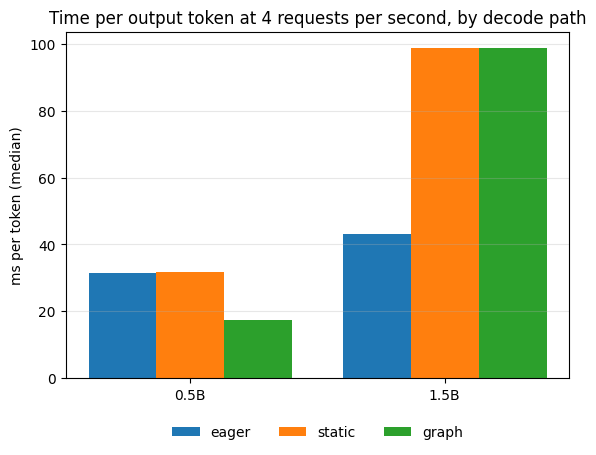

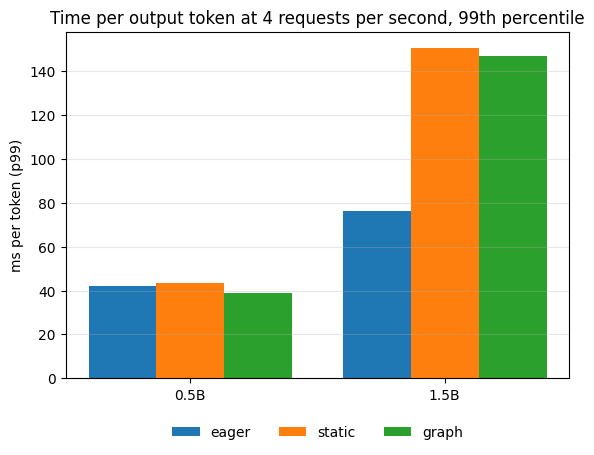

In [31]:
grouped_bar(SIZES, {m_: [modes_df[(modes_df["size"] == s) & (modes_df["mode"] == m_)].tpot_p50_ms.iloc[0] for s in SIZES] for m_ in MODES},
            f"Time per output token at {RATE_MID:g} requests per second, by decode path", "ms per token (median)", save="stage12_modes_tpot")
grouped_bar(SIZES, {m_: [modes_df[(modes_df["size"] == s) & (modes_df["mode"] == m_)].tpot_p99_ms.iloc[0] for s in SIZES] for m_ in MODES},
            f"Time per output token at {RATE_MID:g} requests per second, 99th percentile", "ms per token (p99)", save="stage12_modes_tpot_p99")

**How to read it.** `tpot_vs_eager` below 1 is faster than the eager paged step. `capture_s` is the one-time cost of capturing every bucket the trace can reach (zero for `eager` and for `static`, which has no graphs). A `graph_mode` of `static` on the `graph` row means capture failed on this system and `graph_error` has the reason; the numbers are then the eager static step's.

**What the run showed (4 requests per second).** On the 0.5B model the captured step has a median time per token of 17.6 ms against 31.6 ms for the eager step (0.56x) and 13% more tokens per second (231 against 205). The `static` control is 31.8 ms (1.01x), so on this model the gain is the graph. Capturing the 42 graphs took 4.1 s, once. On the 1.5B model the result reverses: eager 43.2 ms, static 98.7 ms (2.29x), graph 98.6 ms (2.28x); tokens per second 188, 151 and 154; and with either bucketed step only half of the requests meet the latency target, against all of them with the eager step. Capture took 5.2 s. The load table in section 4 shows where it flips. At 1 request per second the graph step wins on both models (median 10.9 against 28.5 ms on 0.5B, 24.9 against 34.6 ms on 1.5B), on the 1.5B model the two are even at 2 per second, and at 8 per second the graph step is slower on both (50 against 35 ms on 0.5B, 146 against 83 ms on 1.5B).

**Takeaway.** The prediction was half wrong: the gain of the graph did not shrink on the larger model, it reversed, and under the top load it reversed on the smaller one too. The `static` control is why this is readable. Without it the finding would be "CUDA graphs hurt", which section 5 shows to be false. The loss is the bucketed step, not the capture. The mechanism is a hypothesis (no per-step profile was saved): a bucketed step reads every block of its bucket for every row, padding rows included, and `MiniQwen` then expands the keys and values of the grouped-query heads before attention, so the bytes moved per step grow with the bucket and not with the batch. A slower step keeps more requests running, which fills a larger bucket, which makes the step slower again. Exercise 5 lists the fixes.

---
## 4. Engine against Hugging Face

**Goal:** the same trace at four arrival rates, served by the engine and by Hugging Face `generate`, measured on one clock.

**Concept.** Four systems, one trace per rate, all open loop (a request is sent at its arrival time whether or not the earlier ones are done):

- `engine eager` and `engine graph`: the engine in process, as in section 3.
- `HF sequential`: `model.generate` for one request at a time, first come first served. This is what you get from the obvious way of putting a Hugging Face model behind a queue.
- `HF static batch N`: the requests that have arrived, up to `HF_BATCH`, left-padded and generated together until the longest request in the batch has its tokens, then the queue is looked at again. This is Part 2's static batching.

The baseline is generous in two ways: Hugging Face's streamer timestamps every step, so a request counts as finished at its own last token and not when its batch returns, and end-of-sequence is suppressed so every system does exactly the same number of tokens. Both choices favour Hugging Face; the conclusions do not depend on them.

**Metrics.** TTFT (time to first token), TPOT (time per output token after the first, what a reader of the stream experiences), the 99th percentile stall between two events of a stream, request and token throughput, and **goodput**: tokens per second of the requests that met the latency target (`SLO`: a first token within two seconds and ten tokens per second after it). The **capacity** of a system is the highest tested rate at which at least nine tenths of requests meet the target.

**Fairness.** The order of the systems rotates from rate to rate so a drifting clock does not always favour the same one, and the GPU is warmed under load before each group.

**Prediction (before the run).**
1. At the lowest rate every system answers every request alone, so the time per token is set by the step time: Hugging Face is slowest, the eager engine close to it or a little faster, the graph engine fastest.
2. `HF sequential` saturates first, at about one over the mean time one request takes alone. Above that its queue grows for the whole trace: its TTFT and response time rise steeply and its goodput falls toward zero because requests miss the target while waiting.
3. `HF static batch` serves more requests per second than sequential but still saturates earlier than the engine, because a batch runs until its longest request is done and nothing joins it meanwhile.
4. The engine's TTFT stays low at every tested rate unless it saturates, its throughput rises with the rate, and its capacity under the target is the highest of the four.

In [32]:
LOAD_ROWS = []
for size, (hf_m, m) in MODELS.items():
    engines = {"engine eager": make_engine(m, **MODES["eager"]), "engine graph": make_engine(m, **MODES["graph"])}
    worst = max(RATES)
    for e in engines.values():
        run_engine(e, WARM_TRACE)
        warm(e, TRACES[worst])
    run_hf(hf_m, WARM_TRACE, max_batch=HF_BATCH, pad_id=PAD_ID, sync=sync)
    systems = {
        "engine eager": lambda tr: run_engine(engines["engine eager"], tr),
        "engine graph": lambda tr: run_engine(engines["engine graph"], tr),
        "HF sequential": lambda tr: run_hf(hf_m, tr, max_batch=1, pad_id=PAD_ID, sync=sync),
        f"HF static batch {HF_BATCH}": lambda tr: run_hf(hf_m, tr, max_batch=HF_BATCH, pad_id=PAD_ID, sync=sync),
    }
    names = list(systems)
    for i, rate in enumerate(RATES):
        trace = TRACES[rate]
        log_gpu(f"load {size} rate {rate:g}", warm=True)
        for name in names[i % len(names):] + names[:i % len(names)]:           # the order rotates from rate to rate
            res = systems[name](trace)
            row = run_row(name, res, trace, slo=SLO, size=size, rate=rate)
            LOAD_ROWS.append(row)
            print(f"{size} rate {rate:g}/s {name:18s} {row['req_s']:.2f} req/s  ttft p50 {row.get('ttft_p50_s', float('nan')):.2f} s  tpot p50 {1000 * row.get('tpot_p50_s', float('nan')):.0f} ms  "
                  f"goodput {row.get('goodput_tok_s') or 0:.0f} tok/s  errors {row['n_errors']}")
        log_gpu(f"load {size} rate {rate:g} end")
    engines.clear(); systems.clear(); free_gpu()

load_df = pd.DataFrame(LOAD_ROWS)
load_df["tpot_p50_ms"] = 1000 * load_df.tpot_p50_s
load_df["tpot_p99_ms"] = 1000 * load_df.tpot_p99_s
CAP_TARGET = 0.9
cap_rows = []
for (size, system), d in load_df.groupby(["size", "system"], sort=False):
    ok = d[d.slo_attainment >= CAP_TARGET]
    cap_rows.append(dict(size=size, system=system, capacity_req_s=float(ok.rate.max()) if len(ok) else None, target=CAP_TARGET))
capacity_df = pd.DataFrame(cap_rows)
display(load_df[["size", "system", "rate", "req_s", "out_tok_s", "ttft_p50_s", "ttft_p99_s", "tpot_p50_ms", "tpot_p99_ms", "stall_p99_s", "goodput_tok_s",
                 "slo_attainment", "n_errors"]].round(3))
capacity_df

[load 0.5B rate 1] 1065.0 MHz (max 1590.0), 77.0 C, 66.69 W of 70.0 W
0.5B rate 1/s engine eager       0.99 req/s  ttft p50 0.04 s  tpot p50 29 ms  goodput 66 tok/s  errors 0
0.5B rate 1/s engine graph       1.05 req/s  ttft p50 0.03 s  tpot p50 11 ms  goodput 70 tok/s  errors 0
0.5B rate 1/s HF sequential      0.45 req/s  ttft p50 39.01 s  tpot p50 32 ms  goodput 2 tok/s  errors 0
0.5B rate 1/s HF static batch 8  0.90 req/s  ttft p50 4.81 s  tpot p50 32 ms  goodput 18 tok/s  errors 0
[load 0.5B rate 1 end] 1365.0 MHz (max 1590.0), 76.0 C, 50.69 W of 70.0 W
[load 0.5B rate 2] 1080.0 MHz (max 1590.0), 77.0 C, 52.23 W of 70.0 W
0.5B rate 2/s engine graph       2.00 req/s  ttft p50 0.03 s  tpot p50 12 ms  goodput 134 tok/s  errors 0
0.5B rate 2/s HF sequential      0.45 req/s  ttft p50 51.86 s  tpot p50 33 ms  goodput 2 tok/s  errors 0
0.5B rate 2/s HF static batch 8  1.14 req/s  ttft p50 12.66 s  tpot p50 31 ms  goodput 4 tok/s  errors 0
0.5B rate 2/s engine eager       1.80 req/s  ttft 

,size,system,rate,req_s,out_tok_s,ttft_p50_s,ttft_p99_s,tpot_p50_ms,tpot_p99_ms,stall_p99_s,goodput_tok_s,slo_attainment,n_errors
0,0.5B,engine eager,1.0,0.989,66.235,0.044,0.076,28.532,31.426,0.055,66.235,1.000,0
1,0.5B,engine graph,1.0,1.049,70.268,0.030,0.064,10.859,15.618,0.036,70.268,1.000,0
2,0.5B,HF sequential,1.0,0.454,30.388,39.010,80.634,32.435,33.244,0.038,1.722,0.062,0
3,0.5B,HF static batch 8,1.0,0.898,60.178,4.809,14.753,31.727,34.013,0.039,17.519,0.219,0
4,0.5B,engine graph,2.0,1.997,133.796,0.033,0.062,12.314,23.134,0.046,133.796,1.000,0
5,0.5B,HF sequential,2.0,0.455,30.449,51.863,110.086,32.642,34.452,0.038,1.726,0.062,0
6,0.5B,HF static batch 8,2.0,1.143,76.541,12.656,20.886,31.328,32.683,0.036,4.339,0.062,0
7,0.5B,engine eager,2.0,1.801,120.613,0.046,0.090,29.925,34.911,0.059,120.613,1.000,0
8,0.5B,HF sequential,4.0,0.456,30.547,58.272,124.572,32.420,34.866,0.037,1.731,0.062,0
9,0.5B,HF static batch 8,4.0,1.467,98.249,14.600,27.878,31.773,34.053,0.038,7.930,0.109,0


,size,system,capacity_req_s,target
0,0.5B,engine eager,8.0,0.9
1,0.5B,engine graph,8.0,0.9
2,0.5B,HF sequential,NaN,0.9
3,0.5B,HF static batch 8,NaN,0.9
4,1.5B,engine eager,4.0,0.9
5,1.5B,engine graph,2.0,0.9
6,1.5B,HF sequential,NaN,0.9
7,1.5B,HF static batch 8,NaN,0.9


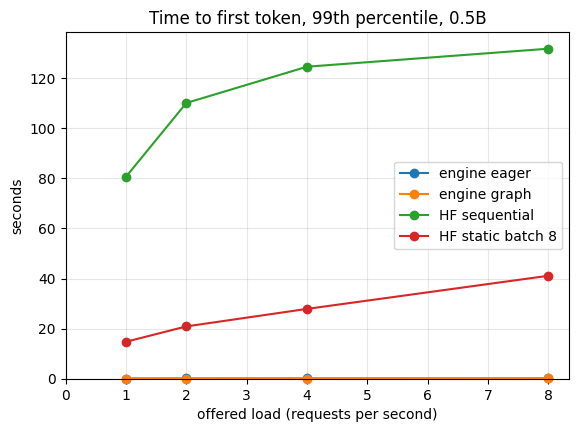

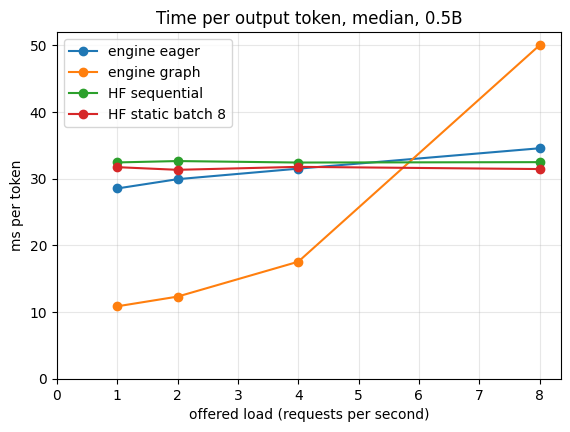

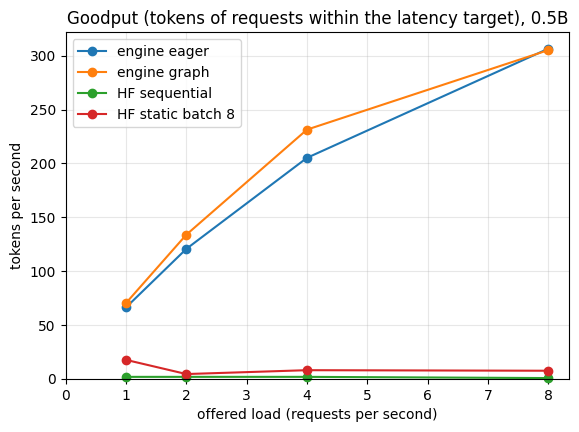

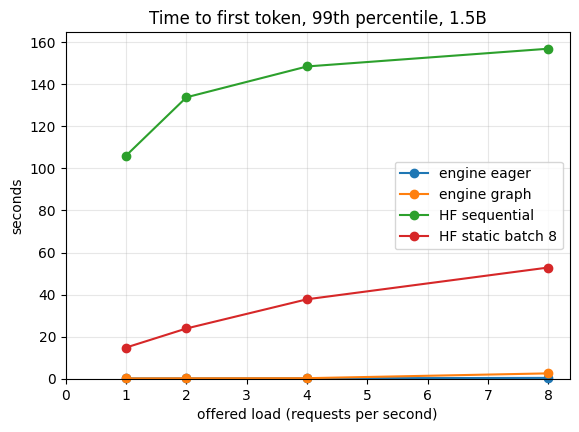

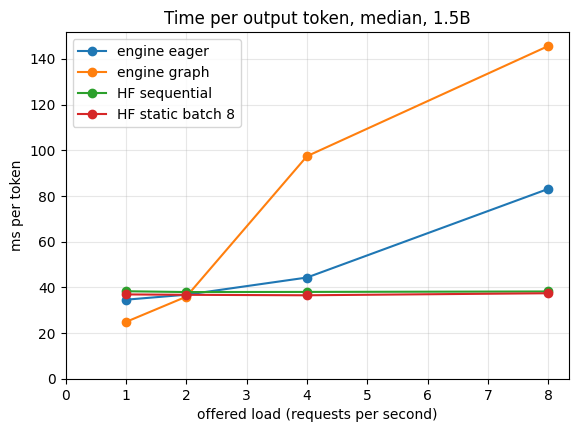

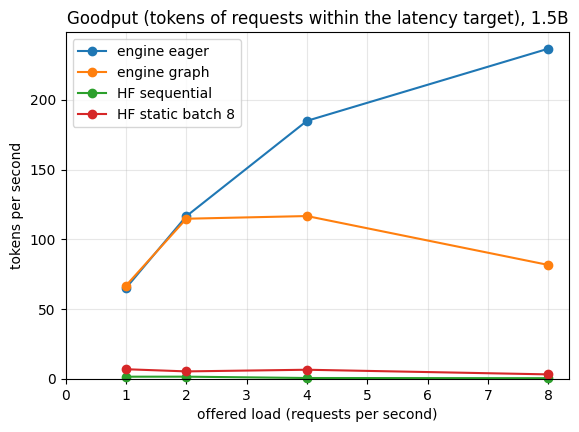

In [33]:
for size in SIZES:
    d = load_df[load_df["size"] == size]
    line_groups(d, "rate", "ttft_p99_s", "system", f"Time to first token, 99th percentile, {size}", "seconds", save=f"stage12_ttft_p99_{size.replace('.', 'p').lower()}",
                xlabel="offered load (requests per second)")
    line_groups(d, "rate", "tpot_p50_ms", "system", f"Time per output token, median, {size}", "ms per token", save=f"stage12_tpot_{size.replace('.', 'p').lower()}",
                xlabel="offered load (requests per second)")
    line_groups(d, "rate", "goodput_tok_s", "system", f"Goodput (tokens of requests within the latency target), {size}", "tokens per second",
                save=f"stage12_goodput_{size.replace('.', 'p').lower()}", xlabel="offered load (requests per second)")

**How to read it.** A system that cannot keep up with the offered load shows it three ways at once: `req_s` flattens below the arrival rate, `ttft_p99_s` climbs, and `slo_attainment` and `goodput_tok_s` fall. Judge saturation from the time to first token and from the attainment, not from the completed rate alone, which a finite trace understates. `capacity_req_s` is the highest tested rate at which at least nine tenths of requests met the target; `None` means none of the tested rates did.

**What the run showed.** Hugging Face is saturated from the lowest rate. Run one request at a time it completes 0.45 to 0.46 requests per second on the 0.5B model and 0.38 to 0.39 on the 1.5B at every offered rate from 1 to 8, so its queue grows for the whole trace: the median time to first token is 39 to 62 s on the 0.5B model and 51 to 73 s on the 1.5B, and at most 6% of requests meet the latency target. In static batches of 8 it completes 0.90 to 1.47 requests per second (0.5B) and 0.84 to 1.19 (1.5B), with a median first token at 5 to 20 s and 6 to 26 s, and 6% to 22% of requests meeting the target. The eager engine's median first token stays between 0.04 and 0.11 s at every rate (99th percentile at most 0.39 s). It meets the target for every request on the 0.5B model at every rate and on the 1.5B model up to 4 requests per second (86% at 8).

Capacity (highest tested rate with at least 90% of requests within the target): 8 for both engine paths on the 0.5B model, which is the top of the range, so its limit was not found; 4 for the eager engine and 2 for the graph engine on the 1.5B model; none for any Hugging Face setup. At 8 requests per second offered, the engine completes 4.6 (0.5B) and 3.8 (1.5B) requests per second against 1.2 and 0.93 for the better Hugging Face setup, about 4 times as many at both sizes. The graph engine's difference from the eager one is the section 3 result.

The first prediction rested on a premise that did not hold: at 1 request per second Hugging Face is already past its capacity, so no tested rate had it answering requests alone. Its time per token still ordered as predicted at that rate (32.4 ms against 28.5 ms for the eager engine and 10.9 ms for the graph engine on the 0.5B model; 38.3, 34.6 and 24.9 ms on the 1.5B).

**Takeaway.** The engine is the first system in this series that can be compared with an outside baseline on a trace, and the comparison is about scheduling and memory as much as speed: Hugging Face's step is not slow, it is that one request at a time (or one batch at a time) leaves most of the GPU's bandwidth unused and makes every other request wait. The sweep found neither Hugging Face's limit (it is below the lowest rate) nor the engine's on the smaller model (it is above the highest), so a wider range of rates is the next thing to try.

---
## 5. Latency mode

**Goal:** one request at a time, the way a developer tries a model: what is the time per token for plain decoding, for the graph, for graph plus lookup speculation, and for Hugging Face?

**Concept.** The batched engine does not speculate: a batch already shares each read of the weights across its rows, and checking drafts for every row would multiply the work. With exactly one greedy request running, the weights are read for one row, which is where speculation pays (Parts 5 and 9). The engine therefore switches on its own: speculation while one greedy request runs, the batch path as soon as a second request is running or a sampled request is.

The three workloads of Part 5 (`copy`, `code`, `open`) differ in how much of the output repeats the context, which is what the lookup feeds on. Each request is run alone, `LAT_REPEATS` times; the table reports medians. Outputs are checked against plain decoding as in section 2, so a speedup from speculation is never a speedup of a different answer.

**Prediction (before the run).** The graph engine has a lower time per token than the eager engine, more so on the smaller model. Lookup speculation is the fastest on `copy` and `code` (the output repeats the context, drafts are accepted) and about neutral on `open` (few drafts are found, and a round with no draft is an ordinary step). Hugging Face is the slowest. Every output equals plain decoding or differs at a near tie.

In [34]:
from minivllm.scheduler import Request

LAT_PROMPTS = {name: [tok(t).input_ids for t in TEXTS[name][:2]] for name in ("copy", "code", "open")}
LAT_SYSTEMS = {"engine eager": {}, "engine graph": MODES["graph"], f"engine graph + lookup k={SPEC_K}": dict(MODES["graph"], speculate_k=SPEC_K)}
REFS = {}
LAT_ROWS = []
for size, (hf_m, m) in MODELS.items():
    for name, ps in LAT_PROMPTS.items():
        for p in ps:
            REFS[(size, tuple(p))] = greedy(m, p, LAT_NEW)
    for system, kw in LAT_SYSTEMS.items():
        engine = make_engine(m, **kw)
        warm(engine, [Request(0, p, LAT_NEW, 0.0) for ps in LAT_PROMPTS.values() for p in ps])
        engine.generate([LAT_PROMPTS["open"][0]], SamplingParams(max_new=8))
        log_gpu(f"latency {size} {system}", warm=True)
        for wl, ps in LAT_PROMPTS.items():
            for pi, p in enumerate(ps):
                for rep in range(LAT_REPEATS):
                    before = dict(engine.counters)
                    o = engine.generate([p], SamplingParams(max_new=LAT_NEW))[0]
                    d = {k: engine.counters[k] - before[k] for k in before}
                    i, gap = tie_gap(m, p, REFS[(size, tuple(p))], o.tokens)
                    LAT_ROWS.append(dict(size=size, system=system, workload=wl, prompt=pi, rep=rep, ttft_s=o.ttft_s,
                                         tpot_s=(o.finish_s - o.first_token_s) / (len(o.tokens) - 1), n_tokens=len(o.tokens),
                                         exact=i is None, near_tie=(i is not None and gap < NEAR_TIE), rounds=d["spec_rounds"],
                                         drafted=d["spec_drafted"], accepted=d["spec_accepted"], plain_steps=d["decode_steps"]))
        del engine; free_gpu()
    log_gpu(f"latency {size} HF", warm=True)
    for wl, ps in LAT_PROMPTS.items():
        for pi, p in enumerate(ps):
            for rep in range(LAT_REPEATS):
                r = run_hf(hf_m, [Request(0, p, LAT_NEW, 0.0)], max_batch=1, pad_id=PAD_ID, sync=sync)[0]
                LAT_ROWS.append(dict(size=size, system="HF generate", workload=wl, prompt=pi, rep=rep, ttft_s=r.ttft_s, tpot_s=r.tpot_s, n_tokens=r.n_tokens,
                                     exact=None, near_tie=None, rounds=0, drafted=0, accepted=0, plain_steps=0))

lat_runs = pd.DataFrame(LAT_ROWS)
lat_df = lat_runs.groupby(["size", "workload", "system"], sort=False).agg(
    tpot_ms=("tpot_s", lambda x: 1000 * float(np.median(x))), ttft_ms=("ttft_s", lambda x: 1000 * float(np.median(x))),
    drafted=("drafted", "sum"), accepted=("accepted", "sum"), rounds=("rounds", "sum"), plain_steps=("plain_steps", "sum"),
    n_exact=("exact", lambda x: int(sum(1 for v in x if v is True))), n_near_tie=("near_tie", lambda x: int(sum(1 for v in x if v is True))),
    n_runs=("tpot_s", "size")).reset_index()
lat_df["accept_rate"] = lat_df.accepted / lat_df.drafted.where(lat_df.drafted > 0)
lat_df["tokens_per_step"] = (LAT_NEW - 1) * lat_df.n_runs / (lat_df.rounds + lat_df.plain_steps).where((lat_df.rounds + lat_df.plain_steps) > 0)
ref_ms = lat_df[lat_df.system == "engine eager"].set_index(["size", "workload"]).tpot_ms
lat_df["speedup_vs_eager"] = lat_df.apply(lambda r: ref_ms.loc[(r["size"], r["workload"])] / r.tpot_ms, axis=1)
LAT_BAD = lat_runs[(lat_runs.exact == False) & (lat_runs.near_tie == False)]
print("outputs that differ from plain decoding by more than a near tie:", len(LAT_BAD))
assert len(LAT_BAD) == 0, "an engine output differs from plain decoding: see LAT_BAD"
lat_df.round(3)

[latency 0.5B engine eager] 1200.0 MHz (max 1590.0), 78.0 C, 67.42 W of 70.0 W
[latency 0.5B engine graph] 1230.0 MHz (max 1590.0), 80.0 C, 66.6 W of 70.0 W
[latency 0.5B engine graph + lookup k=4] 1005.0 MHz (max 1590.0), 75.0 C, 67.09 W of 70.0 W
[latency 0.5B HF] 1290.0 MHz (max 1590.0), 76.0 C, 62.35 W of 70.0 W
[latency 1.5B engine eager] 1185.0 MHz (max 1590.0), 79.0 C, 66.69 W of 70.0 W
[latency 1.5B engine graph] 1230.0 MHz (max 1590.0), 77.0 C, 67.32 W of 70.0 W
[latency 1.5B engine graph + lookup k=4] 1185.0 MHz (max 1590.0), 77.0 C, 67.18 W of 70.0 W
[latency 1.5B HF] 1320.0 MHz (max 1590.0), 76.0 C, 67.18 W of 70.0 W
outputs that differ from plain decoding by more than a near tie: 0


,size,workload,system,tpot_ms,ttft_ms,drafted,accepted,rounds,plain_steps,n_exact,n_near_tie,n_runs,accept_rate,tokens_per_step,speedup_vs_eager
0,0.5B,copy,engine eager,27.755,26.809,0,0,0,762,6,0,6,NaN,1.000,1.000
1,0.5B,code,engine eager,27.767,26.812,0,0,0,762,6,0,6,NaN,1.000,1.000
2,0.5B,open,engine eager,27.855,26.739,0,0,0,762,6,0,6,NaN,1.000,1.000
3,0.5B,copy,engine graph,8.899,27.143,0,0,0,762,6,0,6,NaN,1.000,3.119
4,0.5B,code,engine graph,8.815,26.413,0,0,0,762,6,0,6,NaN,1.000,3.150
5,0.5B,open,engine graph,8.493,26.456,0,0,0,762,6,0,6,NaN,1.000,3.280
6,0.5B,copy,engine graph + lookup k=4,3.482,26.847,717,471,186,105,6,0,6,0.657,2.619,7.972
7,0.5B,code,engine graph + lookup k=4,3.202,26.765,834,492,213,57,6,0,6,0.590,2.822,8.672
8,0.5B,open,engine graph + lookup k=4,5.005,26.446,753,318,192,252,6,0,6,0.422,1.716,5.565
9,0.5B,copy,HF generate,32.369,39.065,0,0,0,0,0,0,6,NaN,NaN,0.857


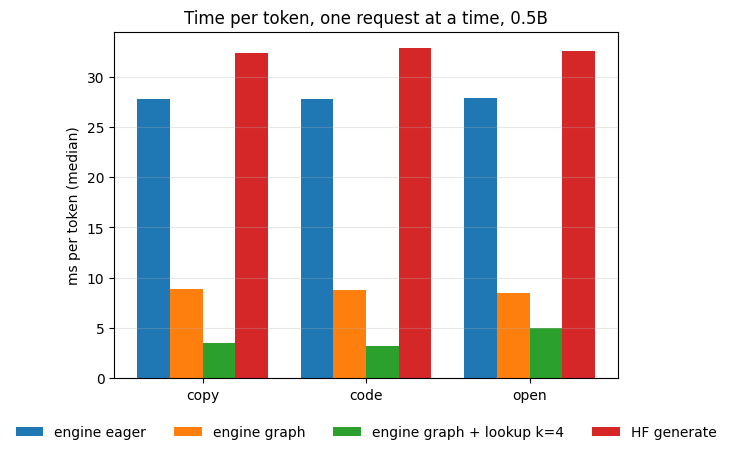

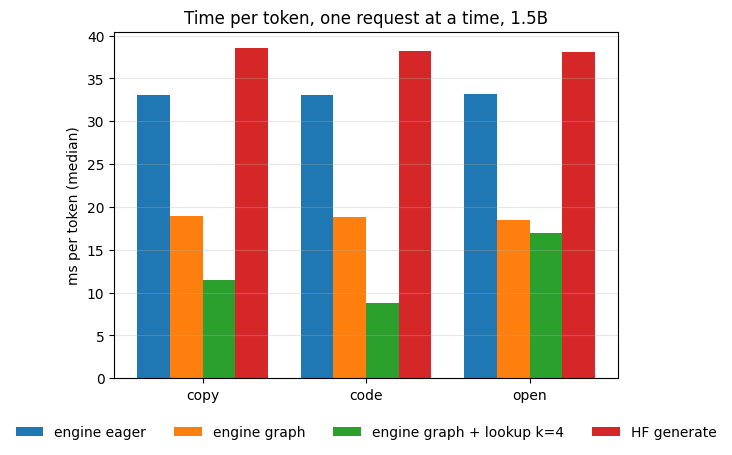

In [35]:
for size in SIZES:
    d = lat_df[lat_df["size"] == size]
    wls = list(LAT_PROMPTS)
    grouped_bar(wls, {s: [d[(d.workload == w) & (d.system == s)].tpot_ms.iloc[0] for w in wls] for s in list(LAT_SYSTEMS) + ["HF generate"]},
                f"Time per token, one request at a time, {size}", "ms per token (median)", save=f"stage12_latency_{size.replace('.', 'p').lower()}")

**How to read it.** `speedup_vs_eager` is the eager engine's time per token over the row's. `accept_rate` is accepted drafts over drafted tokens and `tokens_per_step` the tokens made per decode step (1 for plain decoding, more when drafts are accepted). `n_exact` and `n_near_tie` count the runs equal to plain decoding and those that differ only at a near tie (HF rows are not checked: the reference is the same eager decoding with the same weights, and its outputs are only used for timing).

**What the run showed.** Alone, the graph step takes the time per token from 27.8 ms to 8.5 to 8.9 ms on the 0.5B model (3.1x to 3.3x) and from 33.1 ms to 18.4 to 18.9 ms on the 1.5B (1.8x), where the weights and not the launches are more of the step. With the lookup on top: 3.5 ms on copy (8.0x the eager step), 3.2 ms on code (8.7x) and 5.0 ms on open text (5.6x) on the 0.5B model, with 66%, 59% and 42% of drafted tokens accepted and 2.6, 2.8 and 1.7 tokens per step; on the 1.5B model 11.5 ms (2.9x), 8.8 ms (3.8x) and 17.0 ms (2.0x), with 31%, 45% and 7% accepted. On open text the 1.5B lookup is about even with the graph alone (17.0 against 18.4 ms): almost nothing is accepted, and a round with no draft is an ordinary step, so it costs nothing. On the 0.5B model it still helps there (5.0 against 8.5 ms), because the open prompts contain enough repetition for 42% of the drafts to be accepted. This part of the prediction was wrong. Hugging Face `generate` takes 32.4 to 32.8 ms per token on the 0.5B model and 38.1 to 38.5 ms on the 1.5B, slower than the eager engine (27.8 to 27.9 and 33.1 to 33.2 ms) and 2.2 to 10 times slower than the engine with graph and lookup. All 108 engine runs (6 per cell) are identical to plain decoding.

**Takeaway.** Speculation is a latency tool for a lightly loaded server. The engine applies it only when it cannot hurt anyone else, and the batch path takes over without any change in the outputs.

---
## 6. The server

**Goal:** the engine behind HTTP, in its own process, driven by the same client and the same trace, and one streamed request to look at.

**Concept.** `python -m minivllm.server` loads the model, builds the engine, captures its graph buckets (`--warmup`), and serves `POST /v1/completions`. The notebook is the client: one thread per request sleeps until the request's arrival time, sends token ids, and timestamps every server-sent event. The server runs as a separate process, so the client and the server do not share a Python interpreter, which is how the vLLM comparison runs both servers too. What this section measures is the cost of the HTTP layer and the engine thread: the same engine, the same trace, the same rate as the in-process `engine graph` row of section 4.

**Prediction (before the run).** The server's numbers are close to the in-process ones: the same tokens per second at the same rate, and a time to first token a little higher (one HTTP round trip, tokenization is not involved because the client sends ids, and the engine thread picks a request up between two steps). Time per token is about the same. If the server is much worse, the cost is in the thread hand-off, not in the model.

In [36]:
SERVER_SIZE = SIZES[0]
SERVER_PORT = 8002
server_cmd = [sys.executable, "-m", "minivllm.server", "--model", MODEL_IDS[SERVER_SIZE], "--dtype", "float16", "--num-blocks", str(NUM_BLOCKS),
              "--block-size", str(BLOCK_SIZE), "--max-seqs", str(MAX_SEQS), "--max-model-len", "2048", "--graph", "--warmup", "--port", str(SERVER_PORT)]
server = ServerProcess(server_cmd, SERVER_PORT, model="minivllm", log_path="minivllm_server.log")
SERVER_ROWS, STREAM_DEMO = [], {}
try:
    t0 = time.time()
    server.start(timeout_s=900)
    SERVER_START_S = time.time() - t0
    print(f"server ready after {SERVER_START_S:.0f} s (model load, one warm-up request, graph capture)")
    log_gpu("server", warm=True)
    res = run_http(server.url, TRACES[RATE_MID], model="minivllm")
    SERVER_ROWS.append(run_row("engine graph over HTTP", res, TRACES[RATE_MID], slo=SLO, size=SERVER_SIZE, rate=RATE_MID))

    # one streamed request with text, to look at
    import http.client
    prompt_text = "The harbor town of Veldmark sits at the mouth of a narrow river. Every morning"
    conn = http.client.HTTPConnection("127.0.0.1", SERVER_PORT, timeout=120)
    conn.request("POST", "/v1/completions", body=json.dumps({"prompt": prompt_text, "max_tokens": 24, "temperature": 0.8, "seed": 1, "stream": True}),
                 headers={"Content-Type": "application/json"})
    r = conn.getresponse()
    events = [ln.decode().strip()[6:] for ln in r.read().splitlines() if ln.startswith(b"data: ")]
    conn.close()
    STREAM_DEMO = {"prompt": prompt_text, "n_events": len(events), "first_events": events[:3], "last_events": events[-2:]}
    print("streamed events:", len(events), "| the first three:")
    for e in events[:3]:
        print("  ", e[:160])
    print("   ...")
    print("  ", events[-2][:200])
finally:
    server.stop()

inproc = load_df[(load_df["size"] == SERVER_SIZE) & (load_df.rate == RATE_MID) & (load_df.system == "engine graph")].iloc[0].to_dict()
server_df = pd.DataFrame(SERVER_ROWS + [{**inproc, "system": "engine graph in process"}])
server_df["tpot_p50_ms"] = 1000 * server_df.tpot_p50_s
server_df["tpot_p99_ms"] = 1000 * server_df.tpot_p99_s
server_df[["system", "n_ok", "n_errors", "req_s", "out_tok_s", "ttft_p50_s", "ttft_p99_s", "tpot_p50_ms", "tpot_p99_ms", "stall_p99_s", "goodput_tok_s"]].round(3)

server ready after 16 s (model load, one warm-up request, graph capture)
[server] 1320.0 MHz (max 1590.0), 78.0 C, 49.34 W of 70.0 W
streamed events: 25 | the first three:
   {"id": "cmpl-64", "object": "text_completion.chunk", "choices": [{"index": 0, "tokens": [279, 14796], "finish_reason": null, "text": " the river"}]}
   {"id": "cmpl-64", "object": "text_completion.chunk", "choices": [{"index": 0, "tokens": [374], "finish_reason": null, "text": " is"}]}
   {"id": "cmpl-64", "object": "text_completion.chunk", "choices": [{"index": 0, "tokens": [279], "finish_reason": null, "text": " the"}]}
   ...
   {"id": "cmpl-64", "object": "text_completion.chunk", "choices": [{"index": 0, "tokens": [], "finish_reason": "length", "text": ""}], "usage": {"prompt_tokens": 18, "completion_tokens": 24}, "timing": 


,system,n_ok,n_errors,req_s,out_tok_s,ttft_p50_s,ttft_p99_s,tpot_p50_ms,tpot_p99_ms,stall_p99_s,goodput_tok_s
0,engine graph over HTTP,64,0,3.391,227.169,0.057,0.132,18.725,40.589,0.067,227.169
1,engine graph in process,64,0,3.455,231.448,0.035,0.082,17.545,39.339,0.059,231.448


**How to read it.** The two rows are the same engine configuration on the same trace; the difference is the HTTP layer, the thread hand-off between the server's request handlers and its engine thread, and a separate process. The streamed demo is a sampled completion (temperature and seed are in the request), printed event by event: each event carries the token ids of one engine step and the new text, and the last one has the finish reason and the usage.

**What the run showed.** The server was ready 16 s after it was started, and all 64 requests were answered. _Over HTTP_: 227 tokens per second, median first token 0.06 s (99th percentile 0.13 s), median time per token 18.7 ms (40.6 ms). _In process_: 231 tokens per second, 0.04 s (0.08 s), 17.5 ms (39.3 ms). The HTTP layer costs 2% of the throughput, about 20 ms on the first token and about 1 ms per token. The streamed demo produced 25 server-sent events.

**Takeaway.** A server is a thin layer: the engine does the work, and the layer's job is to hand requests to it and tokens back without getting in the way.

---
## 7. Save and publish

Everything that was measured goes into `results/stage12.json`, with the digest of every trace, the GPU log and the status of every CUDA graph, so a reader can tell what was run and whether the graphs were real. The generated `RESULTS.md` is built from this file.

In [37]:
ENV["model"] = ", ".join(MODEL_IDS[s] for s in SIZES)
ENV["model_revision"] = "; ".join(f"{m.split('/')[-1]} {str(h)[:8]}" for m, h in ENV.get("revisions", {}).items())
ENV["max_pos"] = MAX_POS
out = {
    "env": ENV,
    "config": {
        "seed": SEED, "quick": QUICK, "n_requests": N_REQ, "workload": WORKLOAD, "rates": RATES, "rate_mid": RATE_MID, "arrival_seed": ARRIVAL_SEED, "slo": SLO,
        "capacity_target": CAP_TARGET, "num_blocks": NUM_BLOCKS, "block_size": BLOCK_SIZE, "max_seqs": MAX_SEQS, "spec_k": SPEC_K, "hf_batch": HF_BATCH,
        "modes": {k: v for k, v in MODES.items()}, "sizes": SIZES, "latency_new_tokens": LAT_NEW, "latency_repeats": LAT_REPEATS, "parity_new_tokens": PARITY_NEW,
        "near_tie": NEAR_TIE, "server_size": SERVER_SIZE,
    },
    "traces": records(trace_df),
    "parity": {"summary": records(summary), "meta": records(pd.DataFrame(PARITY_META)), "rows": records(parity_df), "ok": PARITY_OK, "control_breaks": CONTROL_BREAKS},
    "modes": records(modes_df),
    "load": records(load_df),
    "capacity": records(capacity_df),
    "latency": records(lat_df),
    "latency_runs": records(lat_runs),
    "server": {"start_s": SERVER_START_S, "rows": records(server_df), "stream_demo": STREAM_DEMO},
    "gpu_log": GPU_LOG,
}
save_results("results/stage12.json", out)
print("saved results/stage12.json:", sorted(out))

saved results/stage12.json
saved results/stage12.json: ['capacity', 'config', 'env', 'gpu_log', 'latency', 'latency_runs', 'load', 'modes', 'parity', 'server', 'traces']


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [38]:
FIGURES = {
    "stage12_modes_tpot.png": "Median time per output token at the middle arrival rate: eager paged decode, the bucketed static step, and the same step in CUDA graphs (section 3)",
    "stage12_modes_tpot_p99.png": "99th percentile time per output token at the middle arrival rate, by decode path (section 3)",
}
for s in SIZES:
    k = s.replace(".", "p").lower()
    FIGURES[f"stage12_ttft_p99_{k}.png"] = f"Time to first token, 99th percentile, against offered load: the engine and Hugging Face, {s} (section 4)"
    FIGURES[f"stage12_tpot_{k}.png"] = f"Median time per output token against offered load, {s} (section 4)"
    FIGURES[f"stage12_goodput_{k}.png"] = f"Goodput (tokens of requests that met the latency target) against offered load, {s} (section 4)"
    FIGURES[f"stage12_latency_{k}.png"] = f"Time per token for one request at a time on three workloads: eager, graph, graph with lookup speculation, Hugging Face, {s} (section 5)"
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage12_modes_tpot.png,Median time per output token at the middle arr...
1,stage12_modes_tpot_p99.png,99th percentile time per output token at the m...
2,stage12_ttft_p99_0p5b.png,"Time to first token, 99th percentile, against ..."
3,stage12_tpot_0p5b.png,Median time per output token against offered l...
4,stage12_goodput_0p5b.png,Goodput (tokens of requests that met the laten...
5,stage12_latency_0p5b.png,Time per token for one request at a time on th...
6,stage12_ttft_p99_1p5b.png,"Time to first token, 99th percentile, against ..."
7,stage12_tpot_1p5b.png,Median time per output token against offered l...
8,stage12_goodput_1p5b.png,Goodput (tokens of requests that met the laten...
9,stage12_latency_1p5b.png,Time per token for one request at a time on th...


---
## Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [39]:
PUSH = True                              # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 12: the engine against Hugging Face"   # the only other line that differs between notebooks
FORCE_CODE = False                       # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 1750, done.        
remote: Counting objects: 100% (239/239), done.        
remote: Compressing objects: 100% (171/171), done.        
remote: Total 1750 (delta 144), reused 138 (delta 66), pack-reused 1511 (from 2)        
Receiving objects: 100% (1750/1750), 31.40 MiB | 37.78 MiB/s, done.
Resolving deltas: 100% (998/998), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 12, repo code stage 12: publishing code and results
[main 7f3df93] Stage 12: the engine against Hugging Face
 11 files changed, 1100 insertions(+), 1100 deletions(-)
Enumerating objects: 27, done.
Counting objects: 100% (27/27), done.
Delta compression using up to 4 threads
Compressing objects: 100% (14/14), done.
Writing objects: 100% (14/14), 452.75 KiB | 16.77 MiB/s, done.
Total 14 (delta 3), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.git
   204dd21.

---
## 8. Summary and lessons

In [40]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out_ = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out_.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out_)))

rows = [("Correctness", f"every greedy mode equals plain decoding up to near ties: {PARITY_OK}", f"the sampled control differs: {CONTROL_BREAKS}")]
for size in SIZES:
    g = modes_df[(modes_df["size"] == size) & (modes_df["mode"] == "graph")].iloc[0]
    s_ = modes_df[(modes_df["size"] == size) & (modes_df["mode"] == "static")].iloc[0]
    rows.append((f"Decode path, {size}", f"graph: {g.tpot_vs_eager:.2f}x the eager time per token, {g.tok_s_vs_eager:.2f}x its tokens per second",
                 f"static control {s_.tpot_vs_eager:.2f}x; capture {g.capture_s:.0f} s once; graph mode '{g.graph_mode}'"))
    for r in capacity_df[capacity_df["size"] == size].itertuples(index=False):
        rows.append((f"Capacity, {size}, {r.system}", f"{r.capacity_req_s if r.capacity_req_s is not None else 'none'} requests per second", f"highest tested rate with at least {r.target:.0%} of requests within the target"))
    for w in LAT_PROMPTS:
        best = lat_df[(lat_df["size"] == size) & (lat_df.workload == w)].sort_values("tpot_ms").iloc[0]
        rows.append((f"Latency mode, {size}, {w}", f"best: {best.system} at {best.tpot_ms:.1f} ms per token ({best.speedup_vs_eager:.2f}x eager)", "one request at a time"))
h = server_df.set_index("system")
rows.append(("Server", f"over HTTP {h.loc['engine graph over HTTP'].out_tok_s:.0f} tokens per second, in process {h.loc['engine graph in process'].out_tok_s:.0f}",
             f"median time to first token {h.loc['engine graph over HTTP'].ttft_p50_s:.2f} s against {h.loc['engine graph in process'].ttft_p50_s:.2f} s"))
show_table(rows)

| Metric | Result | Note |
|---|---|---|
| **Correctness** | every greedy mode equals plain decoding up to near ties: True | the sampled control differs: True |
| **Decode path, 0.5B** | graph: 0.56x the eager time per token, 1.13x its tokens per second | static control 1.01x; capture 4 s once; graph mode 'graph' |
| **Capacity, 0.5B, engine eager** | 8.0 requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 0.5B, engine graph** | 8.0 requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 0.5B, HF sequential** | nan requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 0.5B, HF static batch 8** | nan requests per second | highest tested rate with at least 90% of requests within the target |
| **Latency mode, 0.5B, copy** | best: engine graph + lookup k=4 at 3.5 ms per token (7.97x eager) | one request at a time |
| **Latency mode, 0.5B, code** | best: engine graph + lookup k=4 at 3.2 ms per token (8.67x eager) | one request at a time |
| **Latency mode, 0.5B, open** | best: engine graph + lookup k=4 at 5.0 ms per token (5.56x eager) | one request at a time |
| **Decode path, 1.5B** | graph: 2.28x the eager time per token, 0.82x its tokens per second | static control 2.29x; capture 5 s once; graph mode 'graph' |
| **Capacity, 1.5B, engine eager** | 4.0 requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 1.5B, engine graph** | 2.0 requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 1.5B, HF sequential** | nan requests per second | highest tested rate with at least 90% of requests within the target |
| **Capacity, 1.5B, HF static batch 8** | nan requests per second | highest tested rate with at least 90% of requests within the target |
| **Latency mode, 1.5B, copy** | best: engine graph + lookup k=4 at 11.5 ms per token (2.88x eager) | one request at a time |
| **Latency mode, 1.5B, code** | best: engine graph + lookup k=4 at 8.8 ms per token (3.76x eager) | one request at a time |
| **Latency mode, 1.5B, open** | best: engine graph + lookup k=4 at 17.0 ms per token (1.95x eager) | one request at a time |
| **Server** | over HTTP 227 tokens per second, in process 231 | median time to first token 0.06 s against 0.03 s |

### What this part showed

1. **An engine is a set of promises, and the tests are the promises.** The tokens do not depend on who else is in the batch, a request never runs out of memory half way, a finished request's blocks return at once, a stop token in the middle of an accepted speculative block ends the request there, a padding row never touches a real request's memory, and a client that goes away frees its blocks. Each is a CPU test with a tiny model (`tests/test_llm_engine.py`, `test_paged_graph.py`, `test_engine_speculation.py`, `test_server.py`), and section 2 repeats the first on the real model on the GPU before any speed is claimed.
2. **Composing the techniques needed new design, not just glue.** A CUDA graph wants static shapes and a batch of changing requests has none, so the engine rounds the batch and the block count up to buckets and masks what the rounding added. Speculation wants one sequence and the engine serves many, so it applies speculation only when it is alone. Neither is in the earlier parts, and both come from what the earlier parts measured.
3. **The comparison with Hugging Face is a comparison of scheduling and memory as much as of kernels.** `generate` runs one batch to its end; the engine runs a step at a time and changes the batch between steps.
4. **Open-loop load is the honest way to measure a server.** A client that waits for each reply before it sends the next request cannot overload anything, so it hides exactly the behaviour a server exists to handle.
5. **A technique that wins at batch one can lose in a batch.** The captured step is the best thing in latency mode (3.1x to 3.3x on the 0.5B model, up to 8.7x with the lookup) and the worst under load on the 1.5B model (2.3x slower per token at 4 requests per second). A control that runs the same step without the capture showed the loss is the buckets, and open-loop load exposed it. The two regimes need separate measurements, and an average over both would have hidden both results.
6. **Hugging Face is not slow per token, it is serial.** Alone it is within a small factor of the eager engine, and under load it is saturated from the lowest rate tested, while the engine meets the latency target at every rate on the 0.5B model.

### Questions

1. Why does the engine reserve every block a request will need at admission, and what would change if it allocated lazily?
2. A batch of three requests uses the batch-4 graph with one padding row. Where does the padding row write, and what stops it from changing a real row's output?
3. Why is `static` (buckets without the graph) in the table, and what would you conclude if it were as fast as `graph`?
4. Why does the engine not speculate when two requests are running? When would it pay anyway?
5. `HF static batch` finishes a request at its own last token here. How would its numbers change if a request counted as finished when its batch returned, and why was the generous choice made?
6. What does a closed-loop load generator hide?
7. The graph step wins at 1 request per second and loses at 8 on the same model. What would you log per step to confirm the explanation, and what does the feedback in the takeaway of section 3 predict one would see?

### Exercises

1. **Preemption.** Allocate blocks lazily and, when the pool runs dry, preempt the newest request (free its blocks, put it back at the head of the queue, recompute its prompt on re-admission). Measure what it buys at high load and what it costs in recomputation.
2. **Chunked prefill.** Split a long prompt into chunks and interleave them with decode steps, to bound the stall a prefill causes for the requests already running. Look at the 99th percentile stall in section 4 before and after.
3. **Prefix caching.** Share the blocks of identical prompt prefixes between requests (copy on write at the first block that differs). It needs reference counts in the block allocator; measure it on a trace where requests share a system prompt.
4. **A paged-attention kernel.** The gather in the decode step copies the keys and values of every running request each step. A kernel that reads the blocks in place removes the copy; the bucketed step makes the interface to it simple.
5. **Fix the batched graph step.** Three levers, one at a time, against the same traces: fold the query heads of each key-value head into the query length so the keys and values are not expanded (a decode step of one token has the same mask for every query head), use buckets finer than powers of two, and fall back to the eager paged step above a batch size. Turn on `record_steps` and save the log in the results, so the batch and the bucket of every step are visible (the engine can log them; this notebook does not turn it on).
6. **Sampling in the graph.** Sampling is outside the graph because each request has its own parameters and generator. Move the greedy rows' argmax into the graph and measure the step.
7. **Speculation for two or three requests.** Allow lookup speculation while up to `m` requests run and find the `m` where it stops paying.
8. **int8 in the engine.** `quantize_model` returns a model the engine can run unchanged. Measure the modes of section 3 with it and compare with Parts 8 to 10.
9. **Another workload.** Replace `mixed` with a workload with a long shared prefix, or with very long outputs, and see which result of section 4 moves.

### References

- Yu et al., *Orca: A Distributed Serving System for Transformer-Based Generative Models* (OSDI 2022), the origin of iteration-level (continuous) scheduling: https://www.usenix.org/conference/osdi22/presentation/yu
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180
- vLLM, the system compared with here: https://github.com/vllm-project/vllm
- Agrawal et al., *Taming Throughput-Latency Tradeoff in LLM Inference with Sarathi-Serve* (chunked prefill, exercise 2): https://arxiv.org/abs/2403.02310
- Leviathan et al., *Fast Inference from Transformers via Speculative Decoding*: https://arxiv.org/abs/2211.17192
- Saxena, *Prompt Lookup Decoding* (the n-gram guesser): https://github.com/apoorvumang/prompt-lookup-decoding
- PyTorch, *Accelerating PyTorch with CUDA Graphs*: https://pytorch.org/blog/accelerating-pytorch-with-cuda-graphs/
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785
- Hugging Face Transformers, text generation (`generate`, the baseline): https://huggingface.co/docs/transformers/main_classes/text_generation